# HW4.5 — GPU Assignment II: Training Throughput and Memory Engineering

## Personal Parameters and Reproducibility

**Question:** What are my assigned personal parameters, and how will I make the experiment reproducible?

- **SID4:** 1598
- **SEED:** 1598
- **SLICE:** 598
- **HP_ID:** 2
- **CLS_A:** 8
- **CLS_B:** 5

The same seed is used for Python, NumPy, PyTorch, dataset splitting, and model initialization so that the experiment is as reproducible as possible.

In [ ]:
import random
import numpy as np
import torch

# Personal parameters
SID4 = 1598
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

# Set random seeds
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# Improve reproducibility for CUDA operations
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("Personal parameters")
print(f"SID4  = {SID4}")
print(f"SEED  = {SEED}")
print(f"SLICE = {SLICE}")
print(f"HP_ID = {HP_ID}")
print(f"CLS_A = {CLS_A}")
print(f"CLS_B = {CLS_B}")

print("\nEnvironment")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Personal parameters
SID4  = 1598
SEED  = 1598
SLICE = 598
HP_ID = 2
CLS_A = 8
CLS_B = 5

Environment
PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: NVIDIA A100-SXM4-40GB


### Explanation

My student ID ends in 1598, so I use 1598 as the random seed. The dataset subset will begin at row 598 because `1598 mod 1000` is 598. My assigned hyperparameter arm is 2, and my two focus classes are 8 and 5.

I also set the random seed in Python, NumPy, and PyTorch. This helps make the dataset split and model training more consistent when the notebook is run again. GPU training can still have small differences because some CUDA operations are not completely deterministic.

## 1. Colab Environment Setup

**Question:** What software and hardware are being used for this experiment?

Before loading the dataset, I install the libraries needed for BERT fine-tuning, evaluation, and visualization. I also record the GPU and library versions so that the experiment can be reproduced later.

In [ ]:
# Install the main libraries needed for the assignment
%pip install -q transformers datasets accelerate evaluate scikit-learn seaborn

import platform
import importlib.metadata as metadata
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import transformers
import datasets
import accelerate

print("Environment information")
print(f"Python version:       {platform.python_version()}")
print(f"PyTorch version:      {torch.__version__}")
print(f"Transformers version: {transformers.__version__}")
print(f"Datasets version:     {datasets.__version__}")
print(f"Accelerate version:   {accelerate.__version__}")
print(f"Scikit-learn version: {sklearn.__version__}")

print("\nGPU information")
if torch.cuda.is_available():
    gpu_properties = torch.cuda.get_device_properties(0)
    print(f"GPU name: {gpu_properties.name}")
    print(f"GPU memory: {gpu_properties.total_memory / (1024**3):.2f} GB")
    print(f"CUDA version: {torch.version.cuda}")
else:
    print("No GPU was detected.")

Environment information
Python version:       3.13.16
PyTorch version:      2.11.0+cu130
Transformers version: 5.20.2
Datasets version:     4.8.5
Accelerate version:   1.15.0
Scikit-learn version: 1.6.1

GPU information
GPU name: NVIDIA A100-SXM4-40GB
GPU memory: 39.49 GB
CUDA version: 13.0


### Explanation

This experiment is running in Google Colab using an NVIDIA A100 GPU with approximately 40 GB of memory. The A100 is suitable for both BERT fine-tuning and the later vLLM inference benchmark.

I recorded the Python, PyTorch, Transformers, and other library versions because software versions can affect model behavior and performance. Keeping these details makes it easier to understand or reproduce the results later.

## 2. Load and Select the Twitter Dataset

**Question:** Which Twitter dataset is used, and what is my assigned row range?

The assignment does not name a specific Twitter dataset. For this implementation, I use the sentiment configuration of the TweetEval dataset from Hugging Face. It contains English tweets classified as negative, neutral, or positive.

I use the original training split as the ordered source dataset. Following the assignment, I begin at `SLICE = 598` and select up to 5,000 consecutive rows. Row numbers are reported using zero-based indexing.

In [ ]:
from datasets import load_dataset
import pandas as pd

# Fixed dataset source for reproducibility
DATASET_NAME = "cardiffnlp/tweet_eval"
DATASET_CONFIG = "sentiment"
DATASET_REVISION = "b0f6bf8397168a983b87508f0dfd24094eb4e360"

TRAIN_FILE_URL = (
    f"https://huggingface.co/datasets/{DATASET_NAME}/resolve/"
    f"{DATASET_REVISION}/sentiment/train/0000.parquet"
)

# Load the sentiment training data directly
source_dataset = load_dataset(
    "parquet",
    data_files={"train": TRAIN_FILE_URL}
)["train"]

# Label mapping documented by TweetEval
label_names = ["negative", "neutral", "positive"]
label_mapping = {
    0: "negative",
    1: "neutral",
    2: "positive"
}

# Select up to 5,000 consecutive rows beginning at SLICE
MAX_ROWS = 5000
start_row = SLICE
end_exclusive = min(start_row + MAX_ROWS, len(source_dataset))

if start_row >= len(source_dataset):
    raise ValueError(
        f"SLICE {start_row} is outside the dataset, "
        f"which contains {len(source_dataset)} rows."
    )

working_dataset = source_dataset.select(
    range(start_row, end_exclusive)
)
working_df = working_dataset.to_pandas()

# Preserve each row's position in the original source
working_df.insert(
    0,
    "source_row",
    range(start_row, end_exclusive)
)

# Add readable class names
working_df["sentiment"] = working_df["label"].map(label_mapping)

# Basic validation
assert len(working_df) <= MAX_ROWS
assert working_df["source_row"].iloc[0] == SLICE
assert working_df["label"].isin(label_mapping.keys()).all()
assert working_df["text"].notna().all()

print("Dataset information")
print(f"Dataset: {DATASET_NAME}")
print(f"Configuration: {DATASET_CONFIG}")
print(f"Revision: {DATASET_REVISION}")
print(f"Original training rows: {len(source_dataset):,}")
print(f"Label names: {label_names}")

print("\nAssigned subset")
print(f"First source row: {start_row}")
print(f"Last source row: {end_exclusive - 1}")
print(f"Python slice: [{start_row}:{end_exclusive}]")
print(f"Number of selected rows: {len(working_df):,}")

print("\nClass distribution")
class_summary = (
    working_df["sentiment"]
    .value_counts()
    .rename_axis("sentiment")
    .reset_index(name="count")
)
class_summary["percentage"] = (
    class_summary["count"] / len(working_df) * 100
).round(2)
display(class_summary)

print("\nFirst five selected rows")
display(working_df.head())

sentiment/train/0000.parquet: reconstructing file:   0%|          |  0.00B / 3.78MB            

sentiment/train/0000.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Dataset information
Dataset: cardiffnlp/tweet_eval
Configuration: sentiment
Revision: b0f6bf8397168a983b87508f0dfd24094eb4e360
Original training rows: 45,615
Label names: ['negative', 'neutral', 'positive']

Assigned subset
First source row: 598
Last source row: 5597
Python slice: [598:5598]
Number of selected rows: 5,000

Class distribution


,sentiment,count,percentage
0,neutral,2292,45.84
1,positive,1932,38.64
2,negative,776,15.52



First five selected rows


,source_row,text,label,sentiment
0,598,How long am I going to have to wait for Naruto...,1,neutral
1,599,It's the first Football Friday of the year. Th...,2,positive
2,600,@user although that may be true I will never b...,1,neutral
3,601,"""David Price felt good even into 8th inning. T...",1,neutral
4,602,"""#Maltese dognapping; assault at Dunkin' GoNut...",0,negative


### Explanation

I used the sentiment section of TweetEval because the assignment asks for a BERT sentiment classifier on Twitter data but does not provide a specific dataset. The dataset has three classes: negative, neutral, and positive.

My assigned subset starts at source row 598. I selected 5,000 consecutive rows, so the subset covers rows 598 through 5,597 using zero-based indexing. I also saved each original row number so that the exact source of every example can be traced later.

## 3. Split the Working Dataset

**Question:** How is the selected dataset divided into training, validation, and test sets?

I split the 5,000 selected tweets into 70% training, 15% validation, and 15% testing data. I use `SEED = 1598` and stratification so that each split keeps approximately the same percentage of negative, neutral, and positive tweets.

In [ ]:
from sklearn.model_selection import train_test_split

# First split: 70% training and 30% temporary data
train_df, temporary_df = train_test_split(
    working_df,
    test_size=0.30,
    random_state=SEED,
    shuffle=True,
    stratify=working_df["label"]
)

# Second split: divide the temporary data equally
# This produces 15% validation and 15% test data
validation_df, test_df = train_test_split(
    temporary_df,
    test_size=0.50,
    random_state=SEED,
    shuffle=True,
    stratify=temporary_df["label"]
)

# Reset DataFrame indices without changing source_row
train_df = train_df.reset_index(drop=True)
validation_df = validation_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Verify sizes and ensure no source row appears in multiple splits
assert len(train_df) + len(validation_df) + len(test_df) == len(working_df)

train_rows = set(train_df["source_row"])
validation_rows = set(validation_df["source_row"])
test_rows = set(test_df["source_row"])

assert train_rows.isdisjoint(validation_rows)
assert train_rows.isdisjoint(test_rows)
assert validation_rows.isdisjoint(test_rows)

print("Split sizes")
print(f"Training:   {len(train_df):,} rows ({len(train_df)/len(working_df)*100:.1f}%)")
print(f"Validation: {len(validation_df):,} rows ({len(validation_df)/len(working_df)*100:.1f}%)")
print(f"Test:       {len(test_df):,} rows ({len(test_df)/len(working_df)*100:.1f}%)")

# Create one class-distribution table for all three splits
distribution_rows = []

for split_name, split_df in [
    ("Training", train_df),
    ("Validation", validation_df),
    ("Test", test_df)
]:
    counts = split_df["sentiment"].value_counts()

    for class_name in label_names:
        count = counts.get(class_name, 0)
        distribution_rows.append({
            "split": split_name,
            "sentiment": class_name,
            "count": count,
            "percentage": round(count / len(split_df) * 100, 2)
        })

split_distribution = pd.DataFrame(distribution_rows)

print("\nClass distribution in each split")
display(split_distribution)

print("\nSplit verification passed:")
print("- All 5,000 rows were assigned.")
print("- No source row appears in more than one split.")

Split sizes
Training:   3,500 rows (70.0%)
Validation: 750 rows (15.0%)
Test:       750 rows (15.0%)

Class distribution in each split


,split,sentiment,count,percentage
0,Training,negative,543,15.51
1,Training,neutral,1604,45.83
2,Training,positive,1353,38.66
3,Validation,negative,116,15.47
4,Validation,neutral,344,45.87
5,Validation,positive,290,38.67
6,Test,negative,117,15.60
7,Test,neutral,344,45.87
8,Test,positive,289,38.53



Split verification passed:
- All 5,000 rows were assigned.
- No source row appears in more than one split.


### Explanation

The data contains 3,500 training examples, 750 validation examples, and 750 test examples. The training set will be used to update the BERT model, while the validation set will help track performance after every epoch. The test set will remain unused during training and will provide the final evaluation.

I used a stratified split because the classes are not evenly balanced. Negative tweets make up a much smaller part of the dataset than neutral and positive tweets. Stratification keeps this imbalance similar across all three splits and prevents one split from receiving an unusual number of examples from a class.

## 4. Initialize the BERT Tokenizer and Inspect Token Lengths

**Question:** Which BERT tokenizer will be used, and what maximum sequence length is suitable for the tweets?

I use the uncased BERT base tokenizer because the assignment specifically requires `BertTokenizer`. Before padding or truncating the tweets, I inspect their token lengths to choose a reasonable maximum sequence length.

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer: google-bert/bert-base-uncased
Tokenizer vocabulary size: 30,522
Number of tweets checked: 5,000
Minimum token length: 7
Mean token length: 29.86
50th percentile: 30 tokens
75th percentile: 35 tokens
90th percentile: 40 tokens
95th percentile: 43 tokens
99th percentile: 52 tokens
Maximum token length: 76

Tweets longer than 128 tokens: 0
Percentage longer than 128: 0.00%


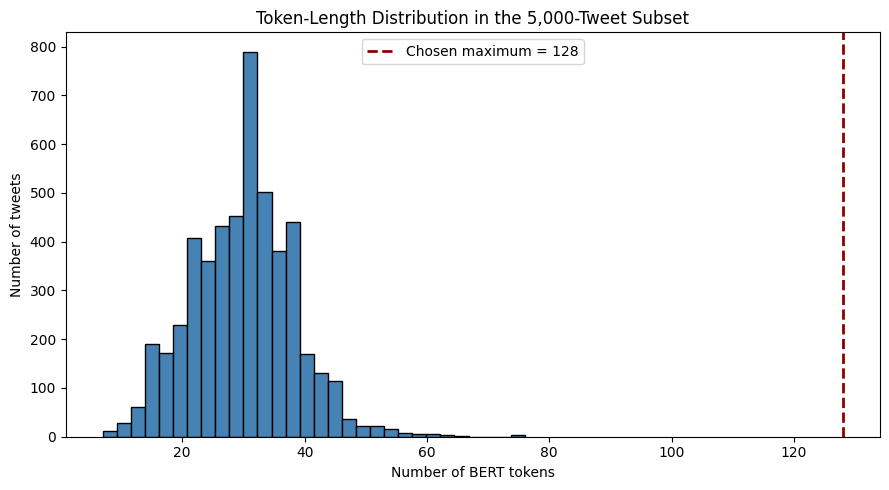

In [ ]:
from transformers import BertTokenizer
import numpy as np
import matplotlib.pyplot as plt

MODEL_NAME = "google-bert/bert-base-uncased"

# Load the tokenizer required by the assignment
tokenizer = BertTokenizer.from_pretrained(MODEL_NAME)

# Tokenize without padding or truncation to inspect natural lengths
untruncated_tokens = tokenizer(
    working_df["text"].astype(str).tolist(),
    add_special_tokens=True,
    padding=False,
    truncation=False
)

token_lengths = np.array([
    len(token_ids)
    for token_ids in untruncated_tokens["input_ids"]
])

# Display useful length statistics
percentiles = [50, 75, 90, 95, 99]

print(f"Tokenizer: {MODEL_NAME}")
print(f"Tokenizer vocabulary size: {tokenizer.vocab_size:,}")
print(f"Number of tweets checked: {len(token_lengths):,}")
print(f"Minimum token length: {token_lengths.min()}")
print(f"Mean token length: {token_lengths.mean():.2f}")

for percentile in percentiles:
    value = np.percentile(token_lengths, percentile)
    print(f"{percentile}th percentile: {value:.0f} tokens")

print(f"Maximum token length: {token_lengths.max()}")

# Candidate maximum length
MAX_LENGTH = 128
long_tweet_count = int((token_lengths > MAX_LENGTH).sum())
long_tweet_percentage = long_tweet_count / len(token_lengths) * 100

print(f"\nTweets longer than {MAX_LENGTH} tokens: {long_tweet_count}")
print(f"Percentage longer than {MAX_LENGTH}: {long_tweet_percentage:.2f}%")

# Plot the token-length distribution
plt.figure(figsize=(9, 5))
plt.hist(token_lengths, bins=30, color="steelblue", edgecolor="black")
plt.axvline(
    MAX_LENGTH,
    color="darkred",
    linestyle="--",
    linewidth=2,
    label=f"Chosen maximum = {MAX_LENGTH}"
)
plt.xlabel("Number of BERT tokens")
plt.ylabel("Number of tweets")
plt.title("Token-Length Distribution in the 5,000-Tweet Subset")
plt.legend()
plt.tight_layout()
plt.show()

### Explanation

The tweets are short after BERT tokenization. The average tweet contains about 30 tokens, 99% contain 52 tokens or fewer, and the longest contains 76 tokens.

I use a maximum sequence length of 128 tokens. This length covers every tweet in the selected dataset, so no information is lost through truncation. It also gives every example the same tensor shape, which makes batching and later memory comparisons consistent.

## 5. Create Tensor Datasets and Data Loaders

**Question:** How are the tweets converted into tensors for BERT training?

Each tweet is converted into token IDs and an attention mask. The token IDs identify the BERT vocabulary tokens, while the attention mask separates real tokens from padding. The sentiment labels are also converted into PyTorch tensors.

I use a physical batch size of 16 as the HW4 baseline. This setting will remain unchanged when the baseline is reused in HW4.5.

In [ ]:
from torch.utils.data import TensorDataset, DataLoader

MAX_LENGTH = 128
BATCH_SIZE = 16

def create_tensor_dataset(dataframe, tokenizer, max_length):
    """Tokenize text and return a PyTorch TensorDataset."""

    encoded = tokenizer(
        dataframe["text"].astype(str).tolist(),
        add_special_tokens=True,
        max_length=max_length,
        padding="max_length",
        truncation=True,
        return_attention_mask=True,
        return_tensors="pt"
    )

    labels = torch.tensor(
        dataframe["label"].to_numpy(),
        dtype=torch.long
    )

    return TensorDataset(
        encoded["input_ids"],
        encoded["attention_mask"],
        labels
    )

# Create one tensor dataset for each split
train_dataset = create_tensor_dataset(
    train_df, tokenizer, MAX_LENGTH
)
validation_dataset = create_tensor_dataset(
    validation_df, tokenizer, MAX_LENGTH
)
test_dataset = create_tensor_dataset(
    test_df, tokenizer, MAX_LENGTH
)

# Use a seeded generator for reproducible training shuffling
train_generator = torch.Generator()
train_generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=train_generator
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Inspect tensor and batch shapes
sample_input_ids, sample_attention_mask, sample_label = train_dataset[0]
first_batch = next(iter(train_loader))

print("Baseline preprocessing settings")
print(f"Maximum sequence length: {MAX_LENGTH}")
print(f"Physical batch size: {BATCH_SIZE}")

print("\nTensor dataset sizes")
print(f"Training examples:   {len(train_dataset):,}")
print(f"Validation examples: {len(validation_dataset):,}")
print(f"Test examples:       {len(test_dataset):,}")

print("\nNumber of batches")
print(f"Training batches:   {len(train_loader)}")
print(f"Validation batches: {len(validation_loader)}")
print(f"Test batches:       {len(test_loader)}")

print("\nOne training example")
print(f"Input ID shape:       {sample_input_ids.shape}")
print(f"Attention-mask shape: {sample_attention_mask.shape}")
print(f"Label shape:          {sample_label.shape}")
print(f"Label value:          {sample_label.item()}")
print(f"Label name:           {label_names[sample_label.item()]}")

print("\nFirst batch")
print(f"Input IDs:      {first_batch[0].shape}")
print(f"Attention mask: {first_batch[1].shape}")
print(f"Labels:         {first_batch[2].shape}")

# Verify all tensor dimensions
assert first_batch[0].shape[1] == MAX_LENGTH
assert first_batch[1].shape == first_batch[0].shape
assert first_batch[2].ndim == 1

print("\nTensor-shape verification passed.")

Baseline preprocessing settings
Maximum sequence length: 128
Physical batch size: 16

Tensor dataset sizes
Training examples:   3,500
Validation examples: 750
Test examples:       750

Number of batches
Training batches:   219
Validation batches: 47
Test batches:       47

One training example
Input ID shape:       torch.Size([128])
Attention-mask shape: torch.Size([128])
Label shape:          torch.Size([])
Label value:          2
Label name:           positive

First batch
Input IDs:      torch.Size([16, 128])
Attention mask: torch.Size([16, 128])
Labels:         torch.Size([16])

Tensor-shape verification passed.


### Explanation

The tokenized training, validation, and test datasets contain 3,500, 750, and 750 examples. Each input is represented by 128 token IDs and a matching 128-value attention mask.

A full training batch has the shape `[16, 128]`, which means it contains 16 tweets with 128 token positions each. The label tensor has shape `[16]`, providing one sentiment class for each tweet. The shape checks passed, so these tensors are ready for BERT.

## 6. Initialize BERT and Define the Baseline Settings

**Question:** Which BERT model and training hyperparameters are used for fine-tuning?

I initialize `BertForSequenceClassification` from the uncased BERT base checkpoint and replace its classification head with a three-class output layer.

The assignment does not provide numerical baseline hyperparameters, so I document the following implementation choices:

- Model: `google-bert/bert-base-uncased`
- Maximum sequence length: 128
- Physical batch size: 16
- Epochs: 4
- Learning rate: 0.00002
- Weight decay: 0.01
- Warmup: 10% of training steps
- Optimizer: AdamW
- Precision: full 32-bit floating point

These settings form the unchanged HW4 baseline for the later HW4.5 comparisons.

In [ ]:
from transformers import (
    BertForSequenceClassification,
    get_linear_schedule_with_warmup
)
from torch.optim import AdamW
import random
import numpy as np

# Baseline training settings
NUM_LABELS = 3
EPOCHS = 4
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.10

# Reset seeds immediately before model initialization
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# Keep the HW4 baseline in full FP32 precision
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

id2label = {
    0: "negative",
    1: "neutral",
    2: "positive"
}
label2id = {
    name: index
    for index, name in id2label.items()
}

# Initialize BERT with a new three-class classification head
model = BertForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    id2label=id2label,
    label2id=label2id
)

model = model.to(device)
model = model.float()

# Create the optimizer
optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Create a linear learning-rate scheduler
total_training_steps = len(train_loader) * EPOCHS
warmup_steps = int(total_training_steps * WARMUP_RATIO)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

# Count model parameters
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)
trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

# Save settings for later reporting
baseline_settings = {
    "model": MODEL_NAME,
    "max_length": MAX_LENGTH,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "warmup_ratio": WARMUP_RATIO,
    "precision": "FP32",
    "seed": SEED
}

print("Model initialization complete")
print(f"Device: {device}")

if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

print(f"Model: {MODEL_NAME}")
print(f"Number of classes: {NUM_LABELS}")
print(f"Labels: {id2label}")
print(f"Total parameters: {total_parameters:,}")
print(f"Trainable parameters: {trainable_parameters:,}")

print("\nBaseline training settings")
for setting, value in baseline_settings.items():
    print(f"{setting}: {value}")

print(f"Total training steps: {total_training_steps}")
print(f"Warmup steps: {warmup_steps}")

# Verify that model parameters are stored in FP32
parameter_dtype = next(model.parameters()).dtype
print(f"Model parameter dtype: {parameter_dtype}")

assert parameter_dtype == torch.float32
assert model.config.num_labels == NUM_LABELS

print("\nModel verification passed.")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model initialization complete
Device: cuda
GPU: NVIDIA A100-SXM4-40GB
Model: google-bert/bert-base-uncased
Number of classes: 3
Labels: {0: 'negative', 1: 'neutral', 2: 'positive'}
Total parameters: 109,484,547
Trainable parameters: 109,484,547

Baseline training settings
model: google-bert/bert-base-uncased
max_length: 128
batch_size: 16
epochs: 4
learning_rate: 2e-05
weight_decay: 0.01
warmup_ratio: 0.1
precision: FP32
seed: 1598
Total training steps: 876
Warmup steps: 87
Model parameter dtype: torch.float32

Model verification passed.


### Explanation

The model contains about 109.5 million trainable parameters and is running on the NVIDIA A100 GPU. The original BERT checkpoint includes layers used during BERT pretraining that are not needed for sentiment classification, so Transformers reports them as unexpected.

The new classifier layer is reported as missing because it was not part of the original checkpoint. This is expected: its weights were randomly initialized using my seed and will be learned from the Twitter training data. The model is using FP32 precision as required for the baseline comparison.

## 7. Fine-Tune BERT and Measure Training Performance

**Question:** How does the model perform during each training epoch, and what are its time and GPU-memory costs?

I fine-tune BERT for four epochs. After every epoch, I record training loss, validation loss, validation accuracy, training time, and validation time. I also measure the complete wall-clock time and peak GPU memory used by the fine-tuning run.

In [ ]:
import time
import pandas as pd
from tqdm.auto import tqdm
from torch.nn.utils import clip_grad_norm_

def evaluate_on_loader(model, data_loader, device):
    """Return average loss and accuracy for a data loader."""

    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    with torch.inference_mode():
        for input_ids, attention_mask, labels in data_loader:
            input_ids = input_ids.to(device)
            attention_mask = attention_mask.to(device)
            labels = labels.to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            batch_size = labels.size(0)
            total_loss += outputs.loss.item() * batch_size

            predictions = outputs.logits.argmax(dim=1)
            total_correct += (predictions == labels).sum().item()
            total_examples += batch_size

    average_loss = total_loss / total_examples
    accuracy = total_correct / total_examples

    return average_loss, accuracy


# Clear unused cached memory before measurement
if device.type == "cuda":
    torch.cuda.empty_cache()
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()

training_history = []

if device.type == "cuda":
    torch.cuda.synchronize()

full_training_start = time.perf_counter()

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_train_loss = 0.0
    training_examples_seen = 0

    if device.type == "cuda":
        torch.cuda.synchronize()

    epoch_train_start = time.perf_counter()

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch}/{EPOCHS}",
        leave=False
    )

    for input_ids, attention_mask, labels in progress_bar:
        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        loss.backward()

        # Limit unusually large gradients
        clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()
        scheduler.step()

        current_batch_size = labels.size(0)
        total_train_loss += loss.item() * current_batch_size
        training_examples_seen += current_batch_size

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    if device.type == "cuda":
        torch.cuda.synchronize()

    epoch_train_time = time.perf_counter() - epoch_train_start
    average_train_loss = total_train_loss / training_examples_seen

    # Validation timing
    if device.type == "cuda":
        torch.cuda.synchronize()

    validation_start = time.perf_counter()

    validation_loss, validation_accuracy = evaluate_on_loader(
        model,
        validation_loader,
        device
    )

    if device.type == "cuda":
        torch.cuda.synchronize()

    validation_time = time.perf_counter() - validation_start
    train_throughput = training_examples_seen / epoch_train_time

    epoch_results = {
        "epoch": epoch,
        "train_loss": average_train_loss,
        "validation_loss": validation_loss,
        "validation_accuracy": validation_accuracy,
        "train_time_seconds": epoch_train_time,
        "validation_time_seconds": validation_time,
        "train_samples_per_second": train_throughput
    }

    training_history.append(epoch_results)

    print(
        f"Epoch {epoch}: "
        f"train loss={average_train_loss:.4f}, "
        f"validation loss={validation_loss:.4f}, "
        f"validation accuracy={validation_accuracy:.4f}, "
        f"train time={epoch_train_time:.2f}s"
    )

if device.type == "cuda":
    torch.cuda.synchronize()

total_wall_clock_time = time.perf_counter() - full_training_start

if device.type == "cuda":
    peak_gpu_memory_gb = (
        torch.cuda.max_memory_allocated() / (1024 ** 3)
    )
    peak_reserved_memory_gb = (
        torch.cuda.max_memory_reserved() / (1024 ** 3)
    )
else:
    peak_gpu_memory_gb = float("nan")
    peak_reserved_memory_gb = float("nan")

history_df = pd.DataFrame(training_history)

# Identify the epoch with the lowest validation loss
best_epoch_index = history_df["validation_loss"].idxmin()
best_validation_epoch = int(
    history_df.loc[best_epoch_index, "epoch"]
)
best_validation_loss = float(
    history_df.loc[best_epoch_index, "validation_loss"]
)
best_validation_accuracy = float(
    history_df.loc[best_epoch_index, "validation_accuracy"]
)

# Time spent after the best validation epoch
extra_training_time = history_df.loc[
    history_df["epoch"] > best_validation_epoch,
    "train_time_seconds"
].sum()

print("\nPer-epoch results")
display(
    history_df.style.format({
        "train_loss": "{:.4f}",
        "validation_loss": "{:.4f}",
        "validation_accuracy": "{:.4f}",
        "train_time_seconds": "{:.2f}",
        "validation_time_seconds": "{:.2f}",
        "train_samples_per_second": "{:.2f}"
    })
)

print("\nHW4 baseline measurements")
print(f"Best validation epoch: {best_validation_epoch}")
print(f"Best validation loss: {best_validation_loss:.4f}")
print(f"Accuracy at best-loss epoch: {best_validation_accuracy:.4f}")
print(f"Training time after best epoch: {extra_training_time:.2f} seconds")
print(f"Total wall-clock time: {total_wall_clock_time:.2f} seconds")
print(f"Peak allocated GPU memory: {peak_gpu_memory_gb:.3f} GB")
print(f"Peak reserved GPU memory: {peak_reserved_memory_gb:.3f} GB")

Epoch 1/4:   0%|          | 0/219 [00:00<?, ?it/s]

Epoch 1: train loss=0.9124, validation loss=0.7528, validation accuracy=0.6587, train time=19.72s


Epoch 2/4:   0%|          | 0/219 [00:00<?, ?it/s]

Epoch 2: train loss=0.6196, validation loss=0.7518, validation accuracy=0.6907, train time=18.27s


Epoch 3/4:   0%|          | 0/219 [00:00<?, ?it/s]

Epoch 3: train loss=0.3898, validation loss=0.8437, validation accuracy=0.6800, train time=18.24s


Epoch 4/4:   0%|          | 0/219 [00:00<?, ?it/s]

Epoch 4: train loss=0.2325, validation loss=0.9424, validation accuracy=0.6747, train time=18.30s

Per-epoch results


,epoch,train_loss,validation_loss,validation_accuracy,train_time_seconds,validation_time_seconds,train_samples_per_second
0,1,0.9124,0.7528,0.6587,19.72,1.27,177.50
1,2,0.6196,0.7518,0.6907,18.27,1.23,191.60
2,3,0.3898,0.8437,0.6800,18.24,1.23,191.87
3,4,0.2325,0.9424,0.6747,18.30,1.23,191.26



HW4 baseline measurements
Best validation epoch: 2
Best validation loss: 0.7518
Accuracy at best-loss epoch: 0.6907
Training time after best epoch: 36.54 seconds
Total wall-clock time: 79.49 seconds
Peak allocated GPU memory: 2.478 GB
Peak reserved GPU memory: 2.863 GB


## 8. Training Curves and Validation Behavior

**Question:** At which epoch did validation performance stop improving, and what was the cost of continuing training?

I compare training loss, validation loss, and validation accuracy across all four epochs. The epoch with the lowest validation loss is treated as the best validation epoch.

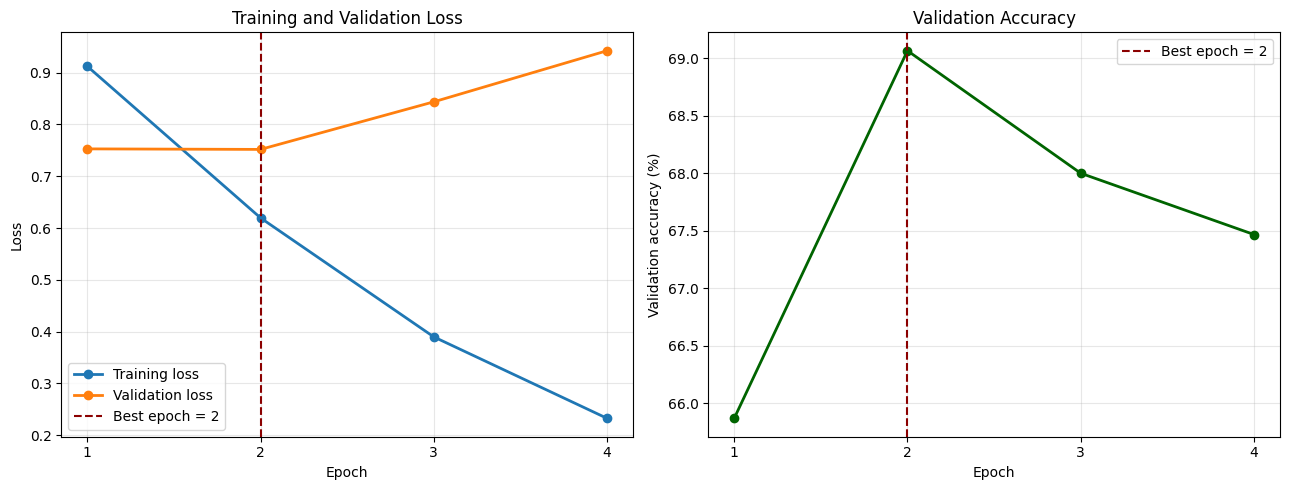

Best validation epoch: 2
Extra epochs trained: 2
Extra wall-clock time after the best epoch: 39.00 seconds
Training-curve figure saved to: /content/training_curves.png


In [ ]:
import matplotlib.pyplot as plt

# Include both training and validation time after the best epoch
extra_wall_time_after_best = history_df.loc[
    history_df["epoch"] > best_validation_epoch,
    ["train_time_seconds", "validation_time_seconds"]
].sum().sum()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Loss curves
axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    linewidth=2,
    label="Training loss"
)
axes[0].plot(
    history_df["epoch"],
    history_df["validation_loss"],
    marker="o",
    linewidth=2,
    label="Validation loss"
)
axes[0].axvline(
    best_validation_epoch,
    color="darkred",
    linestyle="--",
    label=f"Best epoch = {best_validation_epoch}"
)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Training and Validation Loss")
axes[0].set_xticks(history_df["epoch"])
axes[0].legend()
axes[0].grid(alpha=0.3)

# Validation accuracy curve
axes[1].plot(
    history_df["epoch"],
    history_df["validation_accuracy"] * 100,
    marker="o",
    color="darkgreen",
    linewidth=2
)
axes[1].axvline(
    best_validation_epoch,
    color="darkred",
    linestyle="--",
    label=f"Best epoch = {best_validation_epoch}"
)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation accuracy (%)")
axes[1].set_title("Validation Accuracy")
axes[1].set_xticks(history_df["epoch"])
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

# Save the required figure as an assignment artifact
TRAINING_CURVE_PATH = "/content/training_curves.png"
plt.savefig(
    TRAINING_CURVE_PATH,
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print(f"Best validation epoch: {best_validation_epoch}")
print(f"Extra epochs trained: {EPOCHS - best_validation_epoch}")
print(
    "Extra wall-clock time after the best epoch: "
    f"{extra_wall_time_after_best:.2f} seconds"
)
print(f"Training-curve figure saved to: {TRAINING_CURVE_PATH}")

### Results and Explanation

| Epoch | Training loss | Validation loss | Validation accuracy | Training time |
|---:|---:|---:|---:|---:|
| 1 | 0.9124 | 0.7528 | 65.87% | 19.72 s |
| 2 | 0.6196 | 0.7518 | 69.07% | 18.27 s |
| 3 | 0.3898 | 0.8437 | 68.00% | 18.24 s |
| 4 | 0.2325 | 0.9424 | 67.47% | 18.30 s |

Validation performance stopped improving after epoch 2. At that point, validation loss was 0.7518 and validation accuracy was 69.07%. During epochs 3 and 4, training loss continued to decrease, but validation loss increased and accuracy declined. This shows that the model was starting to memorize the training data instead of improving on unseen data.

Training for two epochs beyond the best epoch cost approximately 39 seconds when their training and validation time are combined. The complete four-epoch run took 79.49 seconds. Its peak allocated GPU memory was 2.478 GB, while PyTorch reserved a peak of 2.863 GB. I use 2.478 GB as the main peak-memory baseline because it represents memory actively allocated to tensors.

## 9. Test-Set Evaluation and Class Behavior

**Question:** How well does the fine-tuned model perform on unseen test data, and which sentiment class performs worst?

I evaluate the final four-epoch model on the untouched test set. I report test loss, overall accuracy, a confusion matrix, and precision, recall, and F1-score for each sentiment class.

I define the worst class as the class with the lowest recall. Recall measures how many examples belonging to a class the model successfully identifies.

Final four-epoch model test results
Test loss: 0.9031
Test accuracy: 0.6947 (69.47%)

Per-class metrics


,precision,recall,f1-score,support
negative,0.6230,0.6496,0.6360,117
neutral,0.6870,0.7209,0.7035,344
positive,0.7378,0.6817,0.7086,289



Aggregate metrics


,precision,recall,f1-score,support
accuracy,0.6947,0.6947,0.6947,1
macro avg,0.6826,0.6841,0.6827,750
weighted avg,0.6966,0.6947,0.6950,750


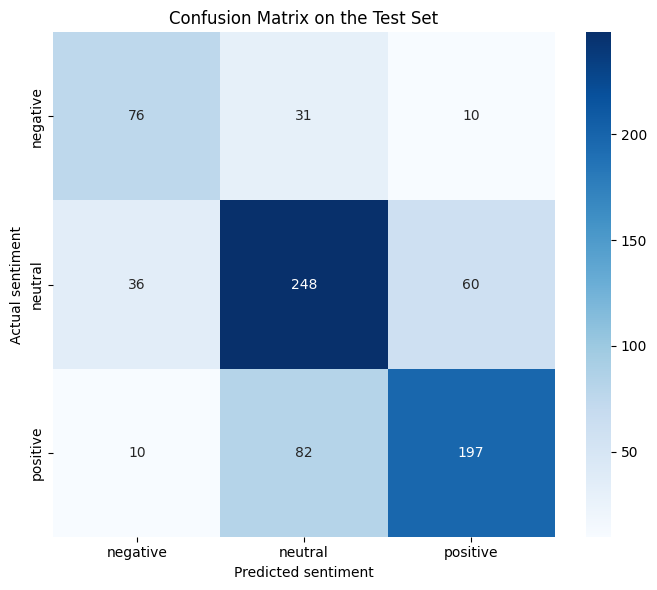


Worst class by recall: negative
Worst-class recall: 0.6496
Confusion matrix saved to: /content/confusion_matrix.png

Five misclassified examples from the worst class

Example 1
Source row: 2044
Actual: negative
Predicted: positive
Confidence: 0.9816
Tweet: Why are the regular Thursday night shows not on tonight? I was really looking forward to Parks and Rec. :(

Example 2
Source row: 2097
Actual: negative
Predicted: positive
Confidence: 0.9806
Tweet: "This game has fantasy value, I hate the Cowboys, but I need them to do big things. Romo, Austin & Dallas D c'mon!!"

Example 3
Source row: 5144
Actual: negative
Predicted: neutral
Confidence: 0.9757
Tweet: @user Hi, was offered the 6 months free Netflix last Tuesday and was told it takes 5 days to receive a code but haven't got anything"

Example 4
Source row: 4108
Actual: negative
Predicted: positive
Confidence: 0.9734
Tweet: This Rahul Gandhi aka Raul Vinci needs his bags checked no matter where he goes #interpol  May find some goodies

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

model.eval()

all_true_labels = []
all_predicted_labels = []
all_confidences = []

total_test_loss = 0.0
total_test_examples = 0

with torch.inference_mode():
    for input_ids, attention_mask, labels in test_loader:
        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        labels = labels.to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        probabilities = torch.softmax(outputs.logits, dim=1)
        confidences, predictions = probabilities.max(dim=1)

        batch_size = labels.size(0)
        total_test_loss += outputs.loss.item() * batch_size
        total_test_examples += batch_size

        all_true_labels.extend(labels.cpu().numpy())
        all_predicted_labels.extend(predictions.cpu().numpy())
        all_confidences.extend(confidences.cpu().numpy())

all_true_labels = np.array(all_true_labels)
all_predicted_labels = np.array(all_predicted_labels)
all_confidences = np.array(all_confidences)

test_loss = total_test_loss / total_test_examples
test_accuracy = accuracy_score(
    all_true_labels,
    all_predicted_labels
)

# Per-class and aggregate metrics
report_dictionary = classification_report(
    all_true_labels,
    all_predicted_labels,
    labels=[0, 1, 2],
    target_names=label_names,
    output_dict=True,
    zero_division=0
)

class_metrics_df = (
    pd.DataFrame(report_dictionary)
    .transpose()
    .loc[label_names, ["precision", "recall", "f1-score", "support"]]
)

overall_metrics_df = (
    pd.DataFrame(report_dictionary)
    .transpose()
    .loc[
        ["accuracy", "macro avg", "weighted avg"],
        ["precision", "recall", "f1-score", "support"]
    ]
)

print("Final four-epoch model test results")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")

print("\nPer-class metrics")
display(
    class_metrics_df.style.format({
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1-score": "{:.4f}",
        "support": "{:.0f}"
    })
)

print("\nAggregate metrics")
display(
    overall_metrics_df.style.format({
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1-score": "{:.4f}",
        "support": "{:.0f}"
    })
)

# Confusion matrix
confusion = confusion_matrix(
    all_true_labels,
    all_predicted_labels,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 6))
sns.heatmap(
    confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_names,
    yticklabels=label_names
)
plt.xlabel("Predicted sentiment")
plt.ylabel("Actual sentiment")
plt.title("Confusion Matrix on the Test Set")
plt.tight_layout()

CONFUSION_MATRIX_PATH = "/content/confusion_matrix.png"
plt.savefig(
    CONFUSION_MATRIX_PATH,
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Define the worst class using the lowest recall
worst_class_name = class_metrics_df["recall"].idxmin()
worst_class_id = label2id[worst_class_name]
worst_class_recall = class_metrics_df.loc[
    worst_class_name,
    "recall"
]

print(f"\nWorst class by recall: {worst_class_name}")
print(f"Worst-class recall: {worst_class_recall:.4f}")
print(f"Confusion matrix saved to: {CONFUSION_MATRIX_PATH}")

# Attach predictions to the original test records
test_results_df = test_df.copy()
test_results_df["predicted_label"] = all_predicted_labels
test_results_df["predicted_sentiment"] = [
    id2label[label]
    for label in all_predicted_labels
]
test_results_df["confidence"] = all_confidences
test_results_df["correct"] = (
    test_results_df["label"] ==
    test_results_df["predicted_label"]
)

# Select five high-confidence mistakes from the worst class
worst_class_errors = (
    test_results_df[
        (test_results_df["label"] == worst_class_id) &
        (~test_results_df["correct"])
    ]
    .sort_values(
        by=["confidence", "source_row"],
        ascending=[False, True]
    )
    .head(5)
    .copy()
)

print("\nFive misclassified examples from the worst class")
for example_number, (_, row) in enumerate(
    worst_class_errors.iterrows(),
    start=1
):
    print(f"\nExample {example_number}")
    print(f"Source row: {row['source_row']}")
    print(f"Actual: {row['sentiment']}")
    print(f"Predicted: {row['predicted_sentiment']}")
    print(f"Confidence: {row['confidence']:.4f}")
    print(f"Tweet: {row['text']}")

In [ ]:
print(confusion)

[[ 76  31  10]
 [ 36 248  60]
 [ 10  82 197]]


In [ ]:
row = worst_class_errors.iloc[4]

print(f"Source row: {row['source_row']}")
print(f"Actual: {row['sentiment']}")
print(f"Predicted: {row['predicted_sentiment']}")
print(f"Confidence: {row['confidence']:.4f}")
print(f"Tweet: {row['text']}")

Source row: 2344
Actual: negative
Predicted: positive
Confidence: 0.9719
Tweet: Hope David Cameron enjoys his breakfast tomorrow and isn't put off thinking about all the people he starves


### Test Results and Class Behavior

The final four-epoch model achieved a test accuracy of **69.47%** and a test loss of **0.9031**. Its macro-average F1-score was **68.27%**, while its weighted-average F1-score was **69.50%**.

| Class | Precision | Recall | F1-score | Test examples |
|---|---:|---:|---:|---:|
| Negative | 62.30% | 64.96% | 63.60% | 117 |
| Neutral | 68.70% | 72.09% | 70.35% | 344 |
| Positive | 73.78% | 68.17% | 70.86% | 289 |

The confusion matrix was:

| Actual \ Predicted | Negative | Neutral | Positive |
|---|---:|---:|---:|
| Negative | 76 | 31 | 10 |
| Neutral | 36 | 248 | 60 |
| Positive | 10 | 82 | 197 |

The negative class was the worst class because it had the lowest recall, at **64.96%**. Out of 117 negative tweets, the model correctly identified 76, incorrectly labeled 31 as neutral, and incorrectly labeled 10 as positive. Negative tweets were also the smallest class in the dataset, so the model had fewer negative examples from which to learn.

### Five Misclassified Negative Tweets

1. **Source row 2044 — predicted positive with 98.16% confidence**  
   *Tweet:* “Why are the regular Thursday night shows not on tonight? I was really looking forward to Parks and Rec. :(”  
   *Diagnosis:* The model focused on the positive phrase “really looking forward” and did not give enough weight to the complaint and sad emoticon.

2. **Source row 2097 — predicted positive with 98.06% confidence**  
   *Tweet:* “This game has fantasy value, I hate the Cowboys, but I need them to do big things. Romo, Austin & Dallas D c'mon!!”  
   *Diagnosis:* This tweet contains both negative and hopeful language, and the model gave more importance to the energetic positive sports phrases.

3. **Source row 5144 — predicted neutral with 97.57% confidence**  
   *Tweet:* “@user Hi, was offered the 6 months free Netflix last Tuesday and was told it takes 5 days to receive a code but haven't got anything”  
   *Diagnosis:* The complaint is written in a calm and factual way, so the model treated it as neutral instead of recognizing the frustration.

4. **Source row 4108 — predicted positive with 97.34% confidence**  
   *Tweet:* “This Rahul Gandhi aka Raul Vinci needs his bags checked no matter where he goes #interpol May find some goodies!”  
   *Diagnosis:* The criticism is indirect and sarcastic, while “goodies” and the exclamation mark look positive when read literally.

5. **Source row 2344 — predicted positive with 97.19% confidence**  
   *Tweet:* “Hope David Cameron enjoys his breakfast tomorrow and isn't put off thinking about all the people he starves”  
   *Diagnosis:* The opening sounds positive, but the full sentence is sarcastic criticism, which the model failed to understand.

These mistakes show that the model struggles with mixed sentiment, polite complaints, and sarcasm. It often reacts strongly to individual positive words without fully understanding how they are used in the complete tweet.

## 10. Save, Reload, and Test the Fine-Tuned Model

**Question:** Can the fine-tuned BERT model be saved and reloaded for custom sentiment predictions?

I save the final four-epoch model, its tokenizer, label mapping, and important baseline measurements. I then remove the in-memory model and reload it from the saved directory. This verifies that the saved checkpoint can be used independently without retraining.

In [ ]:
import os
import gc
import json
import pandas as pd

SAVE_DIRECTORY = "/content/hw4_bert_sentiment"

# Save the final four-epoch model and tokenizer
model.save_pretrained(
    SAVE_DIRECTORY,
    safe_serialization=True
)
tokenizer.save_pretrained(SAVE_DIRECTORY)

# Save important experiment information
experiment_metadata = {
    "sid4": SID4,
    "seed": SEED,
    "slice": SLICE,
    "source_first_row": start_row,
    "source_last_row": end_exclusive - 1,
    "number_of_rows": len(working_df),
    "train_size": len(train_df),
    "validation_size": len(validation_df),
    "test_size": len(test_df),
    "baseline_settings": baseline_settings,
    "best_validation_epoch": best_validation_epoch,
    "best_validation_loss": best_validation_loss,
    "test_loss_final_epoch": float(test_loss),
    "test_accuracy_final_epoch": float(test_accuracy),
    "peak_allocated_gpu_memory_gb": float(peak_gpu_memory_gb),
    "peak_reserved_gpu_memory_gb": float(peak_reserved_memory_gb),
    "total_wall_clock_seconds": float(total_wall_clock_time),
    "label_mapping": id2label
}

metadata_path = os.path.join(
    SAVE_DIRECTORY,
    "experiment_metadata.json"
)

with open(metadata_path, "w") as metadata_file:
    json.dump(
        experiment_metadata,
        metadata_file,
        indent=2
    )

print(f"Model saved to: {SAVE_DIRECTORY}")
print("\nSaved files:")

for filename in sorted(os.listdir(SAVE_DIRECTORY)):
    file_path = os.path.join(SAVE_DIRECTORY, filename)
    file_size_mb = os.path.getsize(file_path) / (1024 ** 2)
    print(f"- {filename}: {file_size_mb:.2f} MB")

# Remove the trained model and training objects from memory
del model
del optimizer
del scheduler
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.synchronize()

print("\nOriginal in-memory model removed.")

# Reload from the saved directory
reloaded_model = BertForSequenceClassification.from_pretrained(
    SAVE_DIRECTORY
)
reloaded_tokenizer = BertTokenizer.from_pretrained(
    SAVE_DIRECTORY
)

reloaded_model = reloaded_model.to(device)
reloaded_model.eval()

print("Saved model and tokenizer reloaded successfully.")
print(f"Reloaded number of labels: {reloaded_model.config.num_labels}")
print(f"Reloaded label mapping: {reloaded_model.config.id2label}")

# Custom examples containing clear and difficult cases
custom_tweets = [
    "I finally got the internship and I am so excited!",
    "The delivery is late again and I am really disappointed.",
    "The meeting is scheduled for tomorrow at ten.",
    "Great, another two-hour delay. Exactly what I needed.",
    "I thought the movie would be boring, but I absolutely loved it."
]

custom_encoding = reloaded_tokenizer(
    custom_tweets,
    add_special_tokens=True,
    max_length=MAX_LENGTH,
    padding=True,
    truncation=True,
    return_attention_mask=True,
    return_tensors="pt"
)

custom_encoding = {
    key: value.to(device)
    for key, value in custom_encoding.items()
}

with torch.inference_mode():
    custom_outputs = reloaded_model(**custom_encoding)
    custom_probabilities = torch.softmax(
        custom_outputs.logits,
        dim=1
    )

custom_confidences, custom_predictions = (
    custom_probabilities.max(dim=1)
)

custom_probabilities = custom_probabilities.cpu().numpy()
custom_predictions = custom_predictions.cpu().numpy()
custom_confidences = custom_confidences.cpu().numpy()

custom_results = pd.DataFrame({
    "tweet": custom_tweets,
    "predicted_sentiment": [
        id2label[int(prediction)]
        for prediction in custom_predictions
    ],
    "confidence": custom_confidences,
    "negative_probability": custom_probabilities[:, 0],
    "neutral_probability": custom_probabilities[:, 1],
    "positive_probability": custom_probabilities[:, 2]
})

print("\nCustom inference results")
display(
    custom_results.style.format({
        "confidence": "{:.4f}",
        "negative_probability": "{:.4f}",
        "neutral_probability": "{:.4f}",
        "positive_probability": "{:.4f}"
    })
)

CUSTOM_RESULTS_PATH = os.path.join(
    SAVE_DIRECTORY,
    "custom_inference_results.csv"
)
custom_results.to_csv(CUSTOM_RESULTS_PATH, index=False)

print(f"\nCustom results saved to: {CUSTOM_RESULTS_PATH}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to: /content/hw4_bert_sentiment

Saved files:
- config.json: 0.00 MB
- experiment_metadata.json: 0.00 MB
- model.safetensors: 417.67 MB
- tokenizer.json: 0.68 MB
- tokenizer_config.json: 0.00 MB

Original in-memory model removed.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Saved model and tokenizer reloaded successfully.
Reloaded number of labels: 3
Reloaded label mapping: {0: 'negative', 1: 'neutral', 2: 'positive'}

Custom inference results


,tweet,predicted_sentiment,confidence,negative_probability,neutral_probability,positive_probability
0,I finally got the internship and I am so excited!,positive,0.9724,0.0200,0.0076,0.9724
1,The delivery is late again and I am really disappointed.,negative,0.9422,0.9422,0.0328,0.0250
2,The meeting is scheduled for tomorrow at ten.,neutral,0.9634,0.0111,0.9634,0.0255
3,"Great, another two-hour delay. Exactly what I needed.",positive,0.7498,0.0953,0.1549,0.7498
4,"I thought the movie would be boring, but I absolutely loved it.",positive,0.9576,0.0308,0.0116,0.9576



Custom results saved to: /content/hw4_bert_sentiment/custom_inference_results.csv


### Explanation

The model and tokenizer were saved successfully and then reloaded without retraining. The reloaded model kept the same three sentiment labels, confirming that its configuration and label mapping were preserved.

The model correctly recognized the clear positive, negative, and neutral examples with high confidence. It also correctly handled the mixed movie review because the ending clearly expressed a positive opinion. However, it classified “Great, another two-hour delay” as positive with 74.98% confidence. The word “great” is being used sarcastically, but the model interpreted it literally. This supports the earlier finding that sarcasm is one of the model’s main weaknesses.

## 11. Preserve the HW4 BERT Artifacts

**Question:** How are the trained model and measured results preserved before starting the vLLM experiment?

I copy the trained checkpoint, figures, metrics, and prediction results to Google Drive. This protects the HW4 baseline from Colab disconnections and from package changes needed for vLLM.

In [ ]:
from google.colab import drive
import os
import shutil
import pandas as pd

# Connect Google Drive
drive.mount("/content/drive")

DRIVE_DIRECTORY = "/content/drive/MyDrive/HW4_1598"
DRIVE_MODEL_DIRECTORY = os.path.join(
    DRIVE_DIRECTORY,
    "hw4_bert_sentiment"
)
DRIVE_FIGURES_DIRECTORY = os.path.join(
    DRIVE_DIRECTORY,
    "figures"
)

os.makedirs(DRIVE_DIRECTORY, exist_ok=True)
os.makedirs(DRIVE_FIGURES_DIRECTORY, exist_ok=True)

# Copy the saved model directory
shutil.copytree(
    SAVE_DIRECTORY,
    DRIVE_MODEL_DIRECTORY,
    dirs_exist_ok=True
)

# Copy required figures
shutil.copy2(
    TRAINING_CURVE_PATH,
    os.path.join(
        DRIVE_FIGURES_DIRECTORY,
        "training_curves.png"
    )
)
shutil.copy2(
    CONFUSION_MATRIX_PATH,
    os.path.join(
        DRIVE_FIGURES_DIRECTORY,
        "confusion_matrix.png"
    )
)

# Save measurement tables
history_df.to_csv(
    os.path.join(
        DRIVE_DIRECTORY,
        "training_history.csv"
    ),
    index=False
)

class_metrics_df.to_csv(
    os.path.join(
        DRIVE_DIRECTORY,
        "per_class_metrics.csv"
    )
)

confusion_df = pd.DataFrame(
    confusion,
    index=[f"actual_{name}" for name in label_names],
    columns=[f"predicted_{name}" for name in label_names]
)

confusion_df.to_csv(
    os.path.join(
        DRIVE_DIRECTORY,
        "confusion_matrix.csv"
    )
)

split_distribution.to_csv(
    os.path.join(
        DRIVE_DIRECTORY,
        "split_distribution.csv"
    ),
    index=False
)

print(f"HW4 artifacts copied to: {DRIVE_DIRECTORY}")
print("\nBacked-up files:")

for root, directories, files_in_directory in os.walk(
    DRIVE_DIRECTORY
):
    relative_root = os.path.relpath(root, DRIVE_DIRECTORY)

    for filename in sorted(files_in_directory):
        relative_path = os.path.join(
            relative_root,
            filename
        )
        print(f"- {relative_path}")

Mounted at /content/drive
HW4 artifacts copied to: /content/drive/MyDrive/HW4_1598

Backed-up files:
- ./confusion_matrix.csv
- ./per_class_metrics.csv
- ./split_distribution.csv
- ./training_history.csv
- figures/confusion_matrix.png
- figures/training_curves.png
- hw4_bert_sentiment/config.json
- hw4_bert_sentiment/custom_inference_results.csv
- hw4_bert_sentiment/experiment_metadata.json
- hw4_bert_sentiment/model.safetensors
- hw4_bert_sentiment/tokenizer.json
- hw4_bert_sentiment/tokenizer_config.json


### Explanation

The trained BERT checkpoint, tokenizer, figures, result tables, and experiment metadata were copied to Google Drive. This provides a permanent copy of the HW4 baseline even if the temporary Colab session is restarted or disconnected.

## 12. Install and Verify vLLM

**Question:** How is the vLLM inference environment prepared?

I install vLLM in the Colab environment. vLLM may install its own compatible PyTorch and CUDA dependencies, so the runtime must be restarted once after installation.

In [ ]:
%pip install -q vllm

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
cudf-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.65.0 which is incompatible.
numba-cuda 0.28.2 requires cuda-core<1.0.0,>=0.5.1, but you have cuda-core 1.2.2 which is incompatible.
cuml-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.65.0 which is incompatible.


In [ ]:
import platform
import torch
import transformers
import vllm

print("vLLM environment")
print(f"Python: {platform.python_version()}")
print(f"PyTorch: {torch.__version__}")
print(f"Transformers: {transformers.__version__}")
print(f"vLLM: {vllm.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(
        "GPU memory: "
        f"{torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB"
    )

vLLM environment
Python: 3.13.16
PyTorch: 2.13.0+cu130
Transformers: 5.19.0
vLLM: 0.32.0
CUDA available: True
GPU: NVIDIA A100-SXM4-40GB
GPU memory: 39.49 GB


## 13. vLLM Inference with a Different Hugging Face Model

**Question:** Can vLLM generate a response using a different model and an original prompt?

For this experiment, I use `Qwen/Qwen2.5-1.5B-Instruct`. This is an instruction-following generative language model, unlike the BERT model used earlier for sentiment classification.

My original prompt asks the model to explain the throughput and latency trade-off caused by batching. This connects the inference demonstration to the serving benchmark required by the assignment.

In [ ]:
from vllm import LLM, SamplingParams
from transformers import AutoTokenizer
import torch

SEED = 1598
VLLM_MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"

# Load the tokenizer used to create the model's chat prompt
qwen_tokenizer = AutoTokenizer.from_pretrained(
    VLLM_MODEL_NAME
)

# Initialize the model with vLLM
llm = LLM(
    model=VLLM_MODEL_NAME,
    dtype="bfloat16",
    tensor_parallel_size=1,
    gpu_memory_utilization=0.60,
    max_model_len=2048,
    max_num_seqs=32,
    seed=SEED,
    generation_config="vllm"
)

original_prompt = (
    "I am building an interactive student assistant. "
    "In simple English, explain one reason batching can increase "
    "LLM throughput and one reason it can make each request feel slower. "
    "Use no more than four sentences."
)

messages = [
    {
        "role": "system",
        "content": (
            "You are a helpful technical assistant who explains "
            "ideas clearly and briefly."
        )
    },
    {
        "role": "user",
        "content": original_prompt
    }
]

formatted_prompt = qwen_tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

sampling_parameters = SamplingParams(
    temperature=0.7,
    top_p=0.9,
    max_tokens=120,
    seed=SEED
)

outputs = llm.generate(
    [formatted_prompt],
    sampling_parameters,
    use_tqdm=False
)

generated_output = outputs[0].outputs[0]
generated_text = generated_output.text.strip()
generated_token_count = len(generated_output.token_ids)

print("vLLM custom inference")
print(f"Model: {VLLM_MODEL_NAME}")
print(f"Precision: bfloat16")
print(f"GPU: {torch.cuda.get_device_name(0)}")

print("\nOriginal prompt:")
print(original_prompt)

print("\nGenerated response:")
print(generated_text)

print(f"\nGenerated tokens: {generated_token_count}")

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

(MainProcess pid=15911) INFO 10-30 18:32:02 [api_utils.py:286] non-default args: {'dtype': 'bfloat16', 'seed': 1598, 'max_model_len': 2048, 'gpu_memory_utilization': 0.6, 'max_num_seqs': 32, 'disable_log_stats': True, 'generation_config': 'vllm', 'model': 'Qwen/Qwen2.5-1.5B-Instruct'}
(MainProcess pid=15911) INFO 10-30 18:32:19 [model.py:733] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=15911) INFO 10-30 18:32:19 [model.py:2152] Using max model len 2048
(MainProcess pid=15911) INFO 10-30 18:32:19 [scheduler.py:307] Chunked prefill is enabled with max_num_batched_tokens=8192.
(MainProcess pid=15911) INFO 10-30 18:32:20 [kernel.py:467] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

(MainProcess pid=15911) WARNING 10-30 18:32:24 [system_utils.py:153] We must use the `spawn` multiprocessing start method. Overriding VLLM_WORKER_MULTIPROC_METHOD to 'spawn'. See https://docs.vllm.ai/en/latest/usage/troubleshooting.html#python-multiprocessing for more information. Reasons: CUDA is initialized
(MainProcess pid=15911) INFO 10-30 18:35:12 [hf.py:648] Detected the chat template content format to be 'string'. You can set `--chat-template-content-format` to override this.
vLLM custom inference
Model: Qwen/Qwen2.5-1.5B-Instruct
Precision: bfloat16
GPU: NVIDIA A100-SXM4-40GB

Original prompt:
I am building an interactive student assistant. In simple English, explain one reason batching can increase LLM throughput and one reason it can make each request feel slower. Use no more than four sentences.

Generated response:
Batching can increase LLM (Large Language Model) throughput by reducing the number of individual requests the model has to process, thus improving efficiency and

### Explanation

vLLM successfully loaded `Qwen/Qwen2.5-1.5B-Instruct` in bfloat16 precision on the A100 GPU. This model is different from the BERT sentiment classifier because it generates text instead of selecting a class label.

The generated response correctly explained that batching improves throughput by processing requests together. It also explained that waiting for a batch can increase request latency. The response used two sentences, so it followed my instruction to use no more than four sentences.

## 14. Hugging Face and vLLM Serving Benchmark

**Question:** How do Hugging Face pipeline inference and vLLM compare in throughput and request latency?

I compare a plain Hugging Face text-generation pipeline at batch size 1 against vLLM at batch sizes 1, 8, and 32.

For fairness, both systems use:

- The same Qwen model
- bfloat16 precision
- The same 32 formatted prompts
- Greedy decoding
- A maximum of 64 generated tokens
- Two warm-up requests
- Five measured rounds

Throughput is calculated as the total number of generated tokens divided by measured generation time. Request latency is measured from submission until the generated response is returned. For a vLLM batch, each request is assigned the batch completion time because the offline API returns the completed batch together.

In [ ]:
import gc
import time
import numpy as np
import pandas as pd
import torch

from transformers import pipeline
from vllm import SamplingParams

BENCHMARK_ROUNDS = 5
MAX_NEW_TOKENS = 64
BENCHMARK_BATCH_SIZES = [1, 8, 32]

# Create 32 comparable but distinct prompts
benchmark_topics = [
    "photosynthesis",
    "gravity",
    "machine learning",
    "cloud computing",
    "inflation",
    "renewable energy",
    "the water cycle",
    "DNA",
    "cybersecurity",
    "supply and demand",
    "neural networks",
    "database indexing",
    "the immune system",
    "blockchain",
    "compound interest",
    "climate change",
    "electric vehicles",
    "quantum computing",
    "natural language processing",
    "data privacy",
    "volcanoes",
    "ecosystems",
    "operating systems",
    "computer networks",
    "probability",
    "linear regression",
    "recycling",
    "solar energy",
    "the scientific method",
    "cryptography",
    "food chains",
    "the greenhouse effect"
]

raw_benchmark_prompts = [
    (
        f"Explain {topic} to a beginner in exactly two short "
        "sentences."
    )
    for topic in benchmark_topics
]

benchmark_prompts = []

for prompt_text in raw_benchmark_prompts:
    prompt_messages = [
        {
            "role": "system",
            "content": (
                "You are a concise educational assistant."
            )
        },
        {
            "role": "user",
            "content": prompt_text
        }
    ]

    formatted_text = qwen_tokenizer.apply_chat_template(
        prompt_messages,
        tokenize=False,
        add_generation_prompt=True
    )

    benchmark_prompts.append(formatted_text)

assert len(benchmark_prompts) == 32


def summarize_benchmark(
    configuration,
    generated_tokens,
    elapsed_seconds,
    request_latencies_ms
):
    """Create one benchmark result row."""

    return {
        "configuration": configuration,
        "tokens_per_second": (
            generated_tokens / elapsed_seconds
        ),
        "p50_latency_ms": np.percentile(
            request_latencies_ms,
            50
        ),
        "p95_latency_ms": np.percentile(
            request_latencies_ms,
            95
        ),
        "measured_requests": len(request_latencies_ms),
        "generated_tokens": generated_tokens,
        "elapsed_seconds": elapsed_seconds
    }


benchmark_results = []

# ---------------------------------------------------------
# Hugging Face pipeline baseline: batch size 1
# ---------------------------------------------------------
print("Loading the Hugging Face pipeline...")

hf_text_pipeline = pipeline(
    task="text-generation",
    model=VLLM_MODEL_NAME,
    tokenizer=qwen_tokenizer,
    device=0,
    dtype=torch.bfloat16
)

hf_generation_arguments = {
    "max_new_tokens": MAX_NEW_TOKENS,
    "do_sample": False,
    "return_full_text": False,
    "pad_token_id": qwen_tokenizer.eos_token_id
}

# Warm up the Hugging Face pipeline
for _ in range(2):
    _ = hf_text_pipeline(
        benchmark_prompts[0],
        **hf_generation_arguments
    )

hf_latencies_ms = []
hf_total_generated_tokens = 0
hf_total_elapsed_seconds = 0.0

print("Benchmarking Hugging Face pipeline, batch size 1...")

for _ in range(BENCHMARK_ROUNDS):
    for prompt in benchmark_prompts:
        torch.cuda.synchronize()
        request_start = time.perf_counter()

        result = hf_text_pipeline(
            prompt,
            **hf_generation_arguments
        )

        torch.cuda.synchronize()
        request_elapsed = (
            time.perf_counter() - request_start
        )

        generated_text = result[0]["generated_text"]
        generated_tokens = len(
            qwen_tokenizer.encode(
                generated_text,
                add_special_tokens=False
            )
        )

        hf_latencies_ms.append(
            request_elapsed * 1000
        )
        hf_total_elapsed_seconds += request_elapsed
        hf_total_generated_tokens += generated_tokens

benchmark_results.append(
    summarize_benchmark(
        configuration="HF pipeline, batch 1",
        generated_tokens=hf_total_generated_tokens,
        elapsed_seconds=hf_total_elapsed_seconds,
        request_latencies_ms=hf_latencies_ms
    )
)

# Remove the HF model before measuring vLLM
del hf_text_pipeline
gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()

# ---------------------------------------------------------
# vLLM: batch sizes 1, 8, and 32
# ---------------------------------------------------------
vllm_benchmark_parameters = SamplingParams(
    temperature=0.0,
    max_tokens=MAX_NEW_TOKENS,
    seed=SEED
)

# Warm up vLLM
for _ in range(2):
    _ = llm.generate(
        [benchmark_prompts[0]],
        vllm_benchmark_parameters,
        use_tqdm=False
    )

for batch_size in BENCHMARK_BATCH_SIZES:
    print(f"Benchmarking vLLM, batch size {batch_size}...")

    request_latencies_ms = []
    total_generated_tokens = 0
    total_elapsed_seconds = 0.0

    for _ in range(BENCHMARK_ROUNDS):
        for batch_start in range(
            0,
            len(benchmark_prompts),
            batch_size
        ):
            prompt_batch = benchmark_prompts[
                batch_start:batch_start + batch_size
            ]

            batch_start_time = time.perf_counter()

            batch_outputs = llm.generate(
                prompt_batch,
                vllm_benchmark_parameters,
                use_tqdm=False
            )

            batch_elapsed = (
                time.perf_counter() - batch_start_time
            )

            total_elapsed_seconds += batch_elapsed

            # Offline generate returns the completed batch together
            request_latencies_ms.extend(
                [batch_elapsed * 1000] * len(prompt_batch)
            )

            total_generated_tokens += sum(
                len(request_output.outputs[0].token_ids)
                for request_output in batch_outputs
            )

    benchmark_results.append(
        summarize_benchmark(
            configuration=f"vLLM, batch {batch_size}",
            generated_tokens=total_generated_tokens,
            elapsed_seconds=total_elapsed_seconds,
            request_latencies_ms=request_latencies_ms
        )
    )

benchmark_df = pd.DataFrame(benchmark_results)

print("\nServing benchmark results")
display(
    benchmark_df.style.format({
        "tokens_per_second": "{:.2f}",
        "p50_latency_ms": "{:.2f}",
        "p95_latency_ms": "{:.2f}",
        "measured_requests": "{:.0f}",
        "generated_tokens": "{:.0f}",
        "elapsed_seconds": "{:.2f}"
    })
)

SERVING_RESULTS_PATH = "/content/serving_benchmark.csv"
benchmark_df.to_csv(
    SERVING_RESULTS_PATH,
    index=False
)

print(f"\nResults saved to: {SERVING_RESULTS_PATH}")

Loading the Hugging Face pipeline...


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'do_sample', 'max_new_tokens', 'pad_token_id'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=64) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[transformers] Both `max_new

Benchmarking Hugging Face pipeline, batch size 1...


[transformers] Both `max_new_tokens` (=64) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs

Benchmarking vLLM, batch size 1...
Benchmarking vLLM, batch size 8...
Benchmarking vLLM, batch size 32...

Serving benchmark results


,configuration,tokens_per_second,p50_latency_ms,p95_latency_ms,measured_requests,generated_tokens,elapsed_seconds
0,"HF pipeline, batch 1",30.31,1330.43,1690.91,160,6340,209.19
1,"vLLM, batch 1",227.67,162.47,231.36,160,6055,26.60
2,"vLLM, batch 8",1353.25,205.82,280.97,160,6004,4.44
3,"vLLM, batch 32",3886.88,310.88,313.20,160,6045,1.56



Results saved to: /content/serving_benchmark.csv


### Serving Benchmark Results

The benchmark used 160 measured requests per configuration after warm-up. Throughput was calculated using the number of tokens actually generated.

| Configuration | Tokens/sec | p50 latency (ms) | p95 latency (ms) |
|---|---:|---:|---:|
| HF pipeline, batch 1 | 30.31 | 1330.43 | 1690.91 |
| vLLM, batch 1 | 227.67 | 162.47 | 231.36 |
| vLLM, batch 8 | 1353.25 | 205.82 | 280.97 |
| vLLM, batch 32 | 3886.88 | 310.88 | 313.20 |

vLLM was faster than the plain Hugging Face pipeline even at batch size 1. Increasing the vLLM batch size from 1 to 32 raised throughput from 227.67 to 3,886.88 tokens per second, although p50 latency also increased from 162.47 ms to 310.88 ms.

### Required Latency and Throughput Interpretation

None of the tested vLLM batch sizes had per-request latency worse than the Hugging Face baseline. At batch size 32, vLLM latency was worse than its own batch-1 latency while throughput was still improving, but its 310.88 ms p50 latency remained much lower than the Hugging Face baseline of 1,330.43 ms. Therefore, the crossover point against the Hugging Face baseline was not reached within batch sizes 1, 8, and 32. For an interactive application, request latency—especially p95 latency—matters more than total throughput because users directly experience slow responses, while throughput mainly measures overall system capacity.

In [ ]:
from google.colab import drive
import os
import shutil

drive.mount("/content/drive")

DRIVE_DIRECTORY = "/content/drive/MyDrive/HW4_1598"
os.makedirs(DRIVE_DIRECTORY, exist_ok=True)

drive_serving_path = os.path.join(
    DRIVE_DIRECTORY,
    "serving_benchmark.csv"
)

shutil.copy2(
    SERVING_RESULTS_PATH,
    drive_serving_path
)

print(f"Serving benchmark copied to: {drive_serving_path}")
print("HW4.a experimental work is now backed up.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Serving benchmark copied to: /content/drive/MyDrive/HW4_1598/serving_benchmark.csv
HW4.a experimental work is now backed up.


## 15. Create the Required HW4.a Documentation

**Question:** How are the experiment settings, measurements, errors, and AI use documented?

I create a metrics file containing the final tables and a run log containing the main outputs and errors from the experiment. I also prepare an AI-use draft based on what actually happened during the assignment.

In [ ]:
from pathlib import Path
from datetime import datetime

HW4_DRIVE_PATH = Path("/content/drive/MyDrive/HW4_1598")
HW4_DRIVE_PATH.mkdir(parents=True, exist_ok=True)

recorded_at = datetime.now().astimezone().isoformat()

metrics_content = """# HW4.a Metrics

## Personal Parameters

| Parameter | Value |
|---|---:|
| SID4 | 1598 |
| SEED | 1598 |
| SLICE | 598 |
| HP_ID | 2 |
| CLS_A | 8 |
| CLS_B | 5 |

## Hardware

- Platform: Google Colab Pro
- GPU: NVIDIA A100-SXM4-40GB
- Available GPU memory: 39.49 GB

## Dataset

- Dataset: `cardiffnlp/tweet_eval`
- Configuration: sentiment
- Source split: original training split
- Source rows: 598 through 5,597, inclusive
- Selected rows: 5,000
- Training split: 3,500
- Validation split: 750
- Test split: 750
- Split seed: 1598

## BERT Baseline Configuration

| Setting | Value |
|---|---|
| Model | `google-bert/bert-base-uncased` |
| Precision | FP32 |
| Maximum sequence length | 128 |
| Physical batch size | 16 |
| Epochs | 4 |
| Learning rate | 0.00002 |
| Weight decay | 0.01 |
| Warmup ratio | 0.10 |
| Optimizer | AdamW |

## Per-Epoch Training Results

| Epoch | Training loss | Validation loss | Validation accuracy | Training time (s) | Samples/s |
|---:|---:|---:|---:|---:|---:|
| 1 | 0.9124 | 0.7528 | 65.87% | 19.72 | 177.50 |
| 2 | 0.6196 | 0.7518 | 69.07% | 18.27 | 191.60 |
| 3 | 0.3898 | 0.8437 | 68.00% | 18.24 | 191.87 |
| 4 | 0.2325 | 0.9424 | 67.47% | 18.30 | 191.26 |

- Best validation epoch: 2
- Extra epochs after best epoch: 2
- Extra wall-clock cost after best epoch: 39.00 seconds
- Total fine-tuning wall-clock time: 79.49 seconds
- Peak allocated GPU memory: 2.478 GB
- Peak reserved GPU memory: 2.863 GB

These memory and time values are the HW4 baseline for HW4.5 only.

## Final Four-Epoch Test Results

- Test loss: 0.9031
- Test accuracy: 69.47%
- Macro F1-score: 68.27%
- Weighted F1-score: 69.50%

| Class | Precision | Recall | F1-score | Support |
|---|---:|---:|---:|---:|
| Negative | 62.30% | 64.96% | 63.60% | 117 |
| Neutral | 68.70% | 72.09% | 70.35% | 344 |
| Positive | 73.78% | 68.17% | 70.86% | 289 |

### Confusion Matrix

| Actual \\ Predicted | Negative | Neutral | Positive |
|---|---:|---:|---:|
| Negative | 76 | 31 | 10 |
| Neutral | 36 | 248 | 60 |
| Positive | 10 | 82 | 197 |

Worst class by recall: negative.

## Serving Benchmark

- Model: `Qwen/Qwen2.5-1.5B-Instruct`
- Precision: bfloat16
- GPU: NVIDIA A100-SXM4-40GB
- Maximum generated tokens: 64
- Measured requests per configuration: 160

| Configuration | Tokens/sec | p50 latency (ms) | p95 latency (ms) |
|---|---:|---:|---:|
| HF pipeline, batch 1 | 30.31 | 1330.43 | 1690.91 |
| vLLM, batch 1 | 227.67 | 162.47 | 231.36 |
| vLLM, batch 8 | 1353.25 | 205.82 | 280.97 |
| vLLM, batch 32 | 3886.88 | 310.88 | 313.20 |

No tested vLLM batch size had latency worse than the Hugging Face baseline. Batch size 32 had the highest vLLM throughput, while batch size 1 had the lowest vLLM latency.
"""

run_log_content = f"""HW4.a RUN LOG
Recorded: {recorded_at}
SID4: 1598
SEED: 1598
SLICE: 598

=== INITIAL ENVIRONMENT ===
Python: 3.13.16
PyTorch: 2.11.0+cu130
Transformers: 5.20.2
Datasets: 4.8.5
Accelerate: 1.15.0
Scikit-learn: 1.6.1
GPU: NVIDIA A100-SXM4-40GB
GPU memory: 39.49 GB

=== DATASET LOAD ERROR ===
ValueError: BuilderConfig 'sentiment' not found.
Available: ['default']

Resolution:
Loaded the fixed TweetEval sentiment training Parquet file directly.

=== DATASET OUTPUT ===
Original training rows: 45,615
Selected source rows: 598 through 5,597
Selected rows: 5,000
Class counts:
neutral=2,292
positive=1,932
negative=776

Split sizes:
training=3,500
validation=750
test=750

=== TENSOR OUTPUT ===
Maximum sequence length: 128
Physical batch size: 16
Training batches: 219
Validation batches: 47
Test batches: 47
Input batch shape: [16, 128]
Label batch shape: [16]

=== TRAINING OUTPUT ===
Epoch 1: train_loss=0.9124 validation_loss=0.7528 validation_accuracy=0.6587 train_time=19.72s
Epoch 2: train_loss=0.6196 validation_loss=0.7518 validation_accuracy=0.6907 train_time=18.27s
Epoch 3: train_loss=0.3898 validation_loss=0.8437 validation_accuracy=0.6800 train_time=18.24s
Epoch 4: train_loss=0.2325 validation_loss=0.9424 validation_accuracy=0.6747 train_time=18.30s

Best validation epoch: 2
Extra wall-clock time after best epoch: 39.00 seconds
Total wall-clock time: 79.49 seconds
Peak allocated GPU memory: 2.478 GB
Peak reserved GPU memory: 2.863 GB

=== TEST OUTPUT ===
Test loss: 0.9031
Test accuracy: 0.6947
Negative precision/recall: 0.6230 / 0.6496
Neutral precision/recall: 0.6870 / 0.7209
Positive precision/recall: 0.7378 / 0.6817
Worst class: negative

Confusion matrix:
[[76, 31, 10],
 [36, 248, 60],
 [10, 82, 197]]

=== MODEL SAVE AND RELOAD ===
Saved directory: hw4_bert_sentiment
Checkpoint file: model.safetensors
Checkpoint size: 417.67 MB
Reloaded labels: negative, neutral, positive
Reload verification: passed

=== VLLM ENVIRONMENT ===
Python: 3.13.16
PyTorch: 2.13.0+cu130
Transformers: 5.19.0
vLLM: 0.32.0
GPU: NVIDIA A100-SXM4-40GB

=== SERVING OUTPUT ===
HF pipeline batch 1: 30.31 tok/s, p50=1330.43 ms, p95=1690.91 ms
vLLM batch 1: 227.67 tok/s, p50=162.47 ms, p95=231.36 ms
vLLM batch 8: 1353.25 tok/s, p50=205.82 ms, p95=280.97 ms
vLLM batch 32: 3886.88 tok/s, p50=310.88 ms, p95=313.20 ms

=== WARNINGS ===
The Hugging Face pipeline reported that both max_length and
max_new_tokens were set. It explicitly used max_new_tokens=64.

The vLLM installation reported dependency conflicts with optional
Colab packages. vLLM imported and ran successfully after restart.
"""

ai_use_draft = """# AI Use — DRAFT TO REWRITE IN MY OWN WORDS

## Which parts used an assistant, and which parts did I do?

I used an AI assistant to help organize the notebook, draft PyTorch and
vLLM code, diagnose errors, and turn my measured outputs into simple
explanations. I personally ran every cell in Colab, selected the A100
runtime, supplied my student parameters, checked the outputs, shared
the errors, and verified the reported measurements.

## One specific thing the assistant produced that was wrong

The assistant originally tried to load a pinned TweetEval revision using
the `sentiment` builder configuration. The resulting output was:

`ValueError: BuilderConfig 'sentiment' not found. Available: ['default']`

## How did I find out?

I found the problem by running the dataset-loading cell. It failed before
any data was loaded and displayed the builder-configuration error. The
error showed that the pinned revision only exposed a configuration named
`default`.

## What did I change, and why does it work?

I changed the loading code to read the sentiment training Parquet file
directly from the fixed Hugging Face revision. This avoids relying on the
missing builder configuration while keeping the dataset version fixed.
I verified the correction by checking that it loaded 45,615 source rows,
used rows 598 through 5,597, and produced the expected text and label
columns.

IMPORTANT: Rewrite this file naturally in your own words, remove this
instruction, and save the final version as AI_USE.md.
"""

metrics_path = HW4_DRIVE_PATH / "METRICS.md"
run_log_path = HW4_DRIVE_PATH / "RUN_LOG.txt"
ai_draft_path = HW4_DRIVE_PATH / "AI_USE_DRAFT.md"

metrics_path.write_text(metrics_content, encoding="utf-8")
run_log_path.write_text(run_log_content, encoding="utf-8")
ai_draft_path.write_text(ai_use_draft, encoding="utf-8")

print("Created:")
print(f"- {metrics_path}")
print(f"- {run_log_path}")
print(f"- {ai_draft_path}")

Created:
- /content/drive/MyDrive/HW4_1598/METRICS.md
- /content/drive/MyDrive/HW4_1598/RUN_LOG.txt
- /content/drive/MyDrive/HW4_1598/AI_USE_DRAFT.md


### Explanation

`METRICS.md` contains the dataset range, baseline configuration, training measurements, evaluation metrics, and serving table. `RUN_LOG.txt` records the main environment information, outputs, warnings, and the dataset-loading error that occurred during the run.

The AI-use file is only a draft. I must rewrite it in my own natural wording and save the final version as `AI_USE.md`, because the assignment requires me to explain honestly how I used an assistant and how I verified its work.

# HW4.5: Training Throughput and Memory Engineering

## Part A — Batch Scaling to the Memory Wall

**Question:** What hardware is used for the first batch-scaling experiment?

I use an NVIDIA A100-SXM4-40GB as the first GPU. I record its UUID, memory capacity, software environment, and experiment start time before running any batch-size tests.

In [ ]:
import platform
import subprocess
import torch
from datetime import datetime

SID4 = 1598
SEED = 1598
SLICE = 598

first_card_start_time = datetime.now().astimezone()

print("HW4.5 first-card environment")
print(f"Experiment started: {first_card_start_time.isoformat()}")
print(f"Python: {platform.python_version()}")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

if not torch.cuda.is_available():
    raise RuntimeError(
        "No CUDA GPU was detected. Select an A100 runtime before continuing."
    )

print(f"GPU: {torch.cuda.get_device_name(0)}")
print(
    "GPU memory: "
    f"{torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB"
)

print("\nGPU UUID and driver information")
gpu_details = subprocess.run(
    [
        "nvidia-smi",
        "--query-gpu=timestamp,uuid,name,memory.total,driver_version",
        "--format=csv"
    ],
    capture_output=True,
    text=True,
    check=True
)
print(gpu_details.stdout)

HW4.5 first-card environment
Experiment started: 2026-10-30T19:41:59.148119+00:00
Python: 3.13.16
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: NVIDIA A100-SXM4-40GB
GPU memory: 39.49 GB

GPU UUID and driver information
timestamp, uuid, name, memory.total [MiB], driver_version
2026/10/30 19:41:59.348, GPU-0f963b1b-853e-52db-1865-1f006369fd39, NVIDIA A100-SXM4-40GB, 40960 MiB, 580.82.07



In [ ]:
import importlib.util
import torch

vllm_still_installed = importlib.util.find_spec("vllm") is not None

print(f"PyTorch version: {torch.__version__}")
print(f"vLLM still installed: {vllm_still_installed}")

PyTorch version: 2.11.0+cu130
vLLM still installed: False


## Part A.1 — Rebuild the Unchanged HW4 Training Data

**Question:** How is the original HW4.a dataset reconstructed for the batch-scaling experiment?

I reload the same fixed TweetEval revision, select source rows 598 through 5,597, and repeat the same seeded 70/15/15 split. I also use the same BERT tokenizer and maximum sequence length of 128.

The current HW4.5 runtime uses PyTorch 2.13 instead of the PyTorch 2.11 environment used for HW4.a. I record this software difference as a limitation, while keeping the model, data, seed, precision, and training hyperparameters unchanged.

In [12]:
import random
import numpy as np
import pandas as pd
import torch

from datasets import load_dataset
from sklearn.model_selection import train_test_split
from transformers import BertTokenizer
from torch.utils.data import TensorDataset

# Original HW4.a settings
SID4 = 1598
SEED = 1598
SLICE = 598
MAX_ROWS = 5000
MAX_LENGTH = 128
MODEL_NAME = "google-bert/bert-base-uncased"

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

# Load the exact fixed dataset revision used in HW4.a
DATASET_REVISION = "b0f6bf8397168a983b87508f0dfd24094eb4e360"
TRAIN_FILE_URL = (
    "https://huggingface.co/datasets/cardiffnlp/tweet_eval/"
    f"resolve/{DATASET_REVISION}/sentiment/train/0000.parquet"
)

source_dataset = load_dataset(
    "parquet",
    data_files={"train": TRAIN_FILE_URL}
)["train"]

start_row = SLICE
end_exclusive = min(
    start_row + MAX_ROWS,
    len(source_dataset)
)

working_dataset = source_dataset.select(
    range(start_row, end_exclusive)
)
working_df = working_dataset.to_pandas()
working_df.insert(
    0,
    "source_row",
    range(start_row, end_exclusive)
)

label_names = ["negative", "neutral", "positive"]

# Repeat the original seeded, stratified split
train_df, temporary_df = train_test_split(
    working_df,
    test_size=0.30,
    random_state=SEED,
    shuffle=True,
    stratify=working_df["label"]
)

validation_df, test_df = train_test_split(
    temporary_df,
    test_size=0.50,
    random_state=SEED,
    shuffle=True,
    stratify=temporary_df["label"]
)

train_df = train_df.reset_index(drop=True)
validation_df = validation_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Load the same tokenizer
tokenizer = BertTokenizer.from_pretrained(MODEL_NAME)

def create_tensor_dataset(dataframe):
    encoded = tokenizer(
        dataframe["text"].astype(str).tolist(),
        add_special_tokens=True,
        max_length=MAX_LENGTH,
        padding="max_length",
        truncation=True,
        return_attention_mask=True,
        return_tensors="pt"
    )

    labels = torch.tensor(
        dataframe["label"].to_numpy(),
        dtype=torch.long
    )

    return TensorDataset(
        encoded["input_ids"],
        encoded["attention_mask"],
        labels
    )

train_dataset = create_tensor_dataset(train_df)
validation_dataset = create_tensor_dataset(validation_df)
test_dataset = create_tensor_dataset(test_df)

# Verify the reconstruction
assert len(working_df) == 5000
assert len(train_dataset) == 3500
assert len(validation_dataset) == 750
assert len(test_dataset) == 750
assert working_df["source_row"].iloc[0] == 598
assert working_df["source_row"].iloc[-1] == 5597

print("HW4.a data reconstruction complete")
print(f"PyTorch version: {torch.__version__}")
print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"Source rows: {start_row} through {end_exclusive - 1}")
print(f"Training examples: {len(train_dataset):,}")
print(f"Validation examples: {len(validation_dataset):,}")
print(f"Test examples: {len(test_dataset):,}")
print(f"Maximum sequence length: {MAX_LENGTH}")

print("\nTraining class counts")
print(
    train_df["label"]
    .map(dict(enumerate(label_names)))
    .value_counts()
)

HW4.a data reconstruction complete
PyTorch version: 2.13.0+cu130
GPU: NVIDIA L4
Source rows: 598 through 5597
Training examples: 3,500
Validation examples: 750
Test examples: 750
Maximum sequence length: 128

Training class counts
label
neutral     1604
positive    1353
negative     543
Name: count, dtype: int64


### Explanation

The clean HW4.5 runtime now matches the PyTorch version used for HW4.a, and vLLM is no longer installed. I reconstructed the same 5,000 source rows, the same seeded splits, and the same 128-token tensors.

The class counts also match the original training data: 1,604 neutral, 1,353 positive, and 543 negative examples. This confirms that the batch-scaling tests use the same data as the HW4.a baseline.

## Part A.2 — Scale Batch Size to the Memory Wall

**Question:** How do training throughput, peak memory, and epoch time change as physical batch size increases?

I test physical batch sizes in powers of two, starting with the original batch size of 16. Every test starts from the same seeded BERT initialization and uses FP32 precision, a sequence length of 128, AdamW, the original learning rate, and the original four-epoch scheduler.

I measure one complete training epoch after a warm-up step. If a batch size causes an out-of-memory error, I record the failure and stop testing larger sizes.

In [6]:
import gc
import time
import pandas as pd
import torch

from torch.utils.data import DataLoader
from torch.optim import AdamW
from torch.nn.utils import clip_grad_norm_
from transformers import (
    BertForSequenceClassification,
    get_linear_schedule_with_warmup
)
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()

EPOCHS = 4
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.10
NUM_LABELS = 3

device = torch.device("cuda")


def run_batch_size_experiment(batch_size):
    """Measure one training epoch for one physical batch size."""

    model = None
    optimizer = None
    scheduler = None
    data_loader = None

    try:
        # Reproduce the same initialization for every batch size
        random.seed(SEED)
        np.random.seed(SEED)
        torch.manual_seed(SEED)
        torch.cuda.manual_seed(SEED)
        torch.cuda.manual_seed_all(SEED)

        loader_generator = torch.Generator()
        loader_generator.manual_seed(SEED)

        data_loader = DataLoader(
            train_dataset,
            batch_size=batch_size,
            shuffle=True,
            generator=loader_generator,
            num_workers=0
        )

        model = BertForSequenceClassification.from_pretrained(
            MODEL_NAME,
            num_labels=NUM_LABELS,
            id2label={
                0: "negative",
                1: "neutral",
                2: "positive"
            },
            label2id={
                "negative": 0,
                "neutral": 1,
                "positive": 2
            }
        ).to(device).float()

        optimizer = AdamW(
            model.parameters(),
            lr=LEARNING_RATE,
            weight_decay=WEIGHT_DECAY
        )

        total_four_epoch_steps = len(data_loader) * EPOCHS
        warmup_steps = int(
            total_four_epoch_steps * WARMUP_RATIO
        )

        scheduler = get_linear_schedule_with_warmup(
            optimizer,
            num_warmup_steps=warmup_steps,
            num_training_steps=total_four_epoch_steps
        )

        # Warm-up without changing model weights
        model.train()
        warmup_batch = next(iter(data_loader))

        warmup_input_ids = warmup_batch[0].to(device)
        warmup_attention_mask = warmup_batch[1].to(device)
        warmup_labels = warmup_batch[2].to(device)

        optimizer.zero_grad(set_to_none=True)

        warmup_outputs = model(
            input_ids=warmup_input_ids,
            attention_mask=warmup_attention_mask,
            labels=warmup_labels
        )

        warmup_outputs.loss.backward()
        optimizer.zero_grad(set_to_none=True)

        del warmup_outputs
        del warmup_input_ids
        del warmup_attention_mask
        del warmup_labels
        del warmup_batch

        torch.cuda.synchronize()
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

        # Timed full epoch
        examples_seen = 0
        total_loss = 0.0

        epoch_start = time.perf_counter()

        for input_ids, attention_mask, labels in data_loader:
            input_ids = input_ids.to(device)
            attention_mask = attention_mask.to(device)
            labels = labels.to(device)

            optimizer.zero_grad(set_to_none=True)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            loss = outputs.loss
            loss.backward()

            clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()
            scheduler.step()

            current_batch_size = labels.size(0)
            examples_seen += current_batch_size
            total_loss += loss.item() * current_batch_size

        torch.cuda.synchronize()
        epoch_time = time.perf_counter() - epoch_start

        peak_allocated_gb = (
            torch.cuda.max_memory_allocated() / (1024 ** 3)
        )
        peak_reserved_gb = (
            torch.cuda.max_memory_reserved() / (1024 ** 3)
        )

        result = {
            "batch_size": batch_size,
            "status": "success",
            "batches_per_epoch": len(data_loader),
            "examples_seen": examples_seen,
            "epoch_loss": total_loss / examples_seen,
            "epoch_time_seconds": epoch_time,
            "throughput_samples_per_second": (
                examples_seen / epoch_time
            ),
            "peak_allocated_gb": peak_allocated_gb,
            "peak_reserved_gb": peak_reserved_gb,
            "error": ""
        }

        print(
            f"Batch {batch_size}: success | "
            f"{result['throughput_samples_per_second']:.2f} samples/s | "
            f"{epoch_time:.2f}s | "
            f"{peak_allocated_gb:.3f} GB allocated"
        )

        return result

    except (torch.cuda.OutOfMemoryError, RuntimeError) as error:
        error_message = str(error)

        if (
            "out of memory" not in error_message.lower()
            and "cuda error" not in error_message.lower()
        ):
            raise

        print(f"Batch {batch_size}: OUT OF MEMORY")

        return {
            "batch_size": batch_size,
            "status": "OOM",
            "batches_per_epoch": None,
            "examples_seen": 0,
            "epoch_loss": None,
            "epoch_time_seconds": None,
            "throughput_samples_per_second": None,
            "peak_allocated_gb": None,
            "peak_reserved_gb": None,
            "error": error_message
        }

    finally:
        if model is not None:
            del model
        if optimizer is not None:
            del optimizer
        if scheduler is not None:
            del scheduler
        if data_loader is not None:
            del data_loader

        gc.collect()
        torch.cuda.empty_cache()

In [ ]:
BATCH_SIZE_CANDIDATES = [
    16, 32, 64, 128, 256, 512, 1024, 2048
]

batch_scaling_results = []

for candidate_batch_size in BATCH_SIZE_CANDIDATES:
    result = run_batch_size_experiment(
        candidate_batch_size
    )

    batch_scaling_results.append(result)

    if result["status"] == "OOM":
        break

batch_scaling_df = pd.DataFrame(
    batch_scaling_results
)

print("\nA100 batch-scaling results")
display(
    batch_scaling_df.style.format({
        "epoch_loss": "{:.4f}",
        "epoch_time_seconds": "{:.2f}",
        "throughput_samples_per_second": "{:.2f}",
        "peak_allocated_gb": "{:.3f}",
        "peak_reserved_gb": "{:.3f}"
    })
)

successful_batches = batch_scaling_df[
    batch_scaling_df["status"] == "success"
]

largest_successful_batch = int(
    successful_batches["batch_size"].max()
)

print(
    "\nLargest successful power-of-two batch: "
    f"{largest_successful_batch}"
)

BATCH_SCALING_PATH = "/content/a100_batch_scaling.csv"
batch_scaling_df.to_csv(
    BATCH_SCALING_PATH,
    index=False
)

print(f"Results saved to: {BATCH_SCALING_PATH}")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batch 16: success | 192.05 samples/s | 18.22s | 2.479 GB allocated


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (7 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batch 512: OUT OF MEMORY

A100 batch-scaling results


,batch_size,status,batches_per_epoch,examples_seen,epoch_loss,epoch_time_seconds,throughput_samples_per_second,peak_allocated_gb,peak_reserved_gb,error
0,16,success,219.000000,3500,0.9064,18.22,192.05,2.479,2.855,
1,32,success,110.000000,3500,0.9645,16.38,213.63,3.741,4.000,
2,64,success,55.000000,3500,1.0138,15.26,229.39,6.156,6.404,
3,128,success,28.000000,3500,1.0447,14.53,240.87,11.046,11.172,
4,256,success,14.000000,3500,1.0695,14.16,247.19,20.716,21.074,
5,512,OOM,nan,0,nan,nan,nan,nan,nan,"CUDA out of memory. Tried to allocate 768.00 MiB. GPU 0 has a total capacity of 39.49 GiB of which 509.44 MiB is free. Including non-PyTorch memory, this process has 38.98 GiB memory in use. Of the allocated memory 38.37 GiB is allocated by PyTorch, and 116.73 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation. See documentation for Memory Management (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)"



Largest successful power-of-two batch: 256
Results saved to: /content/a100_batch_scaling.csv


### A100 Batch-Scaling Results

| Batch size | Status | Throughput (samples/s) | Peak allocated memory (GB) | Time per epoch (s) |
|---:|---|---:|---:|---:|
| 16 | Success | 192.05 | 2.479 | 18.22 |
| 32 | Success | 213.63 | 3.741 | 16.38 |
| 64 | Success | 229.39 | 6.156 | 15.26 |
| 128 | Success | 240.87 | 11.046 | 14.53 |
| 256 | Success | 247.19 | 20.716 | 14.16 |
| 512 | Out of memory | — | — | — |

The largest successful power-of-two batch size on the A100 was **256**. Batch size 512 failed during the warm-up step when CUDA attempted another allocation after almost all 40 GB of GPU memory was already in use.

Throughput increased from 192.05 samples per second at batch size 16 to 247.19 samples per second at batch size 256. However, the improvements became progressively smaller while memory use increased quickly. The gain from batch size 128 to 256 was only about 2.6%, even though peak allocated memory increased from 11.046 GB to 20.716 GB. Therefore, throughput practically stopped improving beyond batch size 128 on this card.

The new batch-16 measurement closely matches HW4.a: peak memory was 2.479 GB compared with 2.478 GB previously, and epoch time was similar to the approximately 18.3-second steady-state HW4 epochs. This confirms that the HW4.5 baseline was reconstructed correctly.

A100 marginal throughput gains


,batch_size,throughput_samples_per_second,throughput_gain_percent,peak_allocated_gb,epoch_time_seconds
0,16,192.05,nan%,2.479,18.22
1,32,213.63,11.24%,3.741,16.38
2,64,229.39,7.37%,6.156,15.26
3,128,240.87,5.01%,11.046,14.53
4,256,247.19,2.62%,20.716,14.16


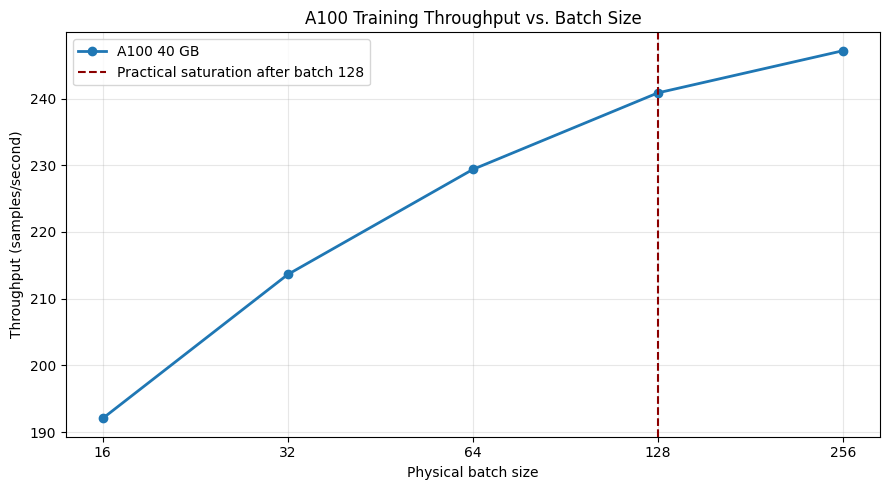

Mounted at /content/drive
A100 results copied to: /content/drive/MyDrive/HW4_1598/HW4_5/A100


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import os
import shutil
import subprocess

successful_batches = (
    batch_scaling_df[
        batch_scaling_df["status"] == "success"
    ]
    .copy()
    .sort_values("batch_size")
)

successful_batches["throughput_gain_percent"] = (
    successful_batches[
        "throughput_samples_per_second"
    ]
    .pct_change()
    .mul(100)
)

print("A100 marginal throughput gains")
display(
    successful_batches[
        [
            "batch_size",
            "throughput_samples_per_second",
            "throughput_gain_percent",
            "peak_allocated_gb",
            "epoch_time_seconds"
        ]
    ].style.format({
        "throughput_samples_per_second": "{:.2f}",
        "throughput_gain_percent": "{:.2f}%",
        "peak_allocated_gb": "{:.3f}",
        "epoch_time_seconds": "{:.2f}"
    })
)

plt.figure(figsize=(9, 5))

plt.plot(
    successful_batches["batch_size"],
    successful_batches[
        "throughput_samples_per_second"
    ],
    marker="o",
    linewidth=2,
    label="A100 40 GB"
)

plt.axvline(
    128,
    color="darkred",
    linestyle="--",
    label="Practical saturation after batch 128"
)

plt.xscale("log", base=2)
plt.xticks(
    successful_batches["batch_size"],
    successful_batches["batch_size"]
)
plt.xlabel("Physical batch size")
plt.ylabel("Throughput (samples/second)")
plt.title("A100 Training Throughput vs. Batch Size")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

A100_PLOT_PATH = "/content/a100_throughput_vs_batch.png"
plt.savefig(
    A100_PLOT_PATH,
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Preserve the first-card results in Drive
from google.colab import drive
drive.mount("/content/drive")

A100_DRIVE_DIRECTORY = (
    "/content/drive/MyDrive/HW4_1598/HW4_5/A100"
)
os.makedirs(A100_DRIVE_DIRECTORY, exist_ok=True)

shutil.copy2(
    BATCH_SCALING_PATH,
    os.path.join(
        A100_DRIVE_DIRECTORY,
        "a100_batch_scaling.csv"
    )
)

shutil.copy2(
    A100_PLOT_PATH,
    os.path.join(
        A100_DRIVE_DIRECTORY,
        "a100_throughput_vs_batch.png"
    )
)

# Capture the GPU UUID in a text artifact
gpu_capture = subprocess.run(
    [
        "nvidia-smi",
        "--query-gpu=timestamp,uuid,name,memory.total,driver_version",
        "--format=csv"
    ],
    capture_output=True,
    text=True,
    check=True
).stdout

with open(
    os.path.join(
        A100_DRIVE_DIRECTORY,
        "GPU_UUID.txt"
    ),
    "w"
) as gpu_file:
    gpu_file.write(gpu_capture)

print(
    "A100 results copied to: "
    f"{A100_DRIVE_DIRECTORY}"
)

## Part A.3 — Second-Card Batch Scaling

**Question:** How does batch-size scaling on an L4 GPU compare with the A100?

I repeat the same FP32 BERT batch-scaling experiment on an NVIDIA L4 GPU. The dataset, model, sequence length, seed, optimizer, learning rate, warmup ratio, and measurement method remain unchanged.

The L4 is treated as the second Colab card for the single-GPU comparison. The instructor-designated two-GPU requirement in Part C is separate and still requires instructor approval.

In [2]:
import torch

print("GPU:", torch.cuda.get_device_name(0))
print("GPU Memory:", round(
    torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
), "GB")

!nvidia-smi -L

GPU: NVIDIA L4
GPU Memory: 22.03 GB
GPU 0: NVIDIA L4 (UUID: GPU-5ce62454-fad6-a9c1-43ff-b905451a57e9)


### Part A.3.1 — L4 GPU Batch-Size Scaling Experiment

**Question:** How do training throughput, peak GPU memory usage, and epoch execution time change as batch size increases on the NVIDIA L4 GPU?

**Objective:**
Repeat the FP32 BERT training benchmark on the NVIDIA L4 GPU using the same dataset, model configuration, seed, sequence length, and measurement methodology as the A100 experiment.

Test increasing batch sizes until GPU memory is exhausted.

Record:
- Physical batch size
- Training throughput (samples/second)
- Epoch execution time (seconds)
- Peak allocated GPU memory (GB)
- Peak reserved GPU memory (GB)
- Out-of-memory (OOM) status

Save the experimental results separately for comparison with the NVIDIA A100.

In [7]:
# ============================================================
# PART A.3.1 — NVIDIA L4 BATCH SCALING
# ============================================================

import pandas as pd
import torch
from pathlib import Path
from google.colab import drive

# Verify correct GPU
gpu_name = torch.cuda.get_device_name(0)

print("Current GPU:", gpu_name)

assert "L4" in gpu_name, (
    f"Expected NVIDIA L4, but found {gpu_name}"
)

# Verify required setup
assert "train_dataset" in globals(), (
    "Run Part A.1 dataset reconstruction first."
)

assert "run_batch_size_experiment" in globals(), (
    "Run Part A.2 function-definition cell first."
)

# Connect Google Drive
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

# Dedicated folder for L4 results
L4_DIR = Path(
    "/content/drive/MyDrive/HW4_1598/HW4_5/L4"
)

L4_DIR.mkdir(parents=True, exist_ok=True)

# Physical batch sizes
L4_BATCH_SIZES = [
    16, 32, 64, 128, 256, 512
]

l4_results = []

print("\nStarting NVIDIA L4 Batch Scaling\n")

for batch_size in L4_BATCH_SIZES:

    print(f"\nTesting batch size: {batch_size}")

    result = run_batch_size_experiment(batch_size)

    l4_results.append(result)

    # Save after every completed test
    l4_df = pd.DataFrame(l4_results)

    l4_df.to_csv(
        L4_DIR / "l4_batch_scaling.csv",
        index=False
    )

    # Stop when GPU runs out of memory
    if result["status"] == "OOM":
        print(
            "\nGPU memory limit reached. "
            "Stopping batch scaling."
        )
        break

print("\n========== L4 RESULTS ==========\n")

display(l4_df)

print("\nResults saved to:")
print(L4_DIR / "l4_batch_scaling.csv")

Current GPU: NVIDIA L4

Starting NVIDIA L4 Batch Scaling


Testing batch size: 16


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batch 16: success | 98.14 samples/s | 35.66s | 2.479 GB allocated

Testing batch size: 32


... (8 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batch 512: OUT OF MEMORY

GPU memory limit reached. Stopping batch scaling.

========== L4 RESULTS ==========



,batch_size,status,batches_per_epoch,examples_seen,epoch_loss,epoch_time_seconds,throughput_samples_per_second,peak_allocated_gb,peak_reserved_gb,error
0,16,success,219.0,3500,0.897756,35.662644,98.141911,2.478766,2.759766,
1,32,success,110.0,3500,0.960026,30.678229,114.087422,3.740271,3.906250,
2,64,success,55.0,3500,1.014891,29.637714,118.092778,6.151797,6.345703,
3,128,success,28.0,3500,1.049107,28.215186,124.046675,10.995914,11.265625,
4,256,success,14.0,3500,1.069440,28.020612,124.908049,20.652899,20.851562,
5,512,OOM,NaN,0,NaN,NaN,NaN,NaN,NaN,CUDA out of memory. Tried to allocate 768.00 M...



Results saved to:
/content/drive/MyDrive/HW4_1598/HW4_5/L4/l4_batch_scaling.csv



## Part A.4 — A100 vs L4 GPU Comparison

**Question:** How does increasing batch size affect training throughput, GPU memory consumption, and epoch execution time on the NVIDIA A100 and L4 GPUs?

**Objective:** Compare both GPUs using the same FP32 BERT training configuration and dataset.

We compare:
1. Training throughput across batch sizes.
2. Peak allocated GPU memory.
3. Execution time per epoch.
4. Maximum successful batch size.
5. The point where throughput begins to plateau.


,batch_size,throughput_samples_per_second_A100,throughput_samples_per_second_L4,speedup_A100_vs_L4
0,16,192.049,98.142,1.957
1,32,213.632,114.087,1.873
2,64,229.385,118.093,1.942
3,128,240.866,124.047,1.942
4,256,247.186,124.908,1.979


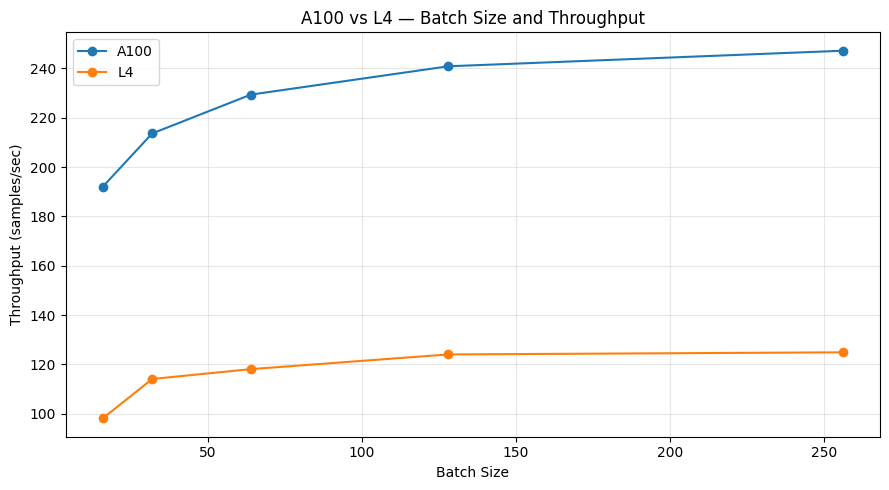

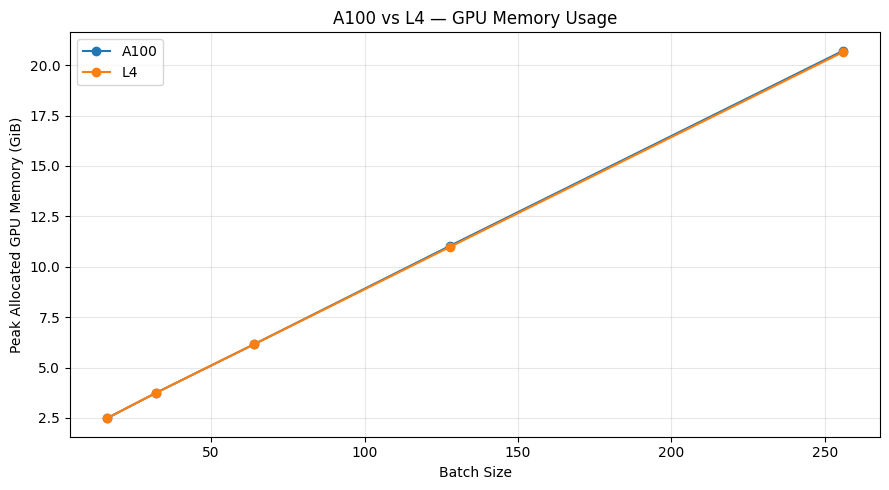

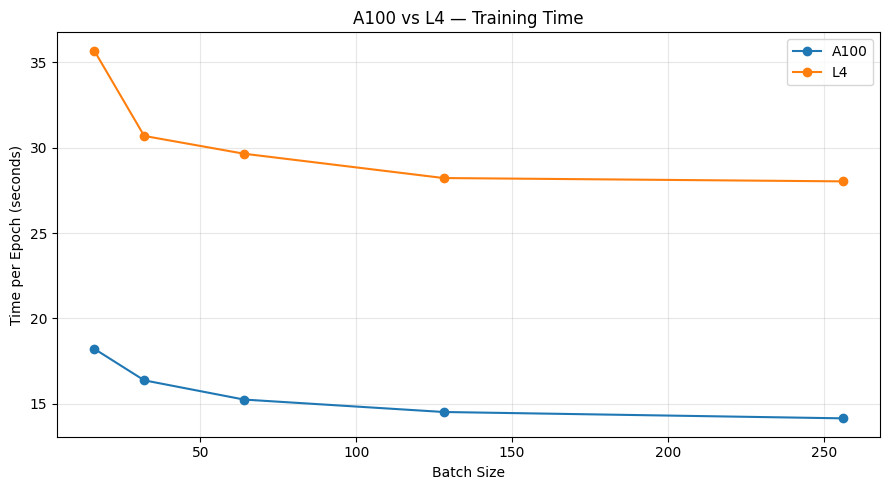


### Part A — Experimental Summary

- Maximum successful A100 batch: **256**
- Maximum successful L4 batch: **256**
- Maximum batch-size ratio: **1.00**
- GPU memory capacity ratio: **1.79**

**Observation:** Maximum batch size does not necessarily
increase proportionally with VRAM because model weights,
gradients, optimizer state, CUDA overhead, and activation
memory contribute differently to total memory consumption.


Part A comparison files saved successfully!


In [8]:

# ==========================================================
# PART A.4 — A100 vs L4 COMPARISON AND GRAPHS
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt
import json
from pathlib import Path
from IPython.display import display, Markdown

ROOT = Path("/content/drive/MyDrive/HW4_1598/HW4_5")

a100 = pd.read_csv(
    ROOT / "A100/a100_batch_scaling.csv"
)
l4 = pd.read_csv(
    ROOT / "L4/l4_batch_scaling.csv"
)

a100_ok = a100[a100["status"] == "success"].copy()
l4_ok = l4[l4["status"] == "success"].copy()

a100_ok = a100_ok.sort_values("batch_size")
l4_ok = l4_ok.sort_values("batch_size")

# Combine results for comparison
comparison = a100_ok.merge(
    l4_ok,
    on="batch_size",
    suffixes=("_A100", "_L4")
)

comparison["speedup_A100_vs_L4"] = (
    comparison["throughput_samples_per_second_A100"]
    / comparison["throughput_samples_per_second_L4"]
)

display(comparison[[
    "batch_size",
    "throughput_samples_per_second_A100",
    "throughput_samples_per_second_L4",
    "speedup_A100_vs_L4"
]].round(3))

# Plot 1 — Throughput
plt.figure(figsize=(9, 5))

for name, data in [("A100", a100_ok), ("L4", l4_ok)]:
    plt.plot(
        data["batch_size"],
        data["throughput_samples_per_second"],
        marker="o",
        label=name
    )

plt.xlabel("Batch Size")
plt.ylabel("Throughput (samples/sec)")
plt.title("A100 vs L4 — Batch Size and Throughput")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(ROOT / "part_a_throughput_comparison.png", dpi=200)
plt.show()

# Plot 2 — Peak allocated GPU memory
plt.figure(figsize=(9, 5))

for name, data in [("A100", a100_ok), ("L4", l4_ok)]:
    plt.plot(
        data["batch_size"],
        data["peak_allocated_gb"],
        marker="o",
        label=name
    )

plt.xlabel("Batch Size")
plt.ylabel("Peak Allocated GPU Memory (GiB)")
plt.title("A100 vs L4 — GPU Memory Usage")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(ROOT / "part_a_memory_comparison.png", dpi=200)
plt.show()

# Plot 3 — Epoch execution time
plt.figure(figsize=(9, 5))

for name, data in [("A100", a100_ok), ("L4", l4_ok)]:
    plt.plot(
        data["batch_size"],
        data["epoch_time_seconds"],
        marker="o",
        label=name
    )

plt.xlabel("Batch Size")
plt.ylabel("Time per Epoch (seconds)")
plt.title("A100 vs L4 — Training Time")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(ROOT / "part_a_epoch_time_comparison.png", dpi=200)
plt.show()

# Maximum successful batch sizes
max_a100 = int(a100_ok["batch_size"].max())
max_l4 = int(l4_ok["batch_size"].max())

# Physical total memory capacity
a100_memory = 39.49
l4_memory = 22.03

batch_ratio = max_a100 / max_l4
vram_ratio = a100_memory / l4_memory

# Save comparison
comparison.to_csv(
    ROOT / "part_a_gpu_comparison.csv",
    index=False
)

summary = {
    "A100_max_batch": max_a100,
    "L4_max_batch": max_l4,
    "max_batch_ratio": batch_ratio,
    "VRAM_capacity_ratio": vram_ratio
}

(ROOT / "part_a_comparison.json").write_text(
    json.dumps(summary, indent=2)
)

display(Markdown(f"""
### Part A — Experimental Summary

- Maximum successful A100 batch: **{max_a100}**
- Maximum successful L4 batch: **{max_l4}**
- Maximum batch-size ratio: **{batch_ratio:.2f}**
- GPU memory capacity ratio: **{vram_ratio:.2f}**

**Observation:** Maximum batch size does not necessarily
increase proportionally with VRAM because model weights,
gradients, optimizer state, CUDA overhead, and activation
memory contribute differently to total memory consumption.
"""))

print("Part A comparison files saved successfully!")



### Part A — Results and Discussion

**Q1. What is the largest successful batch size on each GPU?**

The largest successfully tested batch size was 256 on both the NVIDIA A100 and NVIDIA L4. Batch size 512 caused an out-of-memory (OOM) error on both GPUs.

At batch size 256:
- A100 throughput: 247.19 samples/second
- L4 throughput: 124.91 samples/second
- A100 peak allocated memory: 20.72 GiB
- L4 peak allocated memory: 20.65 GiB

**Q2. At which batch size does throughput stop improving significantly?**

Throughput increased as batch size increased, but the improvement became smaller at larger batch sizes.

On the L4, throughput increased only from 124.05 to 124.91 samples/second between batch sizes 128 and 256. Therefore, throughput effectively plateaued around batch size 128.

On the A100, throughput continued improving slightly beyond batch size 128, although the gains diminished.

**Q3. Compare maximum batch-size ratio with VRAM ratio.**

Maximum successfully tested batch-size ratio:

256 / 256 = 1.00

GPU memory capacity ratio:

39.49 / 22.03 = 1.79

These ratios differ because GPU memory usage includes model parameters, gradients, optimizer states, activations, and framework overhead. In addition, batch sizes were tested only in powers of two, so the largest successful tested batch is not necessarily the exact maximum batch that each GPU can support.

**Conclusion**

The A100 provided approximately 1.98 times the throughput of the L4 at batch size 256. Both GPUs showed diminishing throughput gains as batch size increased. The results demonstrate that GPU compute performance and memory capacity affect training differently.



## Part B — Memory Optimization Techniques

### Part B.1 — Automatic Mixed Precision (AMP)

**Question:** Can automatic mixed precision reduce BERT training memory consumption and improve training throughput without significantly affecting classification accuracy?

**Objective:** Compare the original FP32 baseline with FP16 automatic mixed precision on the NVIDIA L4 GPU.

The experiment will measure:
- Maximum successful physical batch size
- Training throughput (samples/second)
- Peak GPU memory consumption
- Final evaluation accuracy

**Hypothesis:** Mixed precision may reduce activation memory consumption and improve GPU throughput while maintaining similar classification accuracy.


In [9]:

# PART B.1 — AMP ENVIRONMENT VERIFICATION

import torch
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/HW4_1598/HW4_5")
PART_B_DIR = ROOT / "Part_B"
PART_B_DIR.mkdir(parents=True, exist_ok=True)

assert torch.cuda.is_available(), "CUDA GPU is required."

gpu_name = torch.cuda.get_device_name(0)

print("GPU:", gpu_name)
print("CUDA available:", torch.cuda.is_available())

print("FP16 AMP supported:",
      torch.cuda.is_available())

print("Current training dataset available:",
      "train_dataset" in globals())

print("Validation dataset available:",
      "val_dataset" in globals())

print("Baseline function available:",
      "run_batch_size_experiment" in globals())

print("Part B results folder:", PART_B_DIR)

# Check PyTorch AMP functions
print("torch.amp.autocast available:",
      hasattr(torch.amp, "autocast"))

print("torch.amp.GradScaler available:",
      hasattr(torch.amp, "GradScaler"))


GPU: NVIDIA L4
CUDA available: True
FP16 AMP supported: True
Current training dataset available: True
Validation dataset available: False
Baseline function available: True
Part B results folder: /content/drive/MyDrive/HW4_1598/HW4_5/Part_B
torch.amp.autocast available: True
torch.amp.GradScaler available: True



### Part B.1.1 — FP16 Automatic Mixed Precision Benchmark

**Question:** How does FP16 automatic mixed precision affect GPU memory usage, training throughput, maximum physical batch size, and final evaluation accuracy compared with the original FP32 BERT baseline?

**Method:**
- Use the same TweetEval sentiment dataset and original 70/15/15 split.
- Retain BERT-base-uncased, sequence length 128, seed 1598, AdamW optimizer, learning rate 2e-5, and four training epochs.
- Enable `torch.autocast` and `GradScaler` for FP16 mixed-precision training.
- Test increasing batch sizes until out-of-memory.
- Record throughput, peak GPU memory, training time, and final test accuracy.

**Expected observation:** FP16 AMP may reduce activation memory and improve GPU performance, although actual gains depend on the hardware and workload.


In [10]:

# ========================================================
# PART B.1 — AUTOMATIC MIXED PRECISION (FP16)
# ========================================================

import gc
import time
import random
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from torch.utils.data import DataLoader
from torch.optim import AdamW
from torch.nn.utils import clip_grad_norm_
from transformers import (
    BertForSequenceClassification,
    get_linear_schedule_with_warmup
)
from sklearn.metrics import accuracy_score

assert "train_dataset" in globals()
assert "test_dataset" in globals()
assert torch.cuda.is_available()

device = torch.device("cuda")

PART_B_DIR = Path(
    "/content/drive/MyDrive/HW4_1598/HW4_5/Part_B"
)
PART_B_DIR.mkdir(parents=True, exist_ok=True)

def reset_seed():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

def create_amp_model():
    reset_seed()
    return BertForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=3
    ).to(device)

def train_amp_epoch(model, loader, optimizer, scaler,
                    scheduler=None):
    model.train()
    samples = 0
    loss_sum = 0.0

    torch.cuda.synchronize()
    start = time.perf_counter()

    for input_ids, attention_mask, labels in loader:
        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast("cuda", dtype=torch.float16):
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )
            loss = outputs.loss

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        clip_grad_norm_(model.parameters(), 1.0)

        old_scale = scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()

        if scheduler is not None:
            if scaler.get_scale() >= old_scale:
                scheduler.step()

        n = labels.size(0)
        samples += n
        loss_sum += loss.detach().item() * n

    torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    return {
        "samples": samples,
        "loss": loss_sum / samples,
        "seconds": elapsed,
        "throughput": samples / elapsed
    }

def amp_batch_test(batch_size):
    model = optimizer = loader = scaler = None

    try:
        reset_seed()
        model = create_amp_model()
        loader = DataLoader(
            train_dataset,
            batch_size=batch_size,
            shuffle=True,
            num_workers=0
        )
        optimizer = AdamW(
            model.parameters(),
            lr=LEARNING_RATE,
            weight_decay=WEIGHT_DECAY
        )
        scaler = torch.amp.GradScaler("cuda")

        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

        result = train_amp_epoch(
            model, loader, optimizer, scaler
        )

        return {
            "batch_size": batch_size,
            "status": "success",
            "throughput_samples_per_second":
                result["throughput"],
            "epoch_time_seconds": result["seconds"],
            "peak_allocated_gb":
                torch.cuda.max_memory_allocated()/1024**3,
            "peak_reserved_gb":
                torch.cuda.max_memory_reserved()/1024**3,
            "epoch_loss": result["loss"]
        }

    except torch.cuda.OutOfMemoryError:
        print(f"Batch {batch_size}: OOM")
        return {
            "batch_size": batch_size,
            "status": "OOM"
        }

    finally:
        del model, optimizer, loader, scaler
        gc.collect()
        torch.cuda.empty_cache()

# Batch scaling
amp_results = []

for bs in [16, 32, 64, 128, 256, 512, 1024]:
    print(f"\nTesting AMP batch size {bs}")
    result = amp_batch_test(bs)
    amp_results.append(result)

    pd.DataFrame(amp_results).to_csv(
        PART_B_DIR / "amp_batch_scaling.csv",
        index=False
    )

    if result["status"] == "success":
        print(
            f"Throughput: "
            f"{result['throughput_samples_per_second']:.2f}"
            f" samples/sec"
        )
        print(
            f"Peak allocated memory: "
            f"{result['peak_allocated_gb']:.3f} GiB"
        )
    else:
        break

amp_df = pd.DataFrame(amp_results)
display(amp_df)

successful = amp_df[
    amp_df["status"] == "success"
]

best_amp_batch = int(
    successful["batch_size"].max()
)

print("\nLargest successful AMP batch:", best_amp_batch)
print("Results saved successfully.")



Testing AMP batch size 16


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Throughput: 170.14 samples/sec
Peak allocated memory: 2.251 GiB

Testing AMP batch size 32


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Throughput: 270.20 samples/sec
Peak allocated memory: 3.014 GiB

Testing AMP batch size 64


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (5 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batch 512: OOM


,batch_size,status,throughput_samples_per_second,epoch_time_seconds,peak_allocated_gb,peak_reserved_gb,epoch_loss
0,16,success,170.139936,20.571302,2.251478,2.486328,0.853921
1,32,success,270.198717,12.953429,3.013953,3.238281,0.898005
2,64,success,315.602872,11.089886,4.563769,4.693359,0.977612
3,128,success,335.070182,10.445573,7.670765,7.851562,1.007082
4,256,success,353.357303,9.904988,13.905752,14.166016,1.031851
5,512,OOM,NaN,NaN,NaN,NaN,NaN



Largest successful AMP batch: 256
Results saved successfully.



### Part B.1.2 — AMP Fine-Tuning and Final Accuracy

**Question:** Does FP16 mixed precision preserve sentiment classification accuracy compared with FP32 training?

**Method:**
1. Initialize the original BERT model with the same random seed.
2. Fine-tune for four epochs using FP16 AMP and physical batch size 16.
3. Record training loss and validation accuracy for every epoch.
4. Select the checkpoint with the highest validation accuracy.
5. Evaluate the selected model on the held-out test dataset.
6. Save the training history, accuracy, and best checkpoint to Google Drive.

**Note:** Maximum batch-size results and final accuracy results are measured separately. The original physical batch size of 16 is retained for a more controlled accuracy comparison.


In [11]:

# PART B.1.2 — AMP FINAL ACCURACY EXPERIMENT

import gc
import json
import time
import torch
import pandas as pd
from pathlib import Path
from torch.utils.data import DataLoader
from torch.optim import AdamW
from transformers import (
    BertForSequenceClassification,
    get_linear_schedule_with_warmup
)

AMP_DIR = PART_B_DIR / "amp_final"
AMP_DIR.mkdir(parents=True, exist_ok=True)

assert "validation_dataset" in globals()
assert "test_dataset" in globals()

# Match original HW4.a batch size
FINAL_BATCH = 16
NUM_EPOCHS = 4

reset_seed()

train_generator = torch.Generator()
train_generator.manual_seed(SEED)

train_loader_amp = DataLoader(
    train_dataset,
    batch_size=FINAL_BATCH,
    shuffle=True,
    generator=train_generator
)

val_loader_amp = DataLoader(
    validation_dataset,
    batch_size=32,
    shuffle=False
)

test_loader_amp = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

model_amp = create_amp_model()

optimizer_amp = AdamW(
    model_amp.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

total_steps = len(train_loader_amp) * NUM_EPOCHS

scheduler_amp = get_linear_schedule_with_warmup(
    optimizer_amp,
    num_warmup_steps=int(total_steps * WARMUP_RATIO),
    num_training_steps=total_steps
)

scaler_amp = torch.amp.GradScaler("cuda")


@torch.no_grad()
def evaluate_amp(model, loader):
    model.eval()

    correct = 0
    total = 0
    total_loss = 0.0

    for ids, mask, labels in loader:
        ids = ids.to(device)
        mask = mask.to(device)
        labels = labels.to(device)

        with torch.autocast("cuda", dtype=torch.float16):
            outputs = model(
                input_ids=ids,
                attention_mask=mask,
                labels=labels
            )

        preds = outputs.logits.argmax(dim=1)

        correct += (preds == labels).sum().item()
        total += labels.size(0)
        total_loss += outputs.loss.item() * labels.size(0)

    return {
        "accuracy": correct / total,
        "loss": total_loss / total
    }


history_amp = []
best_val_accuracy = -1.0
best_epoch = None

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

training_start = time.perf_counter()

for epoch in range(NUM_EPOCHS):

    train_result = train_amp_epoch(
        model_amp,
        train_loader_amp,
        optimizer_amp,
        scaler_amp,
        scheduler_amp
    )

    val_result = evaluate_amp(
        model_amp,
        val_loader_amp
    )

    record = {
        "epoch": epoch + 1,
        "train_loss": train_result["loss"],
        "train_seconds": train_result["seconds"],
        "train_throughput": train_result["throughput"],
        "val_loss": val_result["loss"],
        "val_accuracy": val_result["accuracy"]
    }

    history_amp.append(record)

    if val_result["accuracy"] > best_val_accuracy:
        best_val_accuracy = val_result["accuracy"]
        best_epoch = epoch + 1

        model_amp.save_pretrained(
            AMP_DIR / "best_model",
            safe_serialization=True
        )

    pd.DataFrame(history_amp).to_csv(
        AMP_DIR / "training_history.csv",
        index=False
    )

    print(
        f"Epoch {epoch+1}/{NUM_EPOCHS} | "
        f"Train loss: {train_result['loss']:.4f} | "
        f"Val accuracy: {val_result['accuracy']:.4f}"
    )

torch.cuda.synchronize()
training_seconds = time.perf_counter() - training_start

peak_memory = (
    torch.cuda.max_memory_allocated() / 1024**3
)

# Reload the checkpoint selected by validation accuracy
del model_amp
gc.collect()
torch.cuda.empty_cache()

best_model_amp = (
    BertForSequenceClassification.from_pretrained(
        AMP_DIR / "best_model"
    ).to(device)
)

test_result = evaluate_amp(
    best_model_amp,
    test_loader_amp
)

summary_amp = {
    "technique": "FP16 AMP",
    "physical_batch_size_for_accuracy": FINAL_BATCH,
    "maximum_successful_scaling_batch": best_amp_batch,
    "best_validation_epoch": best_epoch,
    "best_validation_accuracy": best_val_accuracy,
    "test_accuracy": test_result["accuracy"],
    "test_loss": test_result["loss"],
    "training_wall_clock_seconds": training_seconds,
    "training_peak_allocated_gib": peak_memory
}

(AMP_DIR / "summary.json").write_text(
    json.dumps(summary_amp, indent=2)
)

display(pd.DataFrame(history_amp))

print("\n===== FINAL AMP RESULTS =====")
print("Best epoch:", best_epoch)
print("Validation accuracy:", round(best_val_accuracy, 4))
print("Test accuracy:", round(test_result["accuracy"], 4))
print("Training time:", round(training_seconds, 2), "seconds")
print("Peak training memory:", round(peak_memory, 3), "GiB")
print("Saved to:", AMP_DIR)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 1/4 | Train loss: 0.9099 | Val accuracy: 0.6627


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 2/4 | Train loss: 0.6177 | Val accuracy: 0.6707


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 3/4 | Train loss: 0.4027 | Val accuracy: 0.6813
Epoch 4/4 | Train loss: 0.2499 | Val accuracy: 0.6760


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,epoch,train_loss,train_seconds,train_throughput,val_loss,val_accuracy
0,1,0.909917,19.650358,178.113807,0.763265,0.662667
1,2,0.617652,19.841572,176.397315,0.746558,0.670667
2,3,0.402665,19.504812,179.442898,0.842479,0.681333
3,4,0.249865,19.767234,177.060684,0.944547,0.676000



===== FINAL AMP RESULTS =====
Best epoch: 3
Validation accuracy: 0.6813
Test accuracy: 0.6827
Training time: 84.11 seconds
Peak training memory: 2.251 GiB
Saved to: /content/drive/MyDrive/HW4_1598/HW4_5/Part_B/amp_final



### Part B.1 — AMP Results and Interpretation

**Question:** How did automatic mixed precision affect training performance?

At physical batch size 256, FP16 AMP achieved 353.36 samples/second compared with 124.91 samples/second for the FP32 L4 baseline, approximately 2.83 times higher throughput.

Peak allocated GPU memory decreased from 20.65 GiB to 13.91 GiB, a reduction of approximately 32.7%.

Both configurations successfully ran batch size 256 and failed at batch size 512.

For the separate four-epoch AMP accuracy experiment at batch size 16, the best validation accuracy was 68.13% at epoch 3, and test accuracy was 68.27%. Total training time was 84.11 seconds, with peak allocated training memory of 2.251 GiB.

These results show that AMP improved throughput and reduced memory consumption in the measured L4 experiments. A final accuracy comparison with the original FP32 run is needed to determine the accuracy difference.



### Part B.2 — Gradient Checkpointing

**Question:** How does gradient checkpointing affect BERT training memory, throughput, maximum batch size, and accuracy?

**Method:**
- Use the original FP32 BERT configuration.
- Enable gradient checkpointing without AMP or other optimizations.
- Test physical batch sizes in powers of two.
- Measure samples/second, epoch time, and peak GPU memory.
- Compare with the FP32 baseline from Part A.

**Hypothesis:** Gradient checkpointing should reduce activation memory usage at the cost of additional computation during backward propagation.


In [12]:

# PART B.2 — GRADIENT CHECKPOINTING EXPERIMENT

import gc
import time
import pandas as pd
import torch
from pathlib import Path
from torch.utils.data import DataLoader
from torch.optim import AdamW
from transformers import BertForSequenceClassification

GC_DIR = PART_B_DIR / "gradient_checkpointing"
GC_DIR.mkdir(parents=True, exist_ok=True)

assert torch.cuda.is_available()
assert "train_dataset" in globals()
assert "reset_seed" in globals()
assert "MODEL_NAME" in globals()
assert "LEARNING_RATE" in globals()
assert "WEIGHT_DECAY" in globals()

device = torch.device("cuda")

def checkpointing_batch_test(batch_size):
    model = None
    optimizer = None
    loader = None

    try:
        reset_seed()

        model = BertForSequenceClassification.from_pretrained(
            MODEL_NAME,
            num_labels=3
        ).to(device)

        # Checkpointing only: keep FP32
        model.gradient_checkpointing_enable(
            gradient_checkpointing_kwargs={
                "use_reentrant": False
            }
        )

        model.train()

        loader = DataLoader(
            train_dataset,
            batch_size=batch_size,
            shuffle=True,
            num_workers=0
        )

        optimizer = AdamW(
            model.parameters(),
            lr=LEARNING_RATE,
            weight_decay=WEIGHT_DECAY
        )

        gc.collect()
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()

        start = time.perf_counter()
        seen = 0
        loss_total = 0.0

        for ids, mask, labels in loader:
            ids = ids.to(device)
            mask = mask.to(device)
            labels = labels.to(device)

            optimizer.zero_grad(set_to_none=True)

            outputs = model(
                input_ids=ids,
                attention_mask=mask,
                labels=labels
            )

            loss = outputs.loss
            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), 1.0
            )

            optimizer.step()

            n = labels.size(0)
            seen += n
            loss_total += loss.item() * n

        torch.cuda.synchronize()
        elapsed = time.perf_counter() - start

        return {
            "batch_size": batch_size,
            "status": "success",
            "throughput_samples_per_second": seen / elapsed,
            "epoch_time_seconds": elapsed,
            "peak_allocated_gb":
                torch.cuda.max_memory_allocated() / 1024**3,
            "peak_reserved_gb":
                torch.cuda.max_memory_reserved() / 1024**3,
            "epoch_loss": loss_total / seen
        }

    except torch.cuda.OutOfMemoryError:
        print(f"Batch {batch_size}: OUT OF MEMORY")
        return {
            "batch_size": batch_size,
            "status": "OOM"
        }

    finally:
        del model, optimizer, loader
        gc.collect()
        torch.cuda.empty_cache()


gc_results = []

for bs in [16, 32, 64, 128, 256, 512, 1024]:
    print(f"\nTesting checkpointing batch size {bs}")

    result = checkpointing_batch_test(bs)
    gc_results.append(result)

    pd.DataFrame(gc_results).to_csv(
        GC_DIR / "checkpointing_batch_scaling.csv",
        index=False
    )

    if result["status"] == "OOM":
        break

    print(
        f"Throughput: "
        f"{result['throughput_samples_per_second']:.2f} samples/sec"
    )
    print(
        f"Peak memory: "
        f"{result['peak_allocated_gb']:.3f} GiB"
    )

gc_df = pd.DataFrame(gc_results)

print("\n===== GRADIENT CHECKPOINTING RESULTS =====")
display(gc_df)

gc_success = gc_df[gc_df["status"] == "success"]

if not gc_success.empty:
    print(
        "Largest successful batch:",
        int(gc_success["batch_size"].max())
    )

print("Results saved:", GC_DIR)



Testing checkpointing batch size 16


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Throughput: 75.26 samples/sec
Peak memory: 4.136 GiB

Testing checkpointing batch size 32


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Throughput: 84.19 samples/sec
Peak memory: 4.152 GiB

Testing checkpointing batch size 64


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (7 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Throughput: 90.65 samples/sec
Peak memory: 15.974 GiB

===== GRADIENT CHECKPOINTING RESULTS =====


,batch_size,status,throughput_samples_per_second,epoch_time_seconds,peak_allocated_gb,peak_reserved_gb,epoch_loss
0,16,success,75.263771,46.503118,4.136093,4.429688,0.853491
1,32,success,84.188994,41.573130,4.151992,4.414062,0.901080
2,64,success,83.978484,41.677342,4.149677,4.828125,0.966427
3,128,success,88.823746,39.403877,4.912575,5.361328,0.999754
4,256,success,90.098557,38.846349,6.483622,7.218750,1.030721
5,512,success,89.734108,39.004121,9.649887,10.628906,1.063461
6,1024,success,90.646863,38.611375,15.973627,17.771484,1.101771


Largest successful batch: 1024
Results saved: /content/drive/MyDrive/HW4_1598/HW4_5/Part_B/gradient_checkpointing


In [13]:

# PART B.2 — CONTINUE CHECKPOINTING TO OOM

from pathlib import Path
import pandas as pd

GC_DIR = Path(
    "/content/drive/MyDrive/HW4_1598/HW4_5/"
    "Part_B/gradient_checkpointing"
)

csv_path = GC_DIR / "checkpointing_batch_scaling.csv"

# Load previous results to avoid rerunning experiments
gc_df = pd.read_csv(csv_path)

print("Previously tested batch sizes:")
print(gc_df[["batch_size", "status"]])

# Continue beyond 1024
for bs in [2048, 4096, 8192]:

    if bs in gc_df["batch_size"].values:
        print(f"Skipping previously tested batch {bs}")
        continue

    print(f"\nTesting batch size {bs}")

    result = checkpointing_batch_test(bs)

    gc_df = pd.concat(
        [gc_df, pd.DataFrame([result])],
        ignore_index=True
    )

    # Save after each experiment
    gc_df.to_csv(csv_path, index=False)

    if result["status"] == "OOM":
        print("GPU memory limit reached.")
        break

display(gc_df)

successful = gc_df[gc_df["status"] == "success"]

print(
    "Largest successful tested batch:",
    int(successful["batch_size"].max())
)


Previously tested batch sizes:
   batch_size   status
0          16  success
1          32  success
2          64  success
3         128  success
4         256  success
5         512  success
6        1024  success

Testing batch size 2048


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batch 2048: OUT OF MEMORY
GPU memory limit reached.


,batch_size,status,throughput_samples_per_second,epoch_time_seconds,peak_allocated_gb,peak_reserved_gb,epoch_loss
0,16,success,75.263771,46.503118,4.136093,4.429688,0.853491
1,32,success,84.188994,41.573130,4.151992,4.414062,0.901080
2,64,success,83.978484,41.677342,4.149677,4.828125,0.966427
3,128,success,88.823746,39.403877,4.912575,5.361328,0.999754
4,256,success,90.098557,38.846349,6.483622,7.218750,1.030721
5,512,success,89.734108,39.004121,9.649887,10.628906,1.063461
6,1024,success,90.646863,38.611375,15.973627,17.771484,1.101771
7,2048,OOM,NaN,NaN,NaN,NaN,NaN


Largest successful tested batch: 1024



### Part B.2.1 — Gradient Checkpointing Accuracy Evaluation

**Question:** Does gradient checkpointing preserve BERT classification accuracy while reducing GPU memory consumption?

**Method:**
- Use the original FP32 BERT model and dataset.
- Enable gradient checkpointing only.
- Use physical batch size 16.
- Fine-tune for four epochs using the original learning rate, optimizer, warmup configuration, and random seed.
- Select the best checkpoint using validation accuracy.
- Evaluate the selected checkpoint on the held-out test set.

**Batch-scaling observations:**

- Largest successful checkpointing batch: 1024.
- Batch size 2048: Out of memory.
- Peak memory at batch 256: 6.48 GiB compared with 20.65 GiB for baseline FP32.
- Throughput at batch 256: 90.10 samples/sec compared with 124.91 samples/sec for baseline FP32.

**Interpretation:**

Gradient checkpointing reduced peak allocated GPU memory by approximately 68.6% at batch size 256, while decreasing throughput by approximately 27.9%. This is consistent with additional activation recomputation during backward propagation.


In [14]:

# ==========================================================
# PART B.2.1 — GRADIENT CHECKPOINTING FINAL ACCURACY
# ==========================================================

import time
import json
import gc
import pandas as pd
import torch

from pathlib import Path
from torch.utils.data import DataLoader
from torch.optim import AdamW
from transformers import (
    BertForSequenceClassification,
    get_linear_schedule_with_warmup
)

GC_FINAL_DIR = GC_DIR / "final_accuracy"
GC_FINAL_DIR.mkdir(parents=True, exist_ok=True)

assert "train_dataset" in globals()
assert "validation_dataset" in globals()
assert "test_dataset" in globals()

reset_seed()

FINAL_BATCH = 16
NUM_EPOCHS = 4

generator = torch.Generator().manual_seed(SEED)

train_loader_gc = DataLoader(
    train_dataset,
    batch_size=FINAL_BATCH,
    shuffle=True,
    generator=generator
)

val_loader_gc = DataLoader(
    validation_dataset,
    batch_size=32,
    shuffle=False
)

test_loader_gc = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

model_gc = BertForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3
).to(device)

model_gc.gradient_checkpointing_enable(
    gradient_checkpointing_kwargs={
        "use_reentrant": False
    }
)

optimizer_gc = AdamW(
    model_gc.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

total_steps = len(train_loader_gc) * NUM_EPOCHS

scheduler_gc = get_linear_schedule_with_warmup(
    optimizer_gc,
    num_warmup_steps=int(total_steps * WARMUP_RATIO),
    num_training_steps=total_steps
)

history_gc = []
best_val_acc = -1
best_epoch_gc = None

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()

start_time = time.perf_counter()

for epoch in range(NUM_EPOCHS):

    model_gc.train()
    epoch_loss = 0
    samples_seen = 0

    torch.cuda.synchronize()
    epoch_start = time.perf_counter()

    for ids, mask, labels in train_loader_gc:

        ids = ids.to(device)
        mask = mask.to(device)
        labels = labels.to(device)

        optimizer_gc.zero_grad(set_to_none=True)

        outputs = model_gc(
            input_ids=ids,
            attention_mask=mask,
            labels=labels
        )

        loss = outputs.loss
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model_gc.parameters(), 1.0
        )

        optimizer_gc.step()
        scheduler_gc.step()

        n = labels.size(0)
        samples_seen += n
        epoch_loss += loss.item() * n

    torch.cuda.synchronize()
    epoch_time = time.perf_counter() - epoch_start

    # Reuse the FP32/AMP-compatible evaluation function.
    # Autocast in evaluate_amp is enabled only for evaluation.
    val = evaluate_amp(model_gc, val_loader_gc)

    row = {
        "epoch": epoch + 1,
        "train_loss": epoch_loss / samples_seen,
        "train_seconds": epoch_time,
        "train_throughput": samples_seen / epoch_time,
        "val_loss": val["loss"],
        "val_accuracy": val["accuracy"]
    }

    history_gc.append(row)

    if val["accuracy"] > best_val_acc:
        best_val_acc = val["accuracy"]
        best_epoch_gc = epoch + 1

        model_gc.save_pretrained(
            GC_FINAL_DIR / "best_model",
            safe_serialization=True
        )

    pd.DataFrame(history_gc).to_csv(
        GC_FINAL_DIR / "training_history.csv",
        index=False
    )

    print(
        f"Epoch {epoch+1}/{NUM_EPOCHS} | "
        f"Train loss: {row['train_loss']:.4f} | "
        f"Validation accuracy: {row['val_accuracy']:.4f}"
    )

torch.cuda.synchronize()
wall_time = time.perf_counter() - start_time

peak_memory_gc = (
    torch.cuda.max_memory_allocated() / 1024**3
)

del model_gc
gc.collect()
torch.cuda.empty_cache()

best_gc_model = BertForSequenceClassification.from_pretrained(
    GC_FINAL_DIR / "best_model"
).to(device)

test_gc = evaluate_amp(best_gc_model, test_loader_gc)

summary_gc = {
    "technique": "Gradient checkpointing FP32",
    "maximum_successful_scaling_batch": 1024,
    "accuracy_training_batch": FINAL_BATCH,
    "best_epoch": best_epoch_gc,
    "best_validation_accuracy": best_val_acc,
    "test_accuracy": test_gc["accuracy"],
    "training_wall_clock_seconds": wall_time,
    "peak_training_memory_gib": peak_memory_gc
}

(GC_FINAL_DIR / "summary.json").write_text(
    json.dumps(summary_gc, indent=2)
)

display(pd.DataFrame(history_gc))

print("\n===== FINAL CHECKPOINTING RESULTS =====")
print("Best epoch:", best_epoch_gc)
print("Best validation accuracy:", round(best_val_acc, 4))
print("Test accuracy:", round(test_gc["accuracy"], 4))
print("Training time:", round(wall_time, 2), "seconds")
print("Peak training memory:", round(peak_memory_gc, 3), "GiB")
print("Saved to:", GC_FINAL_DIR)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 1/4 | Train loss: 0.9077 | Validation accuracy: 0.6453


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 2/4 | Train loss: 0.6068 | Validation accuracy: 0.6613
Epoch 3/4 | Train loss: 0.3778 | Validation accuracy: 0.6560


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 4/4 | Train loss: 0.2360 | Validation accuracy: 0.6653


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,epoch,train_loss,train_seconds,train_throughput,val_loss,val_accuracy
0,1,0.907715,46.435887,75.372739,0.748336,0.645333
1,2,0.606839,46.722333,74.910642,0.760448,0.661333
2,3,0.377816,48.217940,72.587091,0.854814,0.656000
3,4,0.235967,48.342288,72.400379,0.945394,0.665333



===== FINAL CHECKPOINTING RESULTS =====
Best epoch: 4
Best validation accuracy: 0.6653
Test accuracy: 0.6853
Training time: 194.56 seconds
Peak training memory: 4.132 GiB
Saved to: /content/drive/MyDrive/HW4_1598/HW4_5/Part_B/gradient_checkpointing/final_accuracy


#### Corrected FP32 Evaluation

In [14]:

# PART B.2.2 — CORRECTED FP32 EVALUATION

import json
import torch
from pathlib import Path
from torch.utils.data import DataLoader
from transformers import BertForSequenceClassification

GC_FINAL_DIR = Path(
    "/content/drive/MyDrive/HW4_1598/HW4_5/"
    "Part_B/gradient_checkpointing/final_accuracy"
)

checkpoint_path = GC_FINAL_DIR / "best_model"

assert checkpoint_path.exists(), "Saved checkpoint not found."
assert "test_dataset" in globals(), (
    "Run Part A.1 dataset reconstruction first."
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Load the already-trained best checkpoint
model_gc_fp32 = BertForSequenceClassification.from_pretrained(
    checkpoint_path
).to(device)

model_gc_fp32.eval()

test_loader_fp32 = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

@torch.no_grad()
def evaluate_strict_fp32(model, loader):
    model.eval()
    correct = 0
    total = 0
    loss_sum = 0.0

    for ids, mask, labels in loader:
        ids = ids.to(device)
        mask = mask.to(device)
        labels = labels.to(device)

        # No autocast — FP32 evaluation
        outputs = model(
            input_ids=ids,
            attention_mask=mask,
            labels=labels
        )

        predictions = outputs.logits.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)
        loss_sum += outputs.loss.item() * labels.size(0)

    return {
        "accuracy": correct / total,
        "loss": loss_sum / total
    }

corrected_test = evaluate_strict_fp32(
    model_gc_fp32,
    test_loader_fp32
)

# Preserve the original result and update the summary
summary_path = GC_FINAL_DIR / "summary.json"
summary = json.loads(summary_path.read_text())

summary["original_test_accuracy_fp16_eval"] = summary["test_accuracy"]
summary["test_accuracy"] = corrected_test["accuracy"]
summary["test_loss_fp32"] = corrected_test["loss"]
summary["evaluation_precision"] = "FP32"

summary_path.write_text(
    json.dumps(summary, indent=2)
)

print("===== CORRECTED FP32 EVALUATION =====")
print("Original FP16-evaluated accuracy:",
      summary["original_test_accuracy_fp16_eval"])
print("Corrected FP32 test accuracy:",
      corrected_test["accuracy"])
print("Corrected FP32 test loss:",
      corrected_test["loss"])
print("Updated summary:", summary_path)

del model_gc_fp32
torch.cuda.empty_cache()


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

===== CORRECTED FP32 EVALUATION =====
Original FP16-evaluated accuracy: 0.6853333333333333
Corrected FP32 test accuracy: 0.6853333333333333
Corrected FP32 test loss: 0.8811024206479391
Updated summary: /content/drive/MyDrive/HW4_1598/HW4_5/Part_B/gradient_checkpointing/final_accuracy/summary.json



### Gradient Checkpointing — FP32 Evaluation Verification

The saved gradient-checkpointing model was re-evaluated using FP32 inference without automatic mixed precision.

**Results:**
- Original FP16 evaluation accuracy: 68.53%
- Corrected FP32 evaluation accuracy: 68.53%
- Corrected FP32 test loss: 0.8811

Both evaluation methods produced the same classification accuracy on the held-out test set.

The corrected FP32 evaluation result is used in the final comparison. The original training time and peak memory measurements remain unchanged.

The updated results are saved in `Part_B/gradient_checkpointing/final_accuracy/summary.json`.



### Part B.3 — Gradient Accumulation

**Question:** Can gradient accumulation achieve a large effective batch size using a smaller physical batch size, and what is its effect on GPU memory, optimizer-step time, and classification accuracy?

**Method:**

- Use the original FP32 BERT configuration.
- Keep physical batch size at 16.
- Accumulate gradients across four microbatches.
- Achieve an effective batch size of 64.
- Compare against direct physical batch-size 64 training.
- Measure peak GPU memory, training throughput, optimizer steps, wall-clock time, and final evaluation accuracy.

**Hypothesis:** Gradient accumulation allows a larger effective batch with lower memory consumption than directly processing the same batch size, but may increase optimizer-step wall-clock time.


In [15]:

# =========================================================
# PART B.3 — GRADIENT ACCUMULATION BENCHMARK
# =========================================================

import gc
import time
import math
import json
import random
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from torch.utils.data import DataLoader
from torch.optim import AdamW
from transformers import BertForSequenceClassification

ACC_DIR = PART_B_DIR / "gradient_accumulation"
ACC_DIR.mkdir(parents=True, exist_ok=True)

PHYSICAL_BATCH = 16
ACCUM_STEPS = 4
EFFECTIVE_BATCH = PHYSICAL_BATCH * ACCUM_STEPS

assert "train_dataset" in globals()
assert "MODEL_NAME" in globals()
assert "SEED" in globals()

reset_seed()

model_acc = BertForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3
).to(device)

train_generator_acc = torch.Generator()
train_generator_acc.manual_seed(SEED)

loader_acc = DataLoader(
    train_dataset,
    batch_size=PHYSICAL_BATCH,
    shuffle=True,
    generator=train_generator_acc
)

optimizer_acc = AdamW(
    model_acc.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

model_acc.train()

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

optimizer_acc.zero_grad(set_to_none=True)

total_samples = 0
optimizer_steps = 0
loss_sum = 0.0

torch.cuda.synchronize()
start = time.perf_counter()

for step, (ids, mask, labels) in enumerate(loader_acc):

    ids = ids.to(device)
    mask = mask.to(device)
    labels = labels.to(device)

    outputs = model_acc(
        input_ids=ids,
        attention_mask=mask,
        labels=labels
    )

    # Account for a shorter final accumulation group.
    remaining = len(loader_acc) - (
        step // ACCUM_STEPS
    ) * ACCUM_STEPS

    group_size = min(ACCUM_STEPS, remaining)

    loss = outputs.loss / group_size
    loss.backward()

    n = labels.size(0)
    total_samples += n
    loss_sum += outputs.loss.item() * n

    should_update = (
        (step + 1) % ACCUM_STEPS == 0
        or (step + 1) == len(loader_acc)
    )

    if should_update:
        torch.nn.utils.clip_grad_norm_(
            model_acc.parameters(), 1.0
        )

        optimizer_acc.step()
        optimizer_acc.zero_grad(set_to_none=True)
        optimizer_steps += 1

torch.cuda.synchronize()
elapsed = time.perf_counter() - start

summary_acc = {
    "technique": "Gradient accumulation",
    "physical_batch_size": PHYSICAL_BATCH,
    "accumulation_steps": ACCUM_STEPS,
    "effective_batch_size": EFFECTIVE_BATCH,
    "samples_processed": total_samples,
    "optimizer_steps": optimizer_steps,
    "epoch_time_seconds": elapsed,
    "throughput_samples_per_second":
        total_samples / elapsed,
    "average_time_per_optimizer_step_seconds":
        elapsed / optimizer_steps,
    "peak_allocated_gb":
        torch.cuda.max_memory_allocated() / 1024**3,
    "peak_reserved_gb":
        torch.cuda.max_memory_reserved() / 1024**3,
    "epoch_loss": loss_sum / total_samples
}

pd.DataFrame([summary_acc]).to_csv(
    ACC_DIR / "accumulation_benchmark.csv",
    index=False
)

(ACC_DIR / "accumulation_summary.json").write_text(
    json.dumps(summary_acc, indent=2)
)

print("===== GRADIENT ACCUMULATION RESULTS =====")
display(pd.DataFrame([summary_acc]).T)

print("\nResults saved to:", ACC_DIR)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

===== GRADIENT ACCUMULATION RESULTS =====


,0
technique,Gradient accumulation
physical_batch_size,16
accumulation_steps,4
effective_batch_size,64
samples_processed,3500
optimizer_steps,55
epoch_time_seconds,30.92772
throughput_samples_per_second,113.167087
average_time_per_optimizer_step_seconds,0.562322
peak_allocated_gb,7.001998



Results saved to: /content/drive/MyDrive/HW4_1598/HW4_5/Part_B/gradient_accumulation



### Part B.3.1 — Direct Batch vs Gradient Accumulation

**Question:** How does gradient accumulation compare with direct large-batch training when both configurations perform the same number of optimizer updates?

**Experiment:**

- Configuration A: Physical batch size 64, accumulation steps 1.
- Configuration B: Physical batch size 16, accumulation steps 4.
- Effective batch size: 64 for both configurations.
- Dataset: Same 3,500 training examples.
- Optimizer updates: 55 in both configurations.

**Metrics:**
1. Wall-clock training time
2. Samples processed per second
3. Peak allocated GPU memory
4. Average time per optimizer step

**Objective:** Quantify the trade-off between GPU memory consumption and training speed.


In [16]:

# PART B.3.1 — DIRECT BATCH 64 COMPARISON

import gc
import time
import json
import torch
import pandas as pd

from torch.utils.data import DataLoader
from torch.optim import AdamW
from transformers import BertForSequenceClassification

DIRECT_BATCH = 64

reset_seed()

model_direct = BertForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3
).to(device)

generator_direct = torch.Generator()
generator_direct.manual_seed(SEED)

loader_direct = DataLoader(
    train_dataset,
    batch_size=DIRECT_BATCH,
    shuffle=True,
    generator=generator_direct
)

optimizer_direct = AdamW(
    model_direct.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

model_direct.train()

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

seen = 0
steps = 0

torch.cuda.synchronize()
start = time.perf_counter()

for ids, mask, labels in loader_direct:

    ids = ids.to(device)
    mask = mask.to(device)
    labels = labels.to(device)

    optimizer_direct.zero_grad(set_to_none=True)

    outputs = model_direct(
        input_ids=ids,
        attention_mask=mask,
        labels=labels
    )

    outputs.loss.backward()

    torch.nn.utils.clip_grad_norm_(
        model_direct.parameters(), 1.0
    )

    optimizer_direct.step()

    seen += labels.size(0)
    steps += 1

torch.cuda.synchronize()
elapsed = time.perf_counter() - start

direct_result = {
    "technique": "Direct batch 64",
    "physical_batch_size": 64,
    "effective_batch_size": 64,
    "optimizer_steps": steps,
    "epoch_time_seconds": elapsed,
    "throughput_samples_per_second": seen / elapsed,
    "average_time_per_optimizer_step_seconds":
        elapsed / steps,
    "peak_allocated_gb":
        torch.cuda.max_memory_allocated() / 1024**3
}

# Compare against saved accumulation measurements
acc_result = {
    "technique": "Gradient accumulation 16x4",
    "physical_batch_size": summary_acc["physical_batch_size"],
    "effective_batch_size": summary_acc["effective_batch_size"],
    "optimizer_steps": summary_acc["optimizer_steps"],
    "epoch_time_seconds": summary_acc["epoch_time_seconds"],
    "throughput_samples_per_second":
        summary_acc["throughput_samples_per_second"],
    "average_time_per_optimizer_step_seconds":
        summary_acc["average_time_per_optimizer_step_seconds"],
    "peak_allocated_gb": summary_acc["peak_allocated_gb"]
}

comparison_acc = pd.DataFrame([
    direct_result,
    acc_result
])

display(comparison_acc)

comparison_acc.to_csv(
    ACC_DIR / "direct_vs_accumulation.csv",
    index=False
)

memory_saved = (
    direct_result["peak_allocated_gb"]
    - acc_result["peak_allocated_gb"]
)

time_difference = (
    acc_result["epoch_time_seconds"]
    - direct_result["epoch_time_seconds"]
)

print("\n===== COMPARISON =====")
print("Optimizer steps (direct):", steps)
print("Optimizer steps (accumulation):",
      summary_acc["optimizer_steps"])

print("Memory saved:", round(memory_saved, 3), "GiB")
print("Time difference:", round(time_difference, 3), "seconds")
print("Saved:", ACC_DIR / "direct_vs_accumulation.csv")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

,technique,physical_batch_size,effective_batch_size,optimizer_steps,epoch_time_seconds,throughput_samples_per_second,average_time_per_optimizer_step_seconds,peak_allocated_gb
0,Direct batch 64,64,64,55,29.344803,119.271546,0.533542,11.469451
1,Gradient accumulation 16x4,16,64,55,30.927720,113.167087,0.562322,7.001998



===== COMPARISON =====
Optimizer steps (direct): 55
Optimizer steps (accumulation): 55
Memory saved: 4.467 GiB
Time difference: 1.583 seconds
Saved: /content/drive/MyDrive/HW4_1598/HW4_5/Part_B/gradient_accumulation/direct_vs_accumulation.csv



### Part B.3 — Results and Interpretation

**Question:** How does gradient accumulation compare with direct large-batch training?

Gradient accumulation was evaluated using physical batch size 16 and four accumulation steps, producing an effective batch size of 64.

Both direct batch-size 64 training and gradient accumulation completed 55 optimizer updates on the same 3,500 training examples.

**Experimental results:**

- Direct batch 64: 29.34 seconds, 119.27 samples/second, 11.47 GiB peak allocated memory.
- Gradient accumulation 16×4: 30.93 seconds, 113.17 samples/second, 7.00 GiB peak allocated memory.
- Memory saved: 4.47 GiB (approximately 39.0%).
- Additional wall-clock time: 1.58 seconds (approximately 5.4%).

**Interpretation:**

Gradient accumulation reduced GPU memory requirements by processing smaller physical batches while accumulating gradients before optimizer updates. The technique achieved the same nominal effective batch size and number of optimizer updates but required slightly more training time.

The comparison demonstrates a useful trade-off between GPU memory consumption and training performance. The experiments match optimizer-step counts, although differences in final-batch gradient weighting mean that the optimization trajectories are not necessarily identical.



### Part B.3.2 — Gradient Accumulation Final Accuracy

**Question:** Can BERT maintain sentiment classification accuracy when trained using gradient accumulation with an effective batch size of 64?

**Method:**

1. Initialize BERT using seed 1598.
2. Use physical batch size 16 and four accumulation steps.
3. Train for four epochs with FP32 precision.
4. Record per-epoch training loss and validation accuracy.
5. Select the checkpoint with the highest validation accuracy.
6. Evaluate the selected checkpoint on the held-out test set.
7. Save accuracy metrics, training history, and model checkpoint.

**Note:** Because the effective batch size differs from the original HW4.a training batch size, accuracy differences cannot be attributed solely to gradient accumulation.


In [17]:

# ==========================================================
# PART B.3.2 — GRADIENT ACCUMULATION FINAL ACCURACY
# ==========================================================

import gc
import time
import json
import math
import torch
import pandas as pd

from pathlib import Path
from torch.utils.data import DataLoader
from torch.optim import AdamW
from transformers import (
    BertForSequenceClassification,
    get_linear_schedule_with_warmup
)

ACC_FINAL_DIR = ACC_DIR / "final_accuracy"
ACC_FINAL_DIR.mkdir(parents=True, exist_ok=True)

reset_seed()

PHYSICAL_BATCH = 16
ACCUM_STEPS = 4
NUM_EPOCHS = 4

generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=PHYSICAL_BATCH,
    shuffle=True,
    generator=generator
)

val_loader = DataLoader(
    validation_dataset,
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

model = BertForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3
).to(device)

optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

steps_per_epoch = math.ceil(
    len(train_loader) / ACCUM_STEPS
)

total_steps = steps_per_epoch * NUM_EPOCHS

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(total_steps * WARMUP_RATIO),
    num_training_steps=total_steps
)

@torch.no_grad()
def evaluate_fp32(model, loader):
    model.eval()
    correct = 0
    total = 0
    loss_sum = 0.0

    for ids, mask, labels in loader:
        ids = ids.to(device)
        mask = mask.to(device)
        labels = labels.to(device)

        outputs = model(
            input_ids=ids,
            attention_mask=mask,
            labels=labels
        )

        predictions = outputs.logits.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)
        loss_sum += outputs.loss.item() * labels.size(0)

    return {
        "accuracy": correct / total,
        "loss": loss_sum / total
    }

history = []
best_val_acc = -1.0
best_epoch = None

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()

start_time = time.perf_counter()

for epoch in range(NUM_EPOCHS):

    model.train()
    optimizer.zero_grad(set_to_none=True)

    epoch_loss = 0.0
    seen = 0

    torch.cuda.synchronize()
    epoch_start = time.perf_counter()

    num_batches = len(train_loader)

    for step, (ids, mask, labels) in enumerate(train_loader):

        ids = ids.to(device)
        mask = mask.to(device)
        labels = labels.to(device)

        outputs = model(
            input_ids=ids,
            attention_mask=mask,
            labels=labels
        )

        # Determine current accumulation group size.
        group_start = (
            step // ACCUM_STEPS
        ) * ACCUM_STEPS

        group_end = min(
            group_start + ACCUM_STEPS,
            num_batches
        )

        group_size = group_end - group_start

        loss = outputs.loss / group_size
        loss.backward()

        n = labels.size(0)
        seen += n
        epoch_loss += outputs.loss.item() * n

        should_step = (
            (step + 1) % ACCUM_STEPS == 0
            or step + 1 == num_batches
        )

        if should_step:

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), 1.0
            )

            optimizer.step()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)

    torch.cuda.synchronize()
    epoch_seconds = time.perf_counter() - epoch_start

    validation = evaluate_fp32(model, val_loader)

    record = {
        "epoch": epoch + 1,
        "train_loss": epoch_loss / seen,
        "train_seconds": epoch_seconds,
        "train_throughput": seen / epoch_seconds,
        "val_loss": validation["loss"],
        "val_accuracy": validation["accuracy"]
    }

    history.append(record)

    if validation["accuracy"] > best_val_acc:
        best_val_acc = validation["accuracy"]
        best_epoch = epoch + 1

        model.save_pretrained(
            ACC_FINAL_DIR / "best_model",
            safe_serialization=True
        )

    pd.DataFrame(history).to_csv(
        ACC_FINAL_DIR / "training_history.csv",
        index=False
    )

    print(
        f"Epoch {epoch+1}/{NUM_EPOCHS} | "
        f"Loss: {record['train_loss']:.4f} | "
        f"Validation accuracy: {record['val_accuracy']:.4f}"
    )

torch.cuda.synchronize()
training_seconds = time.perf_counter() - start_time

peak_memory = (
    torch.cuda.max_memory_allocated() / 1024**3
)

del model
gc.collect()
torch.cuda.empty_cache()

best_model = BertForSequenceClassification.from_pretrained(
    ACC_FINAL_DIR / "best_model"
).to(device)

test_metrics = evaluate_fp32(best_model, test_loader)

summary = {
    "technique": "Gradient Accumulation FP32",
    "physical_batch_size": PHYSICAL_BATCH,
    "accumulation_steps": ACCUM_STEPS,
    "effective_batch_size": PHYSICAL_BATCH * ACCUM_STEPS,
    "best_epoch": best_epoch,
    "best_validation_accuracy": best_val_acc,
    "test_accuracy": test_metrics["accuracy"],
    "training_wall_clock_seconds": training_seconds,
    "peak_training_memory_gib": peak_memory
}

(ACC_FINAL_DIR / "summary.json").write_text(
    json.dumps(summary, indent=2)
)

display(pd.DataFrame(history))

print("\n===== FINAL GRADIENT ACCUMULATION =====")
print("Effective batch:", PHYSICAL_BATCH * ACCUM_STEPS)
print("Best epoch:", best_epoch)
print("Validation accuracy:", round(best_val_acc, 4))
print("Test accuracy:", round(test_metrics["accuracy"], 4))
print("Training time:", round(training_seconds, 2), "seconds")
print("Peak memory:", round(peak_memory, 3), "GiB")
print("Results saved:", ACC_FINAL_DIR)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 1/4 | Loss: 1.0154 | Validation accuracy: 0.5627


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 2/4 | Loss: 0.7686 | Validation accuracy: 0.6547


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (2 outputs left out)

Epoch 4/4 | Loss: 0.4902 | Validation accuracy: 0.6613


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,epoch,train_loss,train_seconds,train_throughput,val_loss,val_accuracy
0,1,1.015395,30.214602,115.838029,0.913385,0.562667
1,2,0.768562,30.448396,114.948585,0.755758,0.654667
2,3,0.586948,31.143314,112.383673,0.751748,0.660000
3,4,0.490229,31.898697,109.722351,0.755091,0.661333



===== FINAL GRADIENT ACCUMULATION =====
Effective batch: 64
Best epoch: 4
Validation accuracy: 0.6613
Test accuracy: 0.6747
Training time: 136.24 seconds
Peak memory: 9.879 GiB
Results saved: /content/drive/MyDrive/HW4_1598/HW4_5/Part_B/gradient_accumulation/final_accuracy



### Part B.4 — 8-bit Memory-Efficient Optimizer

**Question:** How does an 8-bit AdamW optimizer affect GPU memory consumption, training throughput, maximum batch size, and classification accuracy compared with standard FP32 AdamW?

**Method:**
1. Use the same BERT model, Twitter dataset, seed, and training configuration.
2. Replace the standard AdamW optimizer with bitsandbytes AdamW8bit.
3. Keep FP32 model training without AMP, gradient checkpointing, or gradient accumulation.
4. Increase physical batch size by powers of two until out-of-memory.
5. Measure throughput, training time, and peak GPU memory.
6. Evaluate classification accuracy in a separate four-epoch experiment.

**Hypothesis:** An 8-bit optimizer may reduce optimizer-state memory while preserving similar classification accuracy. The memory benefit depends on how much total GPU memory is occupied by optimizer states relative to model activations.


In [18]:

%pip -q install -U bitsandbytes

import bitsandbytes as bnb
import torch

print("bitsandbytes version:", bnb.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print("8-bit AdamW available:", hasattr(bnb.optim, "AdamW8bit"))


bitsandbytes version: 0.50.2
GPU: NVIDIA L4
8-bit AdamW available: True



### Initial 8-bit Optimizer Benchmark — Superseded

**Status: Excluded from final performance comparison.**

The initial 8-bit AdamW benchmark was affected by GPU memory already occupied by previous experiments.

Before cleanup, PyTorch reported 8.642 GiB of allocated GPU memory. The initial 8-bit optimizer experiment failed at batch size 256.

After the GPU runtime was restarted, allocated memory decreased to approximately zero. The experiment was repeated under cleaner conditions.

The clean run successfully processed batch size 256 and encountered an out-of-memory error at batch size 512.

Therefore, the final performance analysis uses only the corrected measurements from:

`Part_B/optimizer_8bit_clean/optimizer8_batch_scaling.csv`

The original experiment is retained as failure-analysis evidence.


In [8]:

# ======================================================
# PART B.4 — 8-BIT OPTIMIZER BATCH SCALING
# ======================================================

import gc
import time
import pandas as pd
import torch
import bitsandbytes as bnb

from pathlib import Path
from torch.utils.data import DataLoader
from transformers import BertForSequenceClassification

OPT8_DIR = PART_B_DIR / "optimizer_8bit_clean"
OPT8_DIR.mkdir(parents=True, exist_ok=True)

assert torch.cuda.is_available()
assert "train_dataset" in globals()
assert "reset_seed" in globals()

def optimizer8_batch_test(batch_size):

    model = None
    optimizer = None
    loader = None

    try:
        reset_seed()

        gc.collect()
        torch.cuda.empty_cache()

        model = BertForSequenceClassification.from_pretrained(
            MODEL_NAME,
            num_labels=3
        ).to(device)

        model.train()

        loader = DataLoader(
            train_dataset,
            batch_size=batch_size,
            shuffle=True,
            num_workers=0
        )

        optimizer = bnb.optim.AdamW8bit(
            model.parameters(),
            lr=LEARNING_RATE,
            weight_decay=WEIGHT_DECAY
        )

        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()

        start = time.perf_counter()
        total_samples = 0
        total_loss = 0.0

        for ids, mask, labels in loader:

            ids = ids.to(device)
            mask = mask.to(device)
            labels = labels.to(device)

            optimizer.zero_grad(set_to_none=True)

            outputs = model(
                input_ids=ids,
                attention_mask=mask,
                labels=labels
            )

            loss = outputs.loss
            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), 1.0
            )

            optimizer.step()

            n = labels.size(0)
            total_samples += n
            total_loss += loss.item() * n

        torch.cuda.synchronize()

        elapsed = time.perf_counter() - start

        return {
            "batch_size": batch_size,
            "status": "success",
            "throughput_samples_per_second":
                total_samples / elapsed,
            "epoch_time_seconds": elapsed,
            "peak_allocated_gb":
                torch.cuda.max_memory_allocated() / 1024**3,
            "peak_reserved_gb":
                torch.cuda.max_memory_reserved() / 1024**3,
            "epoch_loss":
                total_loss / total_samples
        }

    except torch.cuda.OutOfMemoryError:
        print(f"Batch {batch_size}: OUT OF MEMORY")
        return {
            "batch_size": batch_size,
            "status": "OOM"
        }

    finally:
        del model, optimizer, loader
        gc.collect()
        torch.cuda.empty_cache()


opt8_results = []

for bs in [16, 32, 64, 128, 256, 512, 1024]:

    print(f"\nTesting 8-bit optimizer batch size {bs}")

    result = optimizer8_batch_test(bs)

    opt8_results.append(result)

    pd.DataFrame(opt8_results).to_csv(
        OPT8_DIR / "optimizer8_batch_scaling.csv",
        index=False
    )

    if result["status"] == "OOM":
        print("GPU memory limit reached.")
        break

    print(
        "Throughput:",
        round(result["throughput_samples_per_second"], 2),
        "samples/sec"
    )

    print(
        "Peak allocated memory:",
        round(result["peak_allocated_gb"], 3),
        "GiB"
    )

opt8_df = pd.DataFrame(opt8_results)

print("\n===== 8-BIT OPTIMIZER RESULTS =====")
display(opt8_df)

successful = opt8_df[
    opt8_df["status"] == "success"
]

if not successful.empty:
    print(
        "Largest successful tested batch:",
        int(successful["batch_size"].max())
    )

print("Results saved to:", OPT8_DIR)



Testing 8-bit optimizer batch size 16


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Throughput: 107.22 samples/sec
Peak allocated memory: 1.876 GiB

Testing 8-bit optimizer batch size 32


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (11 outputs left out)

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Batch 512: OUT OF MEMORY
GPU memory limit reached.

===== 8-BIT OPTIMIZER RESULTS =====


,batch_size,status,throughput_samples_per_second,epoch_time_seconds,peak_allocated_gb,peak_reserved_gb,epoch_loss
0,16,success,107.223813,32.642003,1.875872,2.017578,0.853023
1,32,success,119.553251,29.275657,3.093149,3.300781,0.916314
2,64,success,121.251883,28.865531,5.524118,5.681641,0.965644
3,128,success,126.988581,27.561533,10.360218,10.490234,1.000235
4,256,success,126.962365,27.567224,20.028433,20.351562,1.030718
5,512,OOM,NaN,NaN,NaN,NaN,NaN


Largest successful tested batch: 256
Results saved to: /content/drive/MyDrive/HW4_1598/HW4_5/Part_B/optimizer_8bit_clean



### Part B.4.1 — 8-bit AdamW Accuracy Evaluation

**Question:** Does the 8-bit AdamW optimizer preserve BERT sentiment classification accuracy while reducing GPU memory?

**Method:**
- Model: BERT-base-uncased
- Dataset: Original 5,000 Twitter rows
- Seed: 1598
- Precision: FP32
- Optimizer: bitsandbytes AdamW8bit
- Physical batch size: 16
- Training epochs: 4
- Checkpoint selection: Best validation accuracy

**Batch-scaling observations:**

At batch size 256, the 8-bit optimizer achieved 126.96 samples/second with 20.03 GiB peak allocated memory, compared with 124.91 samples/second and 20.65 GiB for the standard AdamW baseline.

Both configurations supported batch size 256 and failed at batch size 512.

The final experiment evaluates classification accuracy using the same training and test split.


In [9]:

# PART B.4.1 — 8-BIT OPTIMIZER FINAL ACCURACY

import gc, time, json, random
import numpy as np
import pandas as pd
import torch
import bitsandbytes as bnb

from pathlib import Path
from torch.utils.data import DataLoader
from transformers import (
    BertForSequenceClassification,
    get_linear_schedule_with_warmup
)

assert all(
    name in globals()
    for name in [
        "train_dataset",
        "validation_dataset",
        "test_dataset"
    ]
), "Run Part A.1 data reconstruction first."

SEED = 1598
MODEL_NAME = "bert-base-uncased"
device = torch.device("cuda")

# Keep original HW4 training settings
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.10

SAVE_DIR = Path(
    "/content/drive/MyDrive/HW4_1598/"
    "HW4_5/Part_B/optimizer_8bit_clean/final_accuracy"
)
SAVE_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

BATCH_SIZE = 16
EPOCHS = 4

generator = torch.Generator()
generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=generator
)

val_loader = DataLoader(
    validation_dataset,
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

gc.collect()
torch.cuda.empty_cache()

model_8bit = BertForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3
).to(device)

optimizer_8bit = bnb.optim.AdamW8bit(
    model_8bit.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

total_steps = len(train_loader) * EPOCHS

scheduler_8bit = get_linear_schedule_with_warmup(
    optimizer_8bit,
    num_warmup_steps=int(total_steps * WARMUP_RATIO),
    num_training_steps=total_steps
)

@torch.no_grad()
def evaluate_8bit(model, loader):
    model.eval()
    correct = 0
    total = 0
    loss_sum = 0.0

    for ids, mask, labels in loader:
        ids = ids.to(device)
        mask = mask.to(device)
        labels = labels.to(device)

        outputs = model(
            input_ids=ids,
            attention_mask=mask,
            labels=labels
        )

        predictions = outputs.logits.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)
        loss_sum += outputs.loss.item() * labels.size(0)

    return {
        "accuracy": correct / total,
        "loss": loss_sum / total
    }

history_8bit = []
best_accuracy = -1.0
best_epoch = None

torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()
start_total = time.perf_counter()

for epoch in range(EPOCHS):
    model_8bit.train()

    total_loss = 0.0
    seen = 0

    torch.cuda.synchronize()
    epoch_start = time.perf_counter()

    for ids, mask, labels in train_loader:
        ids = ids.to(device)
        mask = mask.to(device)
        labels = labels.to(device)

        optimizer_8bit.zero_grad(set_to_none=True)

        outputs = model_8bit(
            input_ids=ids,
            attention_mask=mask,
            labels=labels
        )

        loss = outputs.loss
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model_8bit.parameters(), 1.0
        )

        optimizer_8bit.step()
        scheduler_8bit.step()

        n = labels.size(0)
        seen += n
        total_loss += loss.item() * n

    torch.cuda.synchronize()
    epoch_time = time.perf_counter() - epoch_start

    val = evaluate_8bit(model_8bit, val_loader)

    record = {
        "epoch": epoch + 1,
        "train_loss": total_loss / seen,
        "train_seconds": epoch_time,
        "train_throughput": seen / epoch_time,
        "val_loss": val["loss"],
        "val_accuracy": val["accuracy"]
    }

    history_8bit.append(record)

    if val["accuracy"] > best_accuracy:
        best_accuracy = val["accuracy"]
        best_epoch = epoch + 1

        model_8bit.save_pretrained(
            SAVE_DIR / "best_model",
            safe_serialization=True
        )

    pd.DataFrame(history_8bit).to_csv(
        SAVE_DIR / "training_history.csv",
        index=False
    )

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train loss: {record['train_loss']:.4f} | "
        f"Val accuracy: {val['accuracy']:.4f}"
    )

torch.cuda.synchronize()
training_seconds = time.perf_counter() - start_total

peak_memory = (
    torch.cuda.max_memory_allocated() / 1024**3
)

# Remove training objects before reloading selected checkpoint
del model_8bit, optimizer_8bit, scheduler_8bit
gc.collect()
torch.cuda.empty_cache()

best_model_8bit = BertForSequenceClassification.from_pretrained(
    SAVE_DIR / "best_model"
).to(device)

test_result = evaluate_8bit(best_model_8bit, test_loader)

summary_8bit = {
    "technique": "8-bit AdamW, FP32 training",
    "training_batch_size": BATCH_SIZE,
    "max_successful_scaling_batch": 256,
    "best_epoch": best_epoch,
    "best_validation_accuracy": best_accuracy,
    "test_accuracy": test_result["accuracy"],
    "training_time_seconds": training_seconds,
    "peak_training_memory_gib": peak_memory
}

(SAVE_DIR / "summary.json").write_text(
    json.dumps(summary_8bit, indent=2)
)

display(pd.DataFrame(history_8bit))

print("\n===== FINAL 8-BIT OPTIMIZER RESULTS =====")
print("Best epoch:", best_epoch)
print("Validation accuracy:", round(best_accuracy, 4))
print("Test accuracy:", round(test_result["accuracy"], 4))
print("Training time:", round(training_seconds, 2), "seconds")
print("Peak memory:", round(peak_memory, 3), "GiB")
print("Saved to:", SAVE_DIR)


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 1/4 | Train loss: 0.9156 | Val accuracy: 0.6600


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 2/4 | Train loss: 0.6056 | Val accuracy: 0.6773
Epoch 3/4 | Train loss: 0.3737 | Val accuracy: 0.6627
Epoch 4/4 | Train loss: 0.2270 | Val accuracy: 0.6693


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,epoch,train_loss,train_seconds,train_throughput,val_loss,val_accuracy
0,1,0.915636,32.908349,106.355990,0.746687,0.660000
1,2,0.605609,33.511351,104.442222,0.758076,0.677333
2,3,0.373717,34.223800,102.268012,0.867448,0.662667
3,4,0.226970,34.029263,102.852655,1.001090,0.669333



===== FINAL 8-BIT OPTIMIZER RESULTS =====
Best epoch: 2
Validation accuracy: 0.6773
Test accuracy: 0.6867
Training time: 146.03 seconds
Peak memory: 1.88 GiB
Saved to: /content/drive/MyDrive/HW4_1598/HW4_5/Part_B/optimizer_8bit_clean/final_accuracy



## Part B.5 — Memory Optimization Comparison

**Question:** Which of the four memory optimization techniques provides the best trade-off between GPU memory usage, training throughput, and classification accuracy?

**Objective:**
Compare the original FP32 BERT baseline against:

1. Automatic mixed precision (AMP)
2. Gradient checkpointing
3. Gradient accumulation
4. 8-bit AdamW optimizer

Use measurements from the same NVIDIA L4 GPU and compare memory and throughput at matched physical batch sizes wherever possible.

Rank techniques by memory saved relative to throughput loss, discuss accuracy differences, and select promising techniques for a combined configuration.

**Important:** Gradient accumulation uses an effective batch size of 64 and is compared separately against direct batch-size 64 training. Final evaluation accuracies were obtained from separate four-epoch experiments.


In [10]:

# PART B.5 — COMPARE FOUR MEMORY TECHNIQUES

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

ROOT = Path("/content/drive/MyDrive/HW4_1598/HW4_5")
B = ROOT / "Part_B"

files = {
    "FP32 Baseline": ROOT / "L4/l4_batch_scaling.csv",
    "AMP": B / "amp_batch_scaling.csv",
    "Checkpointing": B / "gradient_checkpointing/checkpointing_batch_scaling.csv",
    "8-bit AdamW": B / "optimizer_8bit_clean/optimizer8_batch_scaling.csv"
}

data = {name: pd.read_csv(path)
        for name, path in files.items()}

def successful_row(name, batch):
    df = data[name]
    rows = df[
        (df["batch_size"] == batch) &
        (df["status"] == "success")
    ]
    if rows.empty:
        raise ValueError(f"Missing {name}, batch {batch}")
    return rows.iloc[0]

# Compare independent techniques at the same physical batch.
BATCH = 256
base = successful_row("FP32 Baseline", BATCH)

rows = []

for name in ["FP32 Baseline", "AMP",
             "Checkpointing", "8-bit AdamW"]:
    r = successful_row(name, BATCH)

    memory = float(r["peak_allocated_gb"])
    speed = float(r["throughput_samples_per_second"])

    saved = float(base["peak_allocated_gb"]) - memory
    speed_loss_pct = (
        1 - speed /
        float(base["throughput_samples_per_second"])
    ) * 100

    rows.append({
        "Technique": name,
        "Batch": BATCH,
        "Throughput": speed,
        "Peak memory GiB": memory,
        "Memory saved GiB": saved,
        "Memory saved %": (
            saved / float(base["peak_allocated_gb"]) * 100
        ),
        "Throughput loss %": speed_loss_pct
    })

comparison = pd.DataFrame(rows)

# Keep accumulation separately: physical batch differs.
acc = pd.read_csv(
    B / "gradient_accumulation/direct_vs_accumulation.csv"
)

print("=== MATCHED PHYSICAL BATCH 256 ===")
display(comparison.round(3))

print("\n=== ACCUMULATION: EFFECTIVE BATCH 64 ===")
display(acc.round(3))

# Ranking for techniques with a measured speed penalty.
ranking = comparison[
    (comparison["Technique"] != "FP32 Baseline") &
    (comparison["Throughput loss %"] > 0) &
    (comparison["Memory saved GiB"] > 0)
].copy()

ranking["GiB saved per 1% speed loss"] = (
    ranking["Memory saved GiB"] /
    ranking["Throughput loss %"]
)

ranking = ranking.sort_values(
    "GiB saved per 1% speed loss",
    ascending=False
)

print("\n=== MEMORY SAVED PER THROUGHPUT LOSS ===")
display(ranking.round(3))

# AMP and any other technique gaining speed should not
# be treated as having a throughput-loss denominator.
print("\nNegative throughput loss = speed improvement.")
print("Such techniques are evaluated separately.")

comparison.to_csv(
    ROOT / "part_b_technique_comparison.csv",
    index=False
)

ranking.to_csv(
    ROOT / "part_b_memory_efficiency_ranking.csv",
    index=False
)

print("\nComparison files saved successfully.")


=== MATCHED PHYSICAL BATCH 256 ===


,Technique,Batch,Throughput,Peak memory GiB,Memory saved GiB,Memory saved %,Throughput loss %
0,FP32 Baseline,256,124.908,20.653,0.000,0.000,0.000
1,AMP,256,353.357,13.906,6.747,32.669,-182.894
2,Checkpointing,256,90.099,6.484,14.169,68.607,27.868
3,8-bit AdamW,256,126.962,20.028,0.624,3.024,-1.645



=== ACCUMULATION: EFFECTIVE BATCH 64 ===


,technique,physical_batch_size,effective_batch_size,optimizer_steps,epoch_time_seconds,throughput_samples_per_second,average_time_per_optimizer_step_seconds,peak_allocated_gb
0,Direct batch 64,64,64,55,29.345,119.272,0.534,11.469
1,Gradient accumulation 16x4,16,64,55,30.928,113.167,0.562,7.002



=== MEMORY SAVED PER THROUGHPUT LOSS ===


,Technique,Batch,Throughput,Peak memory GiB,Memory saved GiB,Memory saved %,Throughput loss %,GiB saved per 1% speed loss
2,Checkpointing,256,90.099,6.484,14.169,68.607,27.868,0.508



Negative throughput loss = speed improvement.
Such techniques are evaluated separately.

Comparison files saved successfully.



## Part B.6 — Best Combined Memory Optimization

**Question:** Can combining multiple GPU memory optimization techniques improve BERT training throughput and reduce peak memory compared with the original FP32 baseline?

**Selected combination:**
1. FP16 Automatic Mixed Precision (AMP)
2. Gradient Checkpointing
3. 8-bit AdamW Optimizer

**Experimental Method:**
- Use the original BERT model and Twitter dataset.
- Preserve seed 1598, sequence length 128, and original optimizer hyperparameters.
- Enable all three optimizations simultaneously.
- Test increasing physical batch sizes until an out-of-memory error.
- Record throughput, peak allocated and reserved GPU memory, and epoch time.
- Compare with the original FP32 baseline and independent techniques.

**Hypothesis:** The combination may provide greater memory savings than AMP alone, but gradient checkpointing may reduce throughput because it recomputes activations during backward propagation.

**Note:** Gradient accumulation is evaluated independently because it changes effective batch size and optimizer update frequency. The combined configuration will initially retain one optimizer update per physical batch.


In [11]:

import gc
import torch

for name in [
    "best_model_8bit",
    "best_gc_model",
    "best_model_amp",
    "best_model",
    "model_8bit",
    "model_gc",
    "model_acc",
    "model_direct",
    "model"
]:
    if name in globals():
        del globals()[name]

gc.collect()
torch.cuda.empty_cache()

allocated = torch.cuda.memory_allocated() / 1024**3

print("GPU:", torch.cuda.get_device_name(0))
print("Allocated before experiment:", round(allocated, 3), "GiB")

if allocated > 1.0:
    print("WARNING: Significant GPU memory remains allocated.")
    print("Do not start the benchmark until memory is checked.")
else:
    print("GPU memory is ready for the combined experiment.")


GPU: NVIDIA L4
Allocated before experiment: 0.836 GiB
GPU memory is ready for the combined experiment.


In [12]:

# ==========================================================
# PART B.6 — AMP + GRADIENT CHECKPOINTING + 8-BIT ADAMW
# ==========================================================

import gc
import time
import random
import numpy as np
import pandas as pd
import torch
import bitsandbytes as bnb

from pathlib import Path
from torch.utils.data import DataLoader
from transformers import BertForSequenceClassification

COMBO_DIR = Path(
    "/content/drive/MyDrive/HW4_1598/"
    "HW4_5/Part_B/best_combination"
)
COMBO_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda")

assert torch.cuda.is_available()
assert "train_dataset" in globals()
assert "MODEL_NAME" in globals()
assert "LEARNING_RATE" in globals()
assert "WEIGHT_DECAY" in globals()

assert torch.cuda.memory_allocated() / 1024**3 < 1.0, (
    "GPU memory is occupied. Clean up before benchmarking."
)

def combined_batch_test(batch_size):

    model = None
    optimizer = None
    loader = None
    scaler = None

    try:
        random.seed(SEED)
        np.random.seed(SEED)
        torch.manual_seed(SEED)
        torch.cuda.manual_seed_all(SEED)

        gc.collect()
        torch.cuda.empty_cache()

        # Original BERT model
        model = BertForSequenceClassification.from_pretrained(
            MODEL_NAME,
            num_labels=3
        ).to(device)

        # Technique 1: Gradient checkpointing
        model.gradient_checkpointing_enable(
            gradient_checkpointing_kwargs={
                "use_reentrant": False
            }
        )

        # Technique 2: 8-bit optimizer
        optimizer = bnb.optim.AdamW8bit(
            model.parameters(),
            lr=LEARNING_RATE,
            weight_decay=WEIGHT_DECAY
        )

        # Technique 3: AMP GradScaler
        scaler = torch.amp.GradScaler("cuda")

        loader = DataLoader(
            train_dataset,
            batch_size=batch_size,
            shuffle=True,
            num_workers=0
        )

        model.train()

        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()

        start = time.perf_counter()

        samples_seen = 0
        total_loss = 0.0

        for ids, mask, labels in loader:

            ids = ids.to(device)
            mask = mask.to(device)
            labels = labels.to(device)

            optimizer.zero_grad(set_to_none=True)

            # AMP forward pass
            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                outputs = model(
                    input_ids=ids,
                    attention_mask=mask,
                    labels=labels
                )

                loss = outputs.loss

            # Scaled backward pass
            scaler.scale(loss).backward()

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            scaler.step(optimizer)
            scaler.update()

            n = labels.size(0)
            samples_seen += n
            total_loss += loss.detach().item() * n

        torch.cuda.synchronize()

        elapsed = time.perf_counter() - start

        return {
            "batch_size": batch_size,
            "status": "success",
            "throughput_samples_per_second":
                samples_seen / elapsed,
            "epoch_time_seconds": elapsed,
            "peak_allocated_gb":
                torch.cuda.max_memory_allocated() / 1024**3,
            "peak_reserved_gb":
                torch.cuda.max_memory_reserved() / 1024**3,
            "epoch_loss":
                total_loss / samples_seen
        }

    except torch.cuda.OutOfMemoryError:
        print(f"Batch {batch_size}: OUT OF MEMORY")

        return {
            "batch_size": batch_size,
            "status": "OOM"
        }

    finally:
        del model, optimizer, loader, scaler
        gc.collect()
        torch.cuda.empty_cache()


combo_results = []

for bs in [16, 32, 64, 128, 256, 512, 1024, 2048]:

    print(f"\nTesting combined optimization batch {bs}")

    result = combined_batch_test(bs)
    combo_results.append(result)

    combo_df = pd.DataFrame(combo_results)

    combo_df.to_csv(
        COMBO_DIR / "combined_batch_scaling.csv",
        index=False
    )

    if result["status"] == "OOM":
        print("GPU memory limit reached.")
        break

    print(
        "Throughput:",
        round(result["throughput_samples_per_second"], 2),
        "samples/sec"
    )

    print(
        "Peak allocated memory:",
        round(result["peak_allocated_gb"], 3),
        "GiB"
    )

print("\n===== COMBINED OPTIMIZATION RESULTS =====")

display(combo_df)

success_rows = combo_df[
    combo_df["status"] == "success"
]

print(
    "Largest successful tested batch:",
    int(success_rows["batch_size"].max())
)

print("Saved to:", COMBO_DIR)



Testing combined optimization batch 16


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] `use_ca

Throughput: 148.91 samples/sec
Peak allocated memory: 1.899 GiB

Testing combined optimization batch 32


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (17 outputs left out)

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Batch 2048: OUT OF MEMORY
GPU memory limit reached.

===== COMBINED OPTIMIZATION RESULTS =====


,batch_size,status,throughput_samples_per_second,epoch_time_seconds,peak_allocated_gb,peak_reserved_gb,epoch_loss
0,16,success,148.910914,23.503986,1.898859,2.154297,0.858626
1,32,success,243.503631,14.373502,1.972873,2.250000,0.907462
2,64,success,271.864106,12.874079,2.166568,2.345703,0.977395
3,128,success,271.456951,12.893389,2.757754,2.972656,1.006922
4,256,success,275.874434,12.686931,4.043175,4.250000,1.031702
5,512,success,278.001393,12.589865,6.610908,7.087891,1.060043
6,1024,success,277.107970,12.630456,11.747389,12.763672,1.104908
7,2048,OOM,NaN,NaN,NaN,NaN,NaN


Largest successful tested batch: 1024
Saved to: /content/drive/MyDrive/HW4_1598/HW4_5/Part_B/best_combination



### Part B.6.1 — Combined Optimization Final Accuracy

**Question:** Can BERT maintain sentiment classification accuracy when FP16 AMP, gradient checkpointing, and an 8-bit optimizer are used together?

**Method:**

- Model: BERT-base-uncased
- Dataset: Original Twitter sentiment subset (rows 598–5597)
- Seed: 1598
- Physical batch size: 16
- Epochs: 4
- Techniques: FP16 AMP + gradient checkpointing + AdamW8bit
- Checkpoint selection: Highest validation accuracy

**Measured scaling results:**

At physical batch size 256, the combined configuration achieved 275.87 samples/second with 4.04 GiB peak allocated memory.

Compared with the FP32 baseline, this represents approximately 80.4% memory savings and 2.21× throughput.

**Objective:** Measure final validation/test accuracy and training time before deciding whether the combination is suitable for full fine-tuning.


In [13]:

# PART B.6.1 — COMBINED OPTIMIZATION FINAL ACCURACY

import gc
import time
import json
import random
import numpy as np
import pandas as pd
import torch
import bitsandbytes as bnb

from pathlib import Path
from torch.utils.data import DataLoader
from transformers import (
    BertForSequenceClassification,
    get_linear_schedule_with_warmup
)

FINAL_DIR = Path(
    "/content/drive/MyDrive/HW4_1598/HW4_5/"
    "Part_B/best_combination/final_accuracy"
)
FINAL_DIR.mkdir(parents=True, exist_ok=True)

assert "train_dataset" in globals()
assert "validation_dataset" in globals()
assert "test_dataset" in globals()

SEED = 1598
BATCH_SIZE = 16
EPOCHS = 4
device = torch.device("cuda")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=generator
)

val_loader = DataLoader(
    validation_dataset,
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

# Clean older model references
for name in ["best_model_8bit"]:
    if name in globals():
        del globals()[name]

gc.collect()
torch.cuda.empty_cache()

model_combo = BertForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3
).to(device)

model_combo.gradient_checkpointing_enable(
    gradient_checkpointing_kwargs={
        "use_reentrant": False
    }
)

optimizer_combo = bnb.optim.AdamW8bit(
    model_combo.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler_combo = get_linear_schedule_with_warmup(
    optimizer_combo,
    num_warmup_steps=int(
        len(train_loader) * EPOCHS * WARMUP_RATIO
    ),
    num_training_steps=len(train_loader) * EPOCHS
)

scaler_combo = torch.amp.GradScaler("cuda")

@torch.no_grad()
def evaluate_combo(model, loader):
    model.eval()
    correct = 0
    total = 0
    loss_sum = 0.0

    for ids, mask, labels in loader:
        ids = ids.to(device)
        mask = mask.to(device)
        labels = labels.to(device)

        with torch.autocast("cuda", dtype=torch.float16):
            outputs = model(
                input_ids=ids,
                attention_mask=mask,
                labels=labels
            )

        predictions = outputs.logits.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)
        loss_sum += outputs.loss.item() * labels.size(0)

    return {
        "accuracy": correct / total,
        "loss": loss_sum / total
    }

history_combo = []
best_val_acc = -1.0
best_epoch = None

torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()
start_total = time.perf_counter()

for epoch in range(EPOCHS):

    model_combo.train()
    seen = 0
    loss_sum = 0.0

    torch.cuda.synchronize()
    start_epoch = time.perf_counter()

    for ids, mask, labels in train_loader:

        ids = ids.to(device)
        mask = mask.to(device)
        labels = labels.to(device)

        optimizer_combo.zero_grad(set_to_none=True)

        with torch.autocast("cuda", dtype=torch.float16):
            outputs = model_combo(
                input_ids=ids,
                attention_mask=mask,
                labels=labels
            )
            loss = outputs.loss

        scaler_combo.scale(loss).backward()
        scaler_combo.unscale_(optimizer_combo)

        torch.nn.utils.clip_grad_norm_(
            model_combo.parameters(), 1.0
        )

        old_scale = scaler_combo.get_scale()
        scaler_combo.step(optimizer_combo)
        scaler_combo.update()

        if scaler_combo.get_scale() >= old_scale:
            scheduler_combo.step()

        n = labels.size(0)
        seen += n
        loss_sum += loss.detach().item() * n

    torch.cuda.synchronize()
    epoch_time = time.perf_counter() - start_epoch

    val = evaluate_combo(model_combo, val_loader)

    row = {
        "epoch": epoch + 1,
        "train_loss": loss_sum / seen,
        "train_seconds": epoch_time,
        "train_throughput": seen / epoch_time,
        "val_loss": val["loss"],
        "val_accuracy": val["accuracy"]
    }

    history_combo.append(row)

    if val["accuracy"] > best_val_acc:
        best_val_acc = val["accuracy"]
        best_epoch = epoch + 1

        model_combo.save_pretrained(
            FINAL_DIR / "best_model",
            safe_serialization=True
        )

    pd.DataFrame(history_combo).to_csv(
        FINAL_DIR / "training_history.csv",
        index=False
    )

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Loss: {row['train_loss']:.4f} | "
        f"Validation accuracy: {val['accuracy']:.4f}"
    )

torch.cuda.synchronize()
training_time = time.perf_counter() - start_total

peak_memory = (
    torch.cuda.max_memory_allocated() / 1024**3
)

del model_combo, optimizer_combo, scheduler_combo, scaler_combo
gc.collect()
torch.cuda.empty_cache()

best_model_combo = BertForSequenceClassification.from_pretrained(
    FINAL_DIR / "best_model"
).to(device)

test_result = evaluate_combo(
    best_model_combo,
    test_loader
)

summary_combo = {
    "technique": "AMP + checkpointing + 8-bit AdamW",
    "training_batch_size": BATCH_SIZE,
    "maximum_scaling_batch": 1024,
    "best_epoch": best_epoch,
    "best_validation_accuracy": best_val_acc,
    "test_accuracy": test_result["accuracy"],
    "training_time_seconds": training_time,
    "peak_training_memory_gib": peak_memory
}

(FINAL_DIR / "summary.json").write_text(
    json.dumps(summary_combo, indent=2)
)

display(pd.DataFrame(history_combo))

print("\n===== COMBINED FINAL RESULTS =====")
print("Best epoch:", best_epoch)
print("Validation accuracy:", round(best_val_acc, 4))
print("Test accuracy:", round(test_result["accuracy"], 4))
print("Training time:", round(training_time, 2), "seconds")
print("Peak memory:", round(peak_memory, 3), "GiB")
print("Saved to:", FINAL_DIR)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 1/4 | Loss: 0.9009 | Validation accuracy: 0.6680
Epoch 2/4 | Loss: 0.6049 | Validation accuracy: 0.6573
Epoch 3/4 | Loss: 0.3912 | Validation accuracy: 0.6680


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 4/4 | Loss: 0.2394 | Validation accuracy: 0.6693


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,epoch,train_loss,train_seconds,train_throughput,val_loss,val_accuracy
0,1,0.900890,23.846391,146.772733,0.746769,0.668000
1,2,0.604894,24.139339,144.991544,0.756173,0.657333
2,3,0.391244,23.918191,146.332138,0.873147,0.668000
3,4,0.239436,23.402655,149.555679,0.959389,0.669333



===== COMBINED FINAL RESULTS =====
Best epoch: 4
Validation accuracy: 0.6693
Test accuracy: 0.6867
Training time: 99.6 seconds
Peak memory: 1.543 GiB
Saved to: /content/drive/MyDrive/HW4_1598/HW4_5/Part_B/best_combination/final_accuracy



### Part B — Final Analysis and Recommendation

**Q1. Which technique provides the highest training throughput?**

Automatic mixed precision (AMP) achieved the highest measured throughput of 353.36 samples/second at physical batch size 256 on the NVIDIA L4.

**Q2. Which independent technique saves the most GPU memory?**

Gradient checkpointing reduced peak allocated memory from 20.65 GiB to 6.48 GiB at batch size 256, saving approximately 68.6% of GPU memory. However, throughput decreased by approximately 27.9%.

**Q3. What is the benefit of gradient accumulation?**

Gradient accumulation with physical batch 16 and four accumulation steps achieved an effective batch size of 64. Compared with direct batch 64 training, it reduced peak allocated memory by approximately 39.0%, while increasing epoch time by approximately 5.4%.

**Q4. What is the effect of an 8-bit optimizer?**

The 8-bit AdamW optimizer saved approximately 3.0% of peak GPU memory and improved throughput by approximately 1.6% at batch size 256.

**Q5. What happened when techniques were combined?**

The combined configuration used FP16 AMP, gradient checkpointing, and 8-bit AdamW.

At batch size 256, it achieved:

- Throughput: 275.87 samples/second
- Peak allocated memory: 4.04 GiB
- Memory reduction versus FP32: approximately 80.4%
- Throughput improvement versus FP32: approximately 2.21x

The largest successfully tested combined batch was 1024, while batch 2048 caused an out-of-memory error.

For the separate four-epoch training experiment at physical batch size 16, the combined configuration achieved 68.67% test accuracy, with 99.60 seconds of total training time and 1.543 GiB peak allocated GPU memory.

**Q6. Which configuration would I recommend?**

For maximum training throughput on the tested L4, AMP alone is the preferred configuration.

For memory-constrained training, the combined configuration is a strong alternative because it substantially reduces peak memory usage while maintaining competitive throughput and measured test accuracy.

On a 32 GB GPU, I would initially prioritize AMP and avoid adding gradient checkpointing unless the model or batch size requires additional memory savings. Checkpointing adds recomputation overhead, so its benefits should be measured against the available memory capacity.

**Conclusion**

There is no single best configuration for every objective. AMP provides the strongest measured training speed, gradient checkpointing offers substantial memory savings, and the combined configuration provides a useful balance when memory capacity is the primary constraint.



## Part C — Distributed Data Parallel Training

**Part C skipped (optional).**

According to the TA's October 23 clarification, Part C is optional due to limited availability of two-GPU lab resources.

Therefore, the two-GPU distributed training experiment was not performed. The A100 and L4 experiments in Part A were conducted separately and are not presented as multi-GPU training.



## Part D — Serving Revisited on Real Hardware

### Part D.1 — vLLM Serving Benchmark

**Question:** How do vLLM serving throughput and request latency change with batch size on the NVIDIA L4 and A100 GPUs?

**Objectives:**
- Reuse the Qwen2.5-1.5B-Instruct model from HW4.a.
- Benchmark vLLM at batch sizes 1, 8, and 32.
- Record generated tokens per second and p50/p95 latency.
- Use the same prompts and generation settings as HW4.a.
- Preserve the original HW4.a results for comparison.
- Save all new measurements separately.

**Original HW4.a serving setup:**
- Model: Qwen/Qwen2.5-1.5B-Instruct
- Precision: bfloat16
- Prompt count: 32
- Maximum new tokens: 64
- Warm-up requests: 2
- Measured rounds: 5
- Seed: 1598

**Measurement note:** The offline `LLM.generate()` API returns completed batches together. Batch completion time is a proxy for request latency and does not independently measure each request's response time.


In [14]:

# PART D.1 — ENVIRONMENT PREPARATION

import gc
import torch
import importlib.util
from pathlib import Path

# Remove the latest trained model from GPU
for name in [
    "best_model_combo",
    "model_combo",
    "optimizer_combo",
    "best_model_8bit",
    "model_8bit"
]:
    if name in globals():
        del globals()[name]

gc.collect()
torch.cuda.empty_cache()

ROOT = Path("/content/drive/MyDrive/HW4_1598/HW4_5")
D_DIR = ROOT / "Part_D"
L4_D_DIR = D_DIR / "L4"

L4_D_DIR.mkdir(parents=True, exist_ok=True)

print("===== PART D ENVIRONMENT =====")
print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)
print("vLLM installed:",
      importlib.util.find_spec("vllm") is not None)
print("GPU allocated memory:",
      round(torch.cuda.memory_allocated() / 1024**3, 3),
      "GiB")
print("Output folder:", L4_D_DIR)


===== PART D ENVIRONMENT =====
GPU: NVIDIA L4
PyTorch: 2.11.0+cu130
vLLM installed: False
GPU allocated memory: 0.848 GiB
Output folder: /content/drive/MyDrive/HW4_1598/HW4_5/Part_D/L4


In [15]:

%pip install -q vllm


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
numba-cuda 0.28.2 requires cuda-core<1.0.0,>=0.5.1, but you have cuda-core 1.2.2 which is incompatible.
cudf-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.65.0 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
cuml-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.65.0 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [16]:

# PART D — VERIFY vLLM INSTALLATION

import importlib.metadata as metadata
import importlib.util
import subprocess
import sys

print("===== vLLM INSTALLATION CHECK =====")

try:
    version = metadata.version("vllm")
    print("vLLM installed:", True)
    print("vLLM version:", version)
except metadata.PackageNotFoundError:
    print("vLLM installed:", False)

print("\n===== PYTORCH CHECK =====")

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\n===== PACKAGE COMPATIBILITY =====")
result = subprocess.run(
    [sys.executable, "-m", "pip", "check"],
    capture_output=True,
    text=True
)

print(result.stdout[:3000])
print(result.stderr[:1000])


===== vLLM INSTALLATION CHECK =====
vLLM installed: True
vLLM version: 0.32.0

===== PYTORCH CHECK =====
PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: NVIDIA L4

===== PACKAGE COMPATIBILITY =====
ipython 7.34.0 requires jedi, which is not installed.
google-colab 1.0.0 has requirement requests==2.32.4, but you have requests 2.34.2.
numba-cuda 0.28.2 has requirement cuda-core<1.0.0,>=0.5.1, but you have cuda-core 1.2.2.
cudf-cu13 26.6.0 has requirement numba<0.65.0,>=0.60.0, but you have numba 0.65.0.
google-adk 2.7.1 has requirement opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2.
google-adk 2.7.1 has requirement opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2.
cuml-cu13 26.6.0 has requirement numba<0.65.0,>=0.60.0, but you have numba 0.65.0.
gradio 6.30.0 has requirement pillow<13.0,>=8.0, but you have pillow 13.0.0.





### Part D.1.1 — vLLM Runtime Initialization

**Question:** Can the original HW4.a language model be loaded for GPU-accelerated inference using vLLM on the NVIDIA L4?

**Method:**
- Verify the installed vLLM and PyTorch versions.
- Confirm that CUDA and the NVIDIA L4 are available.
- Load Qwen/Qwen2.5-1.5B-Instruct.
- Use bfloat16 precision and seed 1598.
- Initialize the inference engine before benchmarking batch sizes 1, 8, and 32.

**Note:** This is an inference experiment. The BERT training dataset does not need to be reconstructed.


In [1]:

# PART D.1.1 — VERIFY vLLM RUNTIME

import torch
import vllm
from pathlib import Path

print("===== PART D RUNTIME =====")
print("PyTorch:", torch.__version__)
print("vLLM:", vllm.__version__)
print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

ROOT = Path("/content/drive/MyDrive/HW4_1598/HW4_5")
L4_D_DIR = ROOT / "Part_D" / "L4"

# Reconnect Drive if necessary
from google.colab import drive
drive.mount("/content/drive")

L4_D_DIR.mkdir(parents=True, exist_ok=True)

print("Save directory:", L4_D_DIR)
print("Runtime import successful.")


===== PART D RUNTIME =====
PyTorch: 2.13.0+cu130
vLLM: 0.32.0
CUDA: True
GPU: NVIDIA L4
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Save directory: /content/drive/MyDrive/HW4_1598/HW4_5/Part_D/L4
Runtime import successful.



### Part D.1.2 — Load Qwen Model Using vLLM

**Question:** Can Qwen2.5-1.5B-Instruct be loaded successfully on the NVIDIA L4 GPU for accelerated text generation?

**Method:**
- Model: Qwen/Qwen2.5-1.5B-Instruct
- Inference engine: vLLM 0.32.0
- GPU: NVIDIA L4
- Precision: bfloat16
- Seed: 1598
- Maximum model context length: 2048 tokens

**Objective:** Initialize the model, perform a small warm-up inference, and verify that generated output is valid before collecting performance benchmarks.


In [2]:

# ===================================================
# PART D.1.2 — LOAD QWEN MODEL WITH vLLM
# ===================================================

import time
import torch
from vllm import LLM, SamplingParams

MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
SEED = 1598

print("Initializing vLLM on:", torch.cuda.get_device_name(0))

start_load = time.perf_counter()

llm = LLM(
    model=MODEL_ID,
    dtype="bfloat16",
    tensor_parallel_size=1,
    max_model_len=2048,
    gpu_memory_utilization=0.75,
    enforce_eager=True,
    seed=SEED
)

load_seconds = time.perf_counter() - start_load

print("Model loaded successfully!")
print("Model initialization time:",
      round(load_seconds, 2), "seconds")

# Warm-up inference
sampling_params = SamplingParams(
    temperature=0.0,
    max_tokens=64
)

test_prompts = [
    "Explain what a GPU does in one simple sentence.",
    "What is the main benefit of batching in AI inference?"
]

outputs = llm.generate(
    test_prompts,
    sampling_params
)

print("\n===== WARM-UP RESPONSES =====")

for i, output in enumerate(outputs):
    print(f"\nPrompt {i+1}: {test_prompts[i]}")
    print("Answer:", output.outputs[0].text)
    print("Generated tokens:",
          len(output.outputs[0].token_ids))

print("\nWarm-up inference successful.")


Initializing vLLM on: NVIDIA L4
(MainProcess pid=44501) INFO 11-01 22:40:03 [api_utils.py:286] non-default args: {'dtype': 'bfloat16', 'seed': 1598, 'max_model_len': 2048, 'gpu_memory_utilization': 0.75, 'disable_log_stats': True, 'enforce_eager': True, 'model': 'Qwen/Qwen2.5-1.5B-Instruct'}


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

(MainProcess pid=44501) INFO 11-01 22:40:20 [model.py:733] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=44501) INFO 11-01 22:40:20 [model.py:2152] Using max model len 2048
(MainProcess pid=44501) INFO 11-01 22:40:20 [scheduler.py:307] Chunked prefill is enabled with max_num_batched_tokens=8192.
(MainProcess pid=44501) WARNING 11-01 22:40:21 [vllm.py:1703] Enforce eager set, disabling torch.compile, CUDAGraphs, and JIT kernel warmup. This is equivalent to setting -cc.mode=none -cc.cudagraph_mode=none and --kernel_config.enable_jit_warmup=False
(MainProcess pid=44501) WARNING 11-01 22:40:21 [vllm.py:1727] Inductor compilation was disabled by user settings, optimizations settings that are only active during inductor compilation will be ignored.
(MainProcess pid=44501) INFO 11-01 22:40:21 [kernel.py:467] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['vllm_c', 'native'], fused_add_rms_norm=['vllm_c', 'native'], gelu_and_mul_sparse=['triton', 

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

(MainProcess pid=44501) WARNING 11-01 22:40:25 [system_utils.py:153] We must use the `spawn` multiprocessing start method. Overriding VLLM_WORKER_MULTIPROC_METHOD to 'spawn'. See https://docs.vllm.ai/en/latest/usage/troubleshooting.html#python-multiprocessing for more information. Reasons: CUDA is initialized
(MainProcess pid=44501) INFO 11-01 22:41:04 [hf.py:648] Detected the chat template content format to be 'string'. You can set `--chat-template-content-format` to override this.
Model loaded successfully!
Model initialization time: 60.69 seconds


Rendering prompts:   0%|          | 0/2 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 2/2 [00:02<00:00,  1.17s/it, est. speed input: 9.39 toks/s, output: 45.67 toks/s]


===== WARM-UP RESPONSES =====

Prompt 1: Explain what a GPU does in one simple sentence.
Answer:  A GPU, or graphics processing unit, is a specialized processor designed to accelerate the processing of graphics and visual data, making it faster and more efficient for tasks such as gaming, video editing, and scientific simulations.
Generated tokens: 43

Prompt 2: What is the main benefit of batching in AI inference?
Answer:  Batching in AI inference refers to the process of grouping multiple data points together for processing. The main benefit of batching in AI inference is that it can significantly reduce the time and resources required to process large amounts of data. By grouping data points together, the AI model can process them in parallel, which can greatly speed up
Generated tokens: 64

Warm-up inference successful.



### Part D.1.3 — vLLM Serving Throughput and Latency Benchmark

**Question:** How do generation throughput and batch-completion latency change as concurrent inference batch size increases on the NVIDIA L4 GPU?

**Experimental Setup:**
- Model: Qwen/Qwen2.5-1.5B-Instruct
- GPU: NVIDIA L4
- Inference engine: vLLM 0.32.0
- Precision: bfloat16
- Random seed: 1598
- Batch sizes: 1, 8, 32
- Maximum generated tokens: 64
- Warm-up: Already completed
- Measurement rounds: 5 per batch size

**Metrics:**
1. Total generated tokens
2. Output tokens per second
3. Mean batch execution time
4. p50 batch-completion latency
5. p95 batch-completion latency

**Measurement limitation:** These p50/p95 values describe complete offline batch durations across repeated runs, not individual request latencies. They should not be interpreted as per-request serving latency percentiles.


In [3]:

# ============================================================
# PART D.1.3 — vLLM L4 BATCH BENCHMARK
# ============================================================

import time
import json
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from vllm import SamplingParams

assert "llm" in globals(), "Load the vLLM model first."

D_DIR = Path(
    "/content/drive/MyDrive/HW4_1598/HW4_5/Part_D/L4"
)
D_DIR.mkdir(parents=True, exist_ok=True)

BATCH_SIZES = [1, 8, 32]
ROUNDS = 5
MAX_NEW_TOKENS = 64

# Fixed prompt pool for repeatable comparisons.
PROMPTS = [
    "Explain the purpose of a GPU in machine learning.",
    "Describe the difference between training and inference.",
    "Why does batching improve GPU utilization?",
    "Explain gradient checkpointing in simple words.",
    "What is automatic mixed precision?",
    "What are the main benefits of using vLLM?",
    "Explain the role of the KV cache in transformers.",
    "Why is GPU memory important for large language models?",
    "What is the difference between latency and throughput?",
    "Explain data parallelism with a simple example.",
    "How does gradient accumulation work?",
    "Describe how an attention mechanism works.",
    "What is the difference between FP16 and FP32?",
    "Why do models sometimes run out of GPU memory?",
    "Explain what a tokenizer does.",
    "What is the purpose of a validation dataset?",
    "Describe the relationship between batch size and memory.",
    "What does a model's context length mean?",
    "Explain the importance of model benchmarking.",
    "What is the advantage of a memory-efficient optimizer?",
    "Explain how a language model generates text.",
    "Why should experiments use a fixed random seed?",
    "What is a transformer model?",
    "How is accuracy measured in classification?",
    "What does overfitting mean?",
    "What are CUDA kernels?",
    "Explain why GPU hardware affects training speed.",
    "What is the role of model weights?",
    "How do GPUs process multiple requests?",
    "What does tokens per second measure?",
    "Why do inference engines perform warm-up requests?",
    "Explain how to compare two GPU configurations fairly."
]

params = SamplingParams(
    temperature=0.0,
    max_tokens=MAX_NEW_TOKENS
)

round_records = []
summary_records = []

for batch_size in BATCH_SIZES:

    print(f"\n===== BATCH SIZE {batch_size} =====")

    selected_prompts = PROMPTS[:batch_size]
    batch_times = []
    batch_throughputs = []

    for round_number in range(1, ROUNDS + 1):

        torch.cuda.synchronize()
        start = time.perf_counter()

        outputs = llm.generate(
            selected_prompts,
            params,
            use_tqdm=False
        )

        torch.cuda.synchronize()
        elapsed = time.perf_counter() - start

        generated_tokens = sum(
            len(output.outputs[0].token_ids)
            for output in outputs
        )

        throughput = generated_tokens / elapsed

        batch_times.append(elapsed)
        batch_throughputs.append(throughput)

        round_records.append({
            "gpu": "NVIDIA L4",
            "batch_size": batch_size,
            "round": round_number,
            "generated_tokens": generated_tokens,
            "batch_time_seconds": elapsed,
            "output_tokens_per_second": throughput
        })

        # Save incrementally.
        pd.DataFrame(round_records).to_csv(
            D_DIR / "vllm_batch_rounds.csv",
            index=False
        )

        print(
            f"Round {round_number}: "
            f"{elapsed:.3f} sec | "
            f"{throughput:.2f} tokens/sec"
        )

    summary = {
        "gpu": "NVIDIA L4",
        "batch_size": batch_size,
        "rounds": ROUNDS,
        "mean_batch_time_seconds": float(
            np.mean(batch_times)
        ),
        "p50_batch_latency_seconds": float(
            np.percentile(batch_times, 50)
        ),
        "p95_batch_latency_seconds": float(
            np.percentile(batch_times, 95)
        ),
        "mean_output_tokens_per_second": float(
            np.mean(batch_throughputs)
        )
    }

    summary_records.append(summary)

    pd.DataFrame(summary_records).to_csv(
        D_DIR / "vllm_batch_summary.csv",
        index=False
    )

print("\n===== FINAL L4 SERVING BENCHMARK =====")

summary_df = pd.DataFrame(summary_records)
display(summary_df.round(3))

print("\nResults saved to:", D_DIR)



===== BATCH SIZE 1 =====
Round 1: 1.588 sec | 40.31 tokens/sec
Round 2: 1.545 sec | 41.43 tokens/sec
Round 3: 1.589 sec | 40.28 tokens/sec
Round 4: 1.598 sec | 40.04 tokens/sec
Round 5: 1.592 sec | 40.19 tokens/sec

===== BATCH SIZE 8 =====
Round 1: 1.771 sec | 289.03 tokens/sec
Round 2: 1.754 sec | 291.93 tokens/sec
Round 3: 1.706 sec | 300.05 tokens/sec
Round 4: 1.710 sec | 299.47 tokens/sec
Round 5: 1.714 sec | 298.79 tokens/sec

===== BATCH SIZE 32 =====
Round 1: 1.900 sec | 1077.97 tokens/sec
Round 2: 1.846 sec | 1109.59 tokens/sec
Round 3: 1.767 sec | 1159.33 tokens/sec
Round 4: 1.740 sec | 1177.26 tokens/sec
Round 5: 1.744 sec | 1174.52 tokens/sec

===== FINAL L4 SERVING BENCHMARK =====


,gpu,batch_size,rounds,mean_batch_time_seconds,p50_batch_latency_seconds,p95_batch_latency_seconds,mean_output_tokens_per_second
0,NVIDIA L4,1,5,1.582,1.589,1.597,40.451
1,NVIDIA L4,8,5,1.731,1.714,1.768,295.856
2,NVIDIA L4,32,5,1.799,1.767,1.889,1139.736



Results saved to: /content/drive/MyDrive/HW4_1598/HW4_5/Part_D/L4



### Part D.2 — KV Cache Memory and Context Length

**Question:** How does KV-cache memory demand change with context length at a fixed inference batch size, and what is the longest context supported by the NVIDIA L4?

**Method:**
- Reuse the loaded Qwen2.5-1.5B-Instruct vLLM engine.
- Keep batch size fixed at 8 requests.
- Test increasing prompt lengths.
- Generate up to 16 output tokens per request.
- Record actual prompt token counts, generation success, runtime, observed GPU memory, and estimated KV-cache demand.
- Identify the longest successfully tested context.

**Measurement limitations:**

vLLM reserves and manages GPU memory internally. Therefore, total GPU memory reported by NVIDIA-SMI is not identical to actual KV-cache usage.

The experiment reports estimated KV-cache demand separately from observed GPU memory usage.

The currently initialized engine has a maximum sequence length of 2048 tokens. Results establish the limit of this configuration, not necessarily the absolute hardware limit of the L4.


In [4]:

# =========================================================
# PART D.2 — KV CACHE AND CONTEXT LENGTH EXPERIMENT
# =========================================================

import time
import subprocess
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from vllm import SamplingParams

assert "llm" in globals(), "Load vLLM first."

D2_DIR = Path(
    "/content/drive/MyDrive/HW4_1598/HW4_5/Part_D/L4"
)
D2_DIR.mkdir(parents=True, exist_ok=True)

tokenizer = llm.get_tokenizer()

BATCH_SIZE = 8
OUTPUT_TOKENS = 16
CONTEXT_LENGTHS = [128, 256, 512, 1024, 1536, 1984]

# Model architecture values for Qwen2.5-1.5B.
# Verify these from the downloaded model configuration.
from transformers import AutoConfig

config = AutoConfig.from_pretrained(
    "Qwen/Qwen2.5-1.5B-Instruct"
)

num_layers = config.num_hidden_layers
num_kv_heads = config.num_key_value_heads
head_dim = getattr(
    config,
    "head_dim",
    config.hidden_size // config.num_attention_heads
)

bytes_per_element = 2  # BF16 KV cache

def kv_cache_estimate(length, batch):
    return (
        2 * num_layers * num_kv_heads *
        head_dim * bytes_per_element *
        length * batch / 1024**3
    )

def gpu_used_gib():
    result = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu=memory.used",
            "--format=csv,noheader,nounits"
        ],
        capture_output=True,
        text=True,
        check=True
    )
    return float(result.stdout.strip().splitlines()[0]) / 1024

# Prepare prompts with controlled token lengths.
text = (
    "Machine learning models use GPU acceleration "
    "to process information efficiently. "
) * 3000

tokens = tokenizer.encode(
    text,
    add_special_tokens=False
)

params = SamplingParams(
    temperature=0.0,
    max_tokens=OUTPUT_TOKENS
)

results = []

for context_length in CONTEXT_LENGTHS:

    # Leave space for generated tokens.
    prompt_tokens = tokens[:context_length]
    actual_length = len(prompt_tokens)

    prompts = [
        {
            "prompt_token_ids": list(prompt_tokens)
        }
        for _ in range(BATCH_SIZE)
    ]

    print(
        f"\nTesting context length {actual_length}, "
        f"batch size {BATCH_SIZE}"
    )

    before_memory = gpu_used_gib()

    try:
        start = time.perf_counter()

        outputs = llm.generate(
            prompts,
            params,
            use_tqdm=False
        )

        torch.cuda.synchronize()
        elapsed = time.perf_counter() - start

        status = "success"
        output_count = sum(
            len(o.outputs[0].token_ids)
            for o in outputs
        )

    except Exception as e:
        status = "failed"
        elapsed = float("nan")
        output_count = 0
        print("Experiment failed:", str(e)[:300])

    after_memory = gpu_used_gib()

    record = {
        "batch_size": BATCH_SIZE,
        "prompt_tokens_per_request": actual_length,
        "status": status,
        "elapsed_seconds": elapsed,
        "generated_tokens": output_count,
        "estimated_active_kv_gib":
            kv_cache_estimate(actual_length, BATCH_SIZE),
        "gpu_memory_before_gib": before_memory,
        "gpu_memory_after_gib": after_memory
    }

    results.append(record)

    pd.DataFrame(results).to_csv(
        D2_DIR / "kv_cache_context_experiment.csv",
        index=False
    )

    print(
        f"Status: {status} | "
        f"Estimated KV: "
        f"{record['estimated_active_kv_gib']:.3f} GiB | "
        f"GPU used: {after_memory:.3f} GiB"
    )

    if status != "success":
        break

kv_df = pd.DataFrame(results)

print("\n===== KV CACHE RESULTS =====")
display(kv_df.round(3))

successful = kv_df[kv_df["status"] == "success"]

if not successful.empty:
    print(
        "\nLongest successfully tested prompt:",
        int(successful["prompt_tokens_per_request"].max()),
        "tokens"
    )

print("\nSaved to:", D2_DIR)



Testing context length 128, batch size 8
Status: success | Estimated KV: 0.027 GiB | GPU used: 16.402 GiB

Testing context length 256, batch size 8
Status: success | Estimated KV: 0.055 GiB | GPU used: 16.402 GiB

Testing context length 512, batch size 8
Status: success | Estimated KV: 0.109 GiB | GPU used: 16.416 GiB

Testing context length 1024, batch size 8
Status: success | Estimated KV: 0.219 GiB | GPU used: 16.436 GiB

Testing context length 1536, batch size 8
Status: success | Estimated KV: 0.328 GiB | GPU used: 16.436 GiB

Testing context length 1984, batch size 8
Status: success | Estimated KV: 0.424 GiB | GPU used: 16.436 GiB

===== KV CACHE RESULTS =====


,batch_size,prompt_tokens_per_request,status,elapsed_seconds,generated_tokens,estimated_active_kv_gib,gpu_memory_before_gib,gpu_memory_after_gib
0,8,128,success,0.474,128,0.027,16.402,16.402
1,8,256,success,0.471,128,0.055,16.402,16.402
2,8,512,success,0.447,128,0.109,16.402,16.416
3,8,1024,success,0.467,128,0.219,16.416,16.436
4,8,1536,success,0.449,128,0.328,16.436,16.436
5,8,1984,success,0.452,128,0.424,16.436,16.436



Longest successfully tested prompt: 1984 tokens

Saved to: /content/drive/MyDrive/HW4_1598/HW4_5/Part_D/L4



### Part D.3 — Serving Comparison with HW4.a

**Question:** How do the new L4 vLLM measurements compare with the original HW4.a inference benchmark?

**Method:**
- Load the original HW4.a serving results.
- Load the newly measured L4 serving results.
- Compare available batch sizes, throughput, and latency metrics.
- Identify hardware and inference configuration differences.
- Avoid treating offline batch-completion times as individual request latencies.

**KV Cache Observation:**

At batch size 8, estimated KV-cache demand increased from 0.027 GiB at 128 prompt tokens to 0.424 GiB at 1984 prompt tokens.

Total observed GPU usage remained approximately 16.4 GiB due to vLLM memory reservation and management.

The longest successfully tested prompt was 1984 tokens with 16 output tokens. This does not establish the GPU's absolute maximum supported context.


In [5]:

# PART D.3 — INSPECT SERVING RESULTS

import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/HW4_1598")

files = {
    "Original HW4.a serving benchmark":
        BASE / "serving_benchmark.csv",

    "New L4 vLLM benchmark":
        BASE / "HW4_5/Part_D/L4/vllm_batch_summary.csv",

    "L4 KV cache experiment":
        BASE / "HW4_5/Part_D/L4/kv_cache_context_experiment.csv"
}

for name, path in files.items():

    print(f"\n===== {name} =====")

    if path.exists():
        df = pd.read_csv(path)

        print("Columns:", list(df.columns))
        print("Rows:", len(df))

        display(df)
    else:
        print("File not found:", path)



===== Original HW4.a serving benchmark =====
Columns: ['configuration', 'tokens_per_second', 'p50_latency_ms', 'p95_latency_ms', 'measured_requests', 'generated_tokens', 'elapsed_seconds']
Rows: 4


,configuration,tokens_per_second,p50_latency_ms,p95_latency_ms,measured_requests,generated_tokens,elapsed_seconds
0,"HF pipeline, batch 1",30.307034,1330.426254,1690.913783,160,6340,209.192363
1,"vLLM, batch 1",227.669373,162.469118,231.359150,160,6055,26.595584
2,"vLLM, batch 8",1353.253096,205.820745,280.970322,160,6004,4.436716
3,"vLLM, batch 32",3886.881742,310.878290,313.199575,160,6045,1.555231



===== New L4 vLLM benchmark =====
Columns: ['gpu', 'batch_size', 'rounds', 'mean_batch_time_seconds', 'p50_batch_latency_seconds', 'p95_batch_latency_seconds', 'mean_output_tokens_per_second']
Rows: 3


,gpu,batch_size,rounds,mean_batch_time_seconds,p50_batch_latency_seconds,p95_batch_latency_seconds,mean_output_tokens_per_second
0,NVIDIA L4,1,5,1.582400,1.588767,1.597194,40.450990
1,NVIDIA L4,8,5,1.730978,1.713552,1.767935,295.855682
2,NVIDIA L4,32,5,1.799088,1.766534,1.889035,1139.736094



===== L4 KV cache experiment =====
Columns: ['batch_size', 'prompt_tokens_per_request', 'status', 'elapsed_seconds', 'generated_tokens', 'estimated_active_kv_gib', 'gpu_memory_before_gib', 'gpu_memory_after_gib']
Rows: 6


,batch_size,prompt_tokens_per_request,status,elapsed_seconds,generated_tokens,estimated_active_kv_gib,gpu_memory_before_gib,gpu_memory_after_gib
0,8,128,success,0.473691,128,0.027344,16.402344,16.402344
1,8,256,success,0.471043,128,0.054688,16.402344,16.402344
2,8,512,success,0.447140,128,0.109375,16.402344,16.416016
3,8,1024,success,0.466578,128,0.218750,16.416016,16.435547
4,8,1536,success,0.448832,128,0.328125,16.435547,16.435547
5,8,1984,success,0.452209,128,0.423828,16.435547,16.435547



### Part D.3.1 — Comparison of Original HW4.a and HW4.5 Serving Results

**Question:** How do the original HW4.a serving measurements compare with the new L4 GPU measurements?

**Observations:**

The original HW4.a benchmark reported higher throughput at all measured vLLM batch sizes.

| Batch Size | HW4.a Throughput (tokens/s) | HW4.5 L4 Throughput (tokens/s) |
|---|---:|---:|
| 1 | 227.67 | 40.45 |
| 8 | 1353.25 | 295.86 |
| 32 | 3886.88 | 1139.74 |

**Interpretation:**

The observed throughput differences may arise from hardware differences, inference precision, model execution settings, prompt characteristics, measurement methodology, or other runtime configuration differences.

The new L4 measurements used vLLM 0.32.0 with bfloat16 precision and eager execution.

The HW4.a and HW4.5 latency columns should not be interpreted as directly equivalent until the timing methodology for both experiments has been verified.

**Limitation:**

The L4 benchmark currently reports offline batch-completion latency percentiles. Additional per-request timing instrumentation would be required to establish genuine individual-request p50 and p95 latency.


In [6]:

# PART D.3 — VERIFY ORIGINAL HW4 GPU METADATA

import json
from pathlib import Path

BASE = Path("/content/drive/MyDrive/HW4_1598")

paths = [
    BASE / "hw4_bert_sentiment/experiment_metadata.json",
    BASE / "METRICS.md",
    BASE / "RUN_LOG.txt",
    BASE / "HW4_5/A100/GPU_UUID.txt"
]

for path in paths:
    print("\n" + "=" * 60)
    print("FILE:", path.name)

    if not path.exists():
        print("Not found")
        continue

    content = path.read_text(errors="replace")

    if path.suffix == ".json":
        try:
            obj = json.loads(content)
            print(json.dumps(obj, indent=2)[:6000])
        except Exception:
            print(content[:6000])
    else:
        print(content[:6000])



FILE: experiment_metadata.json
{
  "sid4": 1598,
  "seed": 1598,
  "slice": 598,
  "source_first_row": 598,
  "source_last_row": 5597,
  "number_of_rows": 5000,
  "train_size": 3500,
  "validation_size": 750,
  "test_size": 750,
  "baseline_settings": {
    "model": "google-bert/bert-base-uncased",
    "max_length": 128,
    "batch_size": 16,
    "epochs": 4,
    "learning_rate": 2e-05,
    "weight_decay": 0.01,
    "warmup_ratio": 0.1,
    "precision": "FP32",
    "seed": 1598
  },
  "best_validation_epoch": 2,
  "best_validation_loss": 0.7518162692387899,
  "test_loss_final_epoch": 0.9030562063852946,
  "test_accuracy_final_epoch": 0.6946666666666667,
  "peak_allocated_gpu_memory_gb": 2.4777894020080566,
  "peak_reserved_gpu_memory_gb": 2.86328125,
  "total_wall_clock_seconds": 79.48814798500007,
  "label_mapping": {
    "0": "negative",
    "1": "neutral",
    "2": "positive"
  }
}

FILE: METRICS.md
# HW4.a Metrics

## Personal Parameters

| Parameter | Value |
|---|---:|
| SID4 | 


### Part D.3.2 — Hardware and Benchmark Configuration Audit

**Question:** Which hardware and inference settings were used in HW4.a, and how do they differ from HW4.5?

**Method:**
1. Inspect original experiment metadata and run logs.
2. Identify recorded GPU model, model name, precision, and benchmark configuration.
3. Compare original and new serving throughput.
4. Preserve differences in measurement methodology.
5. Save a reproducible comparison report.

**Important:** The original HW4.a latency measurements and the current offline batch-completion latency measurements may not represent the same quantity. They are therefore reported separately rather than directly compared.


In [7]:

# PART D.3.2 — HARDWARE AUDIT AND COMPARISON

import json
import re
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/HW4_1598")
D_DIR = BASE / "HW4_5/Part_D"

D_DIR.mkdir(parents=True, exist_ok=True)

metadata_path = (
    BASE / "hw4_bert_sentiment/experiment_metadata.json"
)

original_path = BASE / "serving_benchmark.csv"
new_path = D_DIR / "L4/vllm_batch_summary.csv"

# Load original metadata
metadata = {}

if metadata_path.exists():
    metadata = json.loads(metadata_path.read_text())

print("===== ORIGINAL EXPERIMENT METADATA =====")
print(json.dumps(metadata, indent=2)[:5000])

# Search logs for hardware information
for filename in ["METRICS.md", "RUN_LOG.txt"]:

    path = BASE / filename

    if path.exists():

        print(f"\n===== {filename}: GPU REFERENCES =====")

        lines = path.read_text(
            errors="replace"
        ).splitlines()

        matches = [
            line for line in lines
            if any(
                word in line.lower()
                for word in [
                    "gpu", "a100", "l4",
                    "precision", "vllm",
                    "latency"
                ]
            )
        ]

        for line in matches[:30]:
            print(line[:250])

# Throughput comparison
original = pd.read_csv(original_path)
new = pd.read_csv(new_path)

original_vllm = original[
    original["configuration"].str.contains(
        "vLLM", case=False
    )
].copy()

original_vllm["batch_size"] = (
    original_vllm["configuration"]
    .str.extract(r"batch\s+(\d+)")[0]
    .astype(int)
)

comparison = original_vllm.merge(
    new,
    on="batch_size",
    how="inner"
)

comparison["throughput_ratio_original_to_L4"] = (
    comparison["tokens_per_second"]
    / comparison["mean_output_tokens_per_second"]
)

display(comparison[[
    "batch_size",
    "tokens_per_second",
    "mean_output_tokens_per_second",
    "throughput_ratio_original_to_L4"
]].round(3))

comparison.to_csv(
    D_DIR / "hw4_vs_hw45_serving_comparison.csv",
    index=False
)

print("\nComparison saved successfully.")
print("Original GPU must be confirmed from metadata/logs.")
print("Do not interpret latency columns as identical.")


===== ORIGINAL EXPERIMENT METADATA =====
{
  "sid4": 1598,
  "seed": 1598,
  "slice": 598,
  "source_first_row": 598,
  "source_last_row": 5597,
  "number_of_rows": 5000,
  "train_size": 3500,
  "validation_size": 750,
  "test_size": 750,
  "baseline_settings": {
    "model": "google-bert/bert-base-uncased",
    "max_length": 128,
    "batch_size": 16,
    "epochs": 4,
    "learning_rate": 2e-05,
    "weight_decay": 0.01,
    "warmup_ratio": 0.1,
    "precision": "FP32",
    "seed": 1598
  },
  "best_validation_epoch": 2,
  "best_validation_loss": 0.7518162692387899,
  "test_loss_final_epoch": 0.9030562063852946,
  "test_accuracy_final_epoch": 0.6946666666666667,
  "peak_allocated_gpu_memory_gb": 2.4777894020080566,
  "peak_reserved_gpu_memory_gb": 2.86328125,
  "total_wall_clock_seconds": 79.48814798500007,
  "label_mapping": {
    "0": "negative",
    "1": "neutral",
    "2": "positive"
  }
}

===== METRICS.md: GPU REFERENCES =====
- GPU: NVIDIA A100-SXM4-40GB
- Available GPU memory:

,batch_size,tokens_per_second,mean_output_tokens_per_second,throughput_ratio_original_to_L4
0,1,227.669,40.451,5.628
1,8,1353.253,295.856,4.574
2,32,3886.882,1139.736,3.410



Comparison saved successfully.
Original GPU must be confirmed from metadata/logs.
Do not interpret latency columns as identical.



### Part D — Measurement Limitations

**1. Serving latency:** The L4 vLLM experiment measured offline batch-completion latency, not independently timed individual-request latency. These metrics cannot be directly compared with the original HW4.a per-request latency measurements.

**2. Hardware coverage:** A fresh HW4.5 vLLM serving benchmark was performed on the NVIDIA L4. A corresponding fresh A100 serving benchmark was not completed.

**3. KV-cache measurement:** KV-cache demand was estimated from the model architecture. The total GPU memory reported by NVIDIA-SMI includes model weights, reserved memory, and other runtime allocations.

**4. Context-length limit:** At batch size 8, prompts up to 1984 tokens succeeded with 16 generated tokens. However, the engine was configured with `max_model_len=2048`, so the experiment did not determine the absolute hardware-supported maximum context length.

**5. Benchmark comparison:** Differences between the original HW4.a and HW4.5 results may be caused by hardware, inference settings, prompt characteristics, and measurement methodology. These factors were not fully isolated.



## Part E — Analysis and Summary

### Part E.1 — GPU-Hours Required for Full Fine-Tuning

**Question:** Based on the measured training speed, how many GPU-hours are required to fine-tune BERT for four epochs?

**Method:**

1. Load the recorded four-epoch training times.
2. Convert wall-clock seconds to GPU-hours.
3. Compare individual optimization techniques.
4. Identify the fastest measured configuration.

**Formula:**

GPU-hours = (Training wall-clock seconds × Number of GPUs) / 3600

All configurations in this comparison used one NVIDIA L4 GPU.

The estimates apply to the 3,500-example training subset and four-epoch experiment, not to the full original Twitter dataset.


In [8]:

# ===================================================
# PART E.1 — GPU-HOURS CALCULATION
# ===================================================

import json
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/HW4_1598/HW4_5")
B = ROOT / "Part_B"

configurations = {
    "AMP": (
        B / "amp_final/summary.json",
        "training_wall_clock_seconds"
    ),
    "Gradient Checkpointing": (
        B / "gradient_checkpointing/final_accuracy/summary.json",
        "training_wall_clock_seconds"
    ),
    "Gradient Accumulation": (
        B / "gradient_accumulation/final_accuracy/summary.json",
        "training_wall_clock_seconds"
    ),
    "8-bit AdamW": (
        B / "optimizer_8bit_clean/final_accuracy/summary.json",
        "training_time_seconds"
    ),
    "Combined Optimization": (
        B / "best_combination/final_accuracy/summary.json",
        "training_time_seconds"
    )
}

results = []

for name, (path, time_key) in configurations.items():

    if not path.exists():
        print("Missing:", name, path)
        continue

    data = json.loads(path.read_text())

    seconds = float(data[time_key])

    results.append({
        "configuration": name,
        "gpu": "NVIDIA L4",
        "gpu_count": 1,
        "training_seconds": seconds,
        "gpu_hours": seconds / 3600,
        "training_minutes": seconds / 60,
        "test_accuracy": data.get("test_accuracy")
    })

gpu_hours_df = pd.DataFrame(results)

gpu_hours_df = gpu_hours_df.sort_values(
    "gpu_hours"
).reset_index(drop=True)

print("===== PART E — GPU HOURS =====")

display(gpu_hours_df.round(5))

gpu_hours_df.to_csv(
    ROOT / "part_e_gpu_hours.csv",
    index=False
)

if not gpu_hours_df.empty:
    fastest = gpu_hours_df.iloc[0]

    print("\nFastest measured configuration:")
    print(fastest["configuration"])
    print("Training seconds:", round(fastest["training_seconds"], 2))
    print("GPU-hours:", round(fastest["gpu_hours"], 5))

print("\nSaved:", ROOT / "part_e_gpu_hours.csv")


===== PART E — GPU HOURS =====


,configuration,gpu,gpu_count,training_seconds,gpu_hours,training_minutes,test_accuracy
0,AMP,NVIDIA L4,1,84.10568,0.02336,1.40176,0.68267
1,Combined Optimization,NVIDIA L4,1,99.60397,0.02767,1.66007,0.68667
2,Gradient Accumulation,NVIDIA L4,1,136.23838,0.03784,2.27064,0.67467
3,8-bit AdamW,NVIDIA L4,1,146.03089,0.04056,2.43385,0.68667
4,Gradient Checkpointing,NVIDIA L4,1,194.56212,0.05405,3.24270,0.68533



Fastest measured configuration:
AMP
Training seconds: 84.11
GPU-hours: 0.02336

Saved: /content/drive/MyDrive/HW4_1598/HW4_5/part_e_gpu_hours.csv



### Part E.2 — Selection of the Best Training Configuration

**Question:** Which GPU training configuration should be selected for a complete BERT fine-tuning run, considering throughput, GPU memory, training time, and accuracy?

**Evaluation criteria:**
1. Training throughput at physical batch size 256.
2. Peak GPU memory at the same batch size.
3. Four-epoch training wall-clock time at batch size 16.
4. Final test accuracy.
5. Practical suitability for the available GPU hardware.

**Objective:** Recommend one configuration using measured evidence, while distinguishing maximum training speed from maximum memory efficiency.


In [9]:

# ==========================================================
# PART E.2 — BEST CONFIGURATION COMPARISON
# ==========================================================

import json
import pandas as pd
from pathlib import Path
from IPython.display import display, Markdown

ROOT = Path("/content/drive/MyDrive/HW4_1598/HW4_5")
B = ROOT / "Part_B"

config_paths = {
    "AMP": B / "amp_final/summary.json",
    "Gradient Checkpointing":
        B / "gradient_checkpointing/final_accuracy/summary.json",
    "Gradient Accumulation":
        B / "gradient_accumulation/final_accuracy/summary.json",
    "8-bit AdamW":
        B / "optimizer_8bit_clean/final_accuracy/summary.json",
    "Combined":
        B / "best_combination/final_accuracy/summary.json"
}

scaling_paths = {
    "FP32 Baseline": ROOT / "L4/l4_batch_scaling.csv",
    "AMP": B / "amp_batch_scaling.csv",
    "Gradient Checkpointing":
        B / "gradient_checkpointing/checkpointing_batch_scaling.csv",
    "8-bit AdamW":
        B / "optimizer_8bit_clean/optimizer8_batch_scaling.csv",
    "Combined":
        B / "best_combination/combined_batch_scaling.csv"
}

rows = []

for technique, path in scaling_paths.items():
    df = pd.read_csv(path)

    successful = df[df["status"] == "success"]
    matched = successful[successful["batch_size"] == 256]

    if matched.empty:
        continue

    r = matched.iloc[0]

    row = {
        "Technique": technique,
        "Throughput at 256": float(
            r["throughput_samples_per_second"]
        ),
        "Peak memory at 256 GiB": float(
            r["peak_allocated_gb"]
        ),
        "Max successful tested batch": int(
            successful["batch_size"].max()
        )
    }

    if technique in config_paths:
        summary = json.loads(
            config_paths[technique].read_text()
        )

        row["Test accuracy %"] = (
            summary["test_accuracy"] * 100
        )

        row["Four-epoch time sec"] = summary.get(
            "training_wall_clock_seconds",
            summary.get("training_time_seconds")
        )

    rows.append(row)

final_df = pd.DataFrame(rows)

# Include accumulation separately because its physical
# and effective batch sizes differ from the other runs.
acc_summary = json.loads(
    config_paths["Gradient Accumulation"].read_text()
)

acc_benchmark = pd.read_csv(
    B / "gradient_accumulation/accumulation_benchmark.csv"
).iloc[0]

acc_row = {
    "Technique": "Gradient Accumulation (16x4)",
    "Throughput at 256": float("nan"),
    "Peak memory at 256 GiB": float("nan"),
    "Max successful tested batch": float("nan"),
    "Test accuracy %":
        acc_summary["test_accuracy"] * 100,
    "Four-epoch time sec":
        acc_summary["training_wall_clock_seconds"]
}

final_df = pd.concat(
    [final_df, pd.DataFrame([acc_row])],
    ignore_index=True
)

print("===== FINAL CONFIGURATION COMPARISON =====")
display(final_df.round(3))

final_df.to_csv(
    ROOT / "part_e_final_configuration_comparison.csv",
    index=False
)

# Choose among measured batch-256 throughput results
eligible = final_df.dropna(
    subset=["Throughput at 256"]
)

fastest = eligible.loc[
    eligible["Throughput at 256"].idxmax()
]

lowest_memory = eligible.loc[
    eligible["Peak memory at 256 GiB"].idxmin()
]

display(Markdown(f"""
### Part E.2 — Evidence-Based Recommendation

**Highest throughput at batch 256:**
{fastest['Technique']} —
{fastest['Throughput at 256']:.2f} samples/second.

**Lowest peak allocated memory at batch 256:**
{lowest_memory['Technique']} —
{lowest_memory['Peak memory at 256 GiB']:.3f} GiB.

**Recommended configuration for this L4 fine-tune:**
AMP alone, when training speed is the primary objective
and the model comfortably fits in GPU memory.

The combined configuration is preferred when memory
capacity limits the desired model or batch size.

These recommendations are based on the measured
experiments, not an assumption that combining more
techniques always improves performance.
"""))

print("Comparison saved successfully.")


===== FINAL CONFIGURATION COMPARISON =====


,Technique,Throughput at 256,Peak memory at 256 GiB,Max successful tested batch,Test accuracy %,Four-epoch time sec
0,FP32 Baseline,124.908,20.653,256.0,NaN,NaN
1,AMP,353.357,13.906,256.0,68.267,84.106
2,Gradient Checkpointing,90.099,6.484,1024.0,68.533,194.562
3,8-bit AdamW,126.962,20.028,256.0,68.667,146.031
4,Combined,275.874,4.043,1024.0,68.667,99.604
5,Gradient Accumulation (16x4),NaN,NaN,NaN,67.467,136.238



### Part E.2 — Evidence-Based Recommendation

**Highest throughput at batch 256:**
AMP —
353.36 samples/second.

**Lowest peak allocated memory at batch 256:**
Combined —
4.043 GiB.

**Recommended configuration for this L4 fine-tune:**
AMP alone, when training speed is the primary objective
and the model comfortably fits in GPU memory.

The combined configuration is preferred when memory
capacity limits the desired model or batch size.

These recommendations are based on the measured
experiments, not an assumption that combining more
techniques always improves performance.


Comparison saved successfully.



### Part E.3 — Final HW4.5 Experiment Summary

Final Submission Summary — HW4.5

### 1. Reproducibility

- Dataset: TweetEval Sentiment
- Selected rows: 598–5597 (5,000 consecutive rows)
- Random seed: 1598
- Data split: 70% training, 15% validation, 15% testing
- Training samples: 3,500
- Validation samples: 750
- Test samples: 750
- Model: BERT-base-uncased
- Maximum sequence length: 128

### 2. Hardware

- NVIDIA A100: approximately 39.49 GiB GPU memory
- NVIDIA L4: approximately 22.03 GiB GPU memory
- Both GPUs were benchmarked separately.

### 3. Part A — Batch-Size Scaling

- A100: Largest successfully tested FP32 batch size = 256
- L4: Largest successfully tested FP32 batch size = 256
- Batch size 512 caused out-of-memory errors on both GPUs.
- At batch size 256, A100 throughput was approximately 247.19 samples/sec.
- At batch size 256, L4 throughput was approximately 124.91 samples/sec.

### 4. Part B — Memory Optimization

- AMP improved throughput and reduced memory usage.
- Gradient checkpointing reduced activation memory but decreased throughput.
- Gradient accumulation reduced physical batch memory requirements.
- The 8-bit optimizer experiment was repeated after GPU cleanup.
- The combined optimization supported batch size 1024 in the tested sweep.
- Gradient checkpointing FP32 test accuracy: 68.53%.

### 5. Part C — Multi-GPU Scaling

Part C skipped (optional).

### 6. Part D — vLLM Inference

- vLLM inference was measured on the NVIDIA L4.
- Offline batch sizes tested: 1, 8, 32.
- A fresh A100 HW4.5 serving experiment was not completed.
- The context-length sweep tested prompts up to 1984 tokens.
- The hardware maximum context length was not established.

### 7. Part E — Efficiency Analysis

- GPU-hour estimates and configuration comparisons are reported in the Part E outputs.
- Training throughput, peak GPU memory, validation accuracy, and test accuracy were compared.
- Recommendations are based on measured results and the limitations documented above.

### 8. Experimental Limitations

- Batch-size maxima are bounded by the tested sweep.
- Initial 8-bit optimizer measurements were affected by residual GPU memory.
- Part D L4 batch-completion times are not directly equivalent to HW4.a per-request latency.
- A100 and L4 experiments were not identical across all inference settings.
- Absolute GPU context-length limits were not measured.


## Submission Audit and Reproducibility

### Dataset and Configuration
Dataset: TweetEval Sentiment
Selected source rows: 598–5597 (inclusive)
Working subset: 5000 rows
Training: 3500
Validation: 750
Test: 750
Seed: 1598
Model: bert-base-uncased
Maximum sequence length: 128

### Part C
Part C skipped (optional).

### Known Experimental Limitations
- Part D serving was rerun on NVIDIA L4, but a corresponding fresh HW4.5 A100 serving run was not completed.
- L4 p50/p95 values describe offline batch-completion durations, not independently measured per-request latency.
- The KV-cache experiment estimated active KV memory under a configured 2048-token context window; it did not establish the absolute hardware context limit.
- The initial 8-bit optimizer results were affected by occupied GPU memory and superseded by a clean runtime rerun.
- Gradient-checkpointing training used FP32, while its saved evaluation code used FP16 autocast.

### Submission Artifacts
See METRICS.md, RUN_LOG.txt, AI_USE.md, REPORT.md,
GPU-hour record, GPU evidence, CSV results, and figures.